# Softmax-arm training pipeline v3 — sepsis multi-horizon forecasting (AUROC push from the v2 winner · fixed correlational study)
Run top-to-bottom in Colab (any GPU; an A100/L4 uses bf16 automatically). Your class cells (`GRUDInputDecay … FocalLoss`) are untouched; v3 only adds classes and changes pipeline cells.

**Before first run (Colab Secrets, *Notebook access* on):** `DAGSHUB_USER`, `DAGSHUB_REPO`, `DAGSHUB_TOKEN` (optional `DAGSHUB_REPO_OWNER`). Set `SMOKE_TEST=True` in Cell 2 for a quick dry run, then flip it back.

**Fresh experiment, no reused results.** v3 writes everything under `sepsis_softmax_pass3/<RUN_NAME>/` with a new MLflow experiment (`sepsis-softmax-arm-v3`) and a new Optuna study name. Nothing from v1/v2 is loaded: not the ablation rungs, not the Optuna database, not the final checkpoints. The only exception is the **frozen subject split**, which is a data definition, not a result: re-deriving it could move subjects between FIT and the reserved LOC/CONF/EXT folds. `CFG.ALLOW_RESUME` only lets a run pick up its *own* checkpoints after a Colab disconnect; bump `CFG.RUN_NAME` (e.g. `"v3b"`) to start from zero.

**Hard boundaries kept everywhere:** no SMOTE, no over/under-sampling, no class-balanced batches that repeat data (every row/stay is seen once per epoch) · causal + padding mask · chronological, subject-exclusive split · only FIT/VAL loaded (LOC/CONF/EXT reserved for the causal battery) · FIT-only statistics · SOFA/label columns never used as inputs (or as auxiliary targets) · rho/sigma fixed.

| Cell | What it does | New in v3 |
|---|---|---|
| 1g Classes v3 | additive | `NextHourForecastHead`, masked Huber forecasting loss, `average_states` (weight averaging) |
| 2 Config | every knob | `RUN_NAME`, new folders/study/experiment, budget-matched cosine (`FINAL_MAX_EPOCHS=24`, `LR_FLOOR=0.02`), `SOUP_TOP_K` |
| 4 Data | load + split | split frozen (copied from v2, never re-derived) |
| 7 Model | assembly | optional auxiliary forecasting head (training only); `V2_BEST_HP` anchor |
| 8 Engine | train/eval | aux loss, **greedy checkpoint soup** of the K best epochs (one network), parent folders auto-created |
| **8b Ladder** | one lever at a time on the **v2 winner** | aux forecasting (2 strengths) · plain BCE at the tuned lr · engineered channels · combo; soup effect measured |
| 9 Optuna | tuning | wider space (d_model to 768, lr down to 1e-5, depth to 8), focal gamma ∈ {0, .5, 1, 2} so loss is tuned with lr, aux weight tuned, ladder runs injected as finished trials |
| 10 Final | full FIT | soup per seed; seed ensemble as reference only |
| 11 Inference | gate | v2 → v3 comparison printed |
| 12 Calibration | unchanged | refit for the v3 model |
| **13 Correlational** | **fixed** | the v2 crash (missing checkpoint folder for the shuffled-label control) is fixed; hardened against missing columns / failed controls |
| 14 GBDT | unchanged | ceiling check |

**Why these levers (from the v2 results):** (1) v2's final run used a 60-epoch cosine but peaked at epoch 11, when the learning rate had barely decayed; Optuna trials (10-epoch cosine) annealed properly. v3 matches the schedule to the budget. (2) Weight averaging of the best epochs of one run (checkpoint soup) usually adds a little AUROC for free and keeps a single network for the attention analysis; the seed ensemble (+0.01 in v2) cannot be used for that. (3) With ~1 % positive rows the trunk sees few useful gradients; forecasting next-hour physiology is a dense, label-free auxiliary signal. (4) v2's "weighted BCE hurts" was measured at lr 5e-4; the tuned lr is ~10x lower, so the loss is re-tested and then tuned jointly. (5) v2's best trial sat on the edge of its search space (d_model 512 = max, lr near the min).

**Honest expectation:** these levers typically add between a few thousandths and ~0.015 AUROC on top of 0.800; 0.85 is not guaranteed on these labels. Cell 14 still tells you whether strong tree models on the same rows reach it.


### 1 · Install + imports

In [1]:
# ============================ CELL 1 — INSTALL + IMPORTS ============================
# Run once per fresh Colab runtime. (If pip upgrades something already imported, restart the runtime and re-run.)
import sys, subprocess
def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
_pip("optuna", "mlflow", "dagshub", "duckdb", "pyarrow", "lightgbm")

import os, json, math, time, copy, gc, shutil, random, types, warnings, traceback, contextlib, hashlib
from dataclasses import dataclass, field, asdict
import numpy as np, pandas as pd
import torch, torch.nn as nn
import optuna, mlflow
import pyarrow.parquet as pq
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.isotonic import IsotonicRegression
from scipy import stats, optimize
import matplotlib.pyplot as plt
import duckdb

warnings.filterwarnings("ignore", category=UserWarning, module="torch.optim.lr_scheduler")
optuna.logging.set_verbosity(optuna.logging.INFO)
print("torch", torch.__version__, "| optuna", optuna.__version__, "| mlflow", mlflow.__version__,
      "| cuda:", torch.cuda.is_available(), (torch.cuda.get_device_name(0) if torch.cuda.is_available() else ""))

torch 2.14.1+cu130 | optuna 5.0.0 | mlflow 3.18.0 | cuda: True Tesla T4


### 1b. Model Definition

#### a. GRUD Forward Fill

In [2]:
class GRUDInputDecay(nn.Module):
    """Decay-only GRU-D (Che et al., 2016/2018) -- x_hat only, no hidden state,
    no GRU gates, fully parallel across time."""
    def __init__(self, input_size, x_mean):
        super().__init__()
        self.register_buffer("x_mean", torch.tensor(x_mean, dtype=torch.float32))
        self.w_dg_x = nn.Parameter(torch.zeros(input_size))
        self.b_dg_x = nn.Parameter(torch.zeros(input_size))

    def forward(self, X, M, Delta, X_last):
        # all inputs: [batch, seq_len, input_size] -- X_last is the forward-filled
        # last-observed raw value per feature, from Cell 1
        gamma_x = torch.exp(-torch.clamp(self.w_dg_x * Delta + self.b_dg_x, min=0))
        x_hat = M * X + (1 - M) * (gamma_x * X_last + (1 - gamma_x) * self.x_mean)
        return x_hat, gamma_x

#### b. Proposed Embedding

In [3]:
class ProposedClinicalEmbedding(nn.Module):
    """
    Three pathways, fractionally sized against d_model so capacity allocation
    stays identical across the small / BERT-sized / sigmoid arms:
        d_m (missingness) = rho * d_model
        d_s (static)      = sigma * d_model
        d_c (continuous)  = d_model - d_m - d_s   (remainder)

    `continuous` must be GRU-D's x_hat (decay-imputed), not a plain forward-fill --
    this module does no imputation of its own.
    `mask` / `gamma` are GRU-D's per-feature observed-mask and decay factor,
    each [*, num_continuous] -- concatenated, not mask alone.
    """
    def __init__(self, num_continuous, d_model, rho=0.25, sigma=0.15,
                 gender_vocab=2):
        super().__init__()
        self.num_continuous = num_continuous

        d_m = int(round(rho * d_model))
        d_s = int(round(sigma * d_model))
        d_c = d_model - d_m - d_s
        assert d_c > 0, "rho + sigma too large for this d_model"

        # --- continuous: vitals/labs only, via GRU-D's x_hat ---
        self.continuous_proj = nn.Linear(num_continuous, d_c)

        # --- missingness: [mask ; gamma], NOT mask alone ---
        self.missingness_proj = nn.Linear(2 * num_continuous, d_m)

        # --- static: age, hospadmtime, unit1, unit2 (raw scalars, no embedding
        #     table -- unit flags were already decided not to need one) +
        #     gender (the one categorical worth embedding, per that same decision) ---
        gender_embed_dim = max(2, d_s // 4)
        static_raw_dim = d_s - gender_embed_dim
        self.gender_embed = nn.Embedding(gender_vocab, gender_embed_dim)
        self.static_raw_proj = nn.Linear(4, static_raw_dim)  # age, hospadmtime, unit1, unit2

        # Full d_model x d_model mixing projection -- breaks the hard partition
        # between pathways rather than leaving three untouched concatenated blocks.
        self.merge = nn.Linear(d_c + d_m + d_s, d_model)

    def forward(self, continuous, mask, gamma, gender_idx, static_raw):
        """
        continuous : [*, num_continuous]       GRU-D x_hat
        mask       : [*, num_continuous]       GRU-D observed-mask
        gamma      : [*, num_continuous]       GRU-D decay factor
        gender_idx : [*]                       long
        static_raw : [*, 4]                    [age, hospadmtime, unit1, unit2], pre-normalized
        """
        c = self.continuous_proj(continuous)
        m = self.missingness_proj(torch.cat([mask, gamma], dim=-1))
        s = torch.cat([self.static_raw_proj(static_raw), self.gender_embed(gender_idx)], dim=-1)
        merged = torch.cat([c, m, s], dim=-1)
        return self.merge(merged)

#### c. Encoder Transformer

In [4]:
import torch
import torch.nn as nn
import math

"""
This Architect implements the main transformer model (Vaswani et. al, 2017) while using LayerNormalization before each sub-layer making it the pre-LN Transformer Layer as used in modern transformers to stabilize the model during training (Xiong et. al, 2020).

Attention is defined from scratch in order to trace causality by interferance of the layers from the architecture itself during forward pass. Therefore, attention_weights and value vector are noted from each layer to analyze the architecture's decision later on.

This form of architecture using additional masking for each sequence so the model sees only the past and the present
"""

class MultiHeadAttention(nn.Module):
  def __init__(self, embed_dim, num_heads, dropout=0.1):
    super().__init__()

    self.head_dim = embed_dim // num_heads
    self.num_heads = num_heads
    self.embed_dim = embed_dim

    self.W_Q = nn.Linear(embed_dim, embed_dim, bias=False)
    self.W_K = nn.Linear(embed_dim, embed_dim, bias=False)
    self.W_V = nn.Linear(embed_dim, embed_dim, bias=False)

    self.dropout = nn.Dropout(dropout)

    self.sf = nn.Softmax(dim=-1)

    # Weights to concate everything
    self.W_O = nn.Linear(embed_dim, embed_dim, bias=False)

  def forward(self, X, mask = None):
    Q = self.W_Q(X)
    K = self.W_K(X)
    V = self.W_V(X)

    # (Batch, Seq_length, Embed_dim)
    # (Batch, Seq_length, num_heads, head_dim)
    # (1, 6, 8, 64)
    Q = Q.view(X.shape[0], X.shape[1], self.num_heads, self.head_dim)
    K = K.view(X.shape[0], X.shape[1], self.num_heads, self.head_dim)
    V = V.view(X.shape[0], X.shape[1], self.num_heads, self.head_dim)

    # (Batch, num_heads, seq_length, head_dim)
    Q = Q.transpose(1, 2)
    K = K.transpose(1, 2)
    V = V.transpose(1, 2)

    attention_inside = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)
    if mask is not None:
      attention_inside = attention_inside.masked_fill(mask == True, float('-inf'))

    # FLAW #3 FIX (chosen solution: Δz as primary DV, not clr-transformed α):
    # Store the pre-normalizer logits z, captured here — before softmax/sigmoid —
    # because Δz_j = z_j(severe) - z_j(routine) cancels softmax's shared log(Z)
    # term exactly, without needing clr at all. This is also the one quantity that
    # stays directly comparable between the softmax and sigmoid arms, since it's
    # captured upstream of whichever normalizer either arm applies.
    self.attention_logits = attention_inside

    attention_weights = self.sf(attention_inside)
    self.attention_weights = attention_weights

    attention_weights = self.dropout(attention_weights)

    # Attention weights (Batch, Num_heads, seq_length, seq_length)
    attention = torch.matmul(attention_weights, V)

    # Attention (Batch, Num_heads, seq_length, head_dim)
    attention = attention.transpose(1, 2)
    attention = attention.contiguous().view(X.shape[0], X.shape[1], self.embed_dim)
    attention = self.W_O(attention)
    self.Value = V

    return attention

class FeedForward(nn.Module):
  def __init__(self, embed_dim, ffn_dim):
    super().__init__()

    self.ffn = nn.Sequential(
        nn.Linear(embed_dim, ffn_dim, bias=True),
        nn.ReLU(),
        nn.Linear(ffn_dim, embed_dim, bias=True)
    )

  def forward(self, X):
    return self.ffn(X)

class ResidualAdd(nn.Module):
  def __init__(self, sublayer, embed_dim, dropout=0.1):
    super().__init__()

    self.sublayer = sublayer
    self.normalize = nn.LayerNorm(embed_dim)
    self.dropout = nn.Dropout(dropout)

  def forward(self, X, mask=None):
    if mask is not None :
      return X + self.dropout(self.sublayer(self.normalize(X), mask))
    return X + self.dropout(self.sublayer(self.normalize(X)))

class SingleLayer(nn.Module):
  def __init__(self, embed_dim, num_heads, ffn_dim):
    super().__init__()

    self.attn_block = ResidualAdd(MultiHeadAttention(embed_dim, num_heads), embed_dim)
    self.ffn_block = ResidualAdd(FeedForward(embed_dim, ffn_dim), embed_dim)
    self.MultiHeadAttention = self.attn_block.sublayer  # keep this handle for hooking into attention_weights later

  def forward(self, X, mask=None):
    X = self.attn_block(X, mask)
    X = self.ffn_block(X)
    return X

# The Encoder Layer of the Transformer
class TransformerEncoder(nn.Module):
    def __init__(self, embed_dim, num_heads, ffn_dim, num_layers=6):
        super().__init__()
        self.layers = nn.ModuleList([
            SingleLayer(embed_dim, num_heads, ffn_dim) for _ in range(num_layers)
        ])
        # FINAL NORM (Pre-LN): the residual stream is never normalized inside the layers,
        # so its scale grows with depth. Normalize it once before it leaves the encoder
        # and reaches the multi-horizon head (Xiong et al., 2020).
        self.final_norm = nn.LayerNorm(embed_dim)

    def forward(self, X, mask=None):
        all_attention_weights = []
        all_attention_logits = []
        for layer in self.layers:
            X = layer(X, mask)
            all_attention_weights.append(layer.MultiHeadAttention.attention_weights)
            all_attention_logits.append(layer.MultiHeadAttention.attention_logits)
        X = self.final_norm(X)   # applied after the last layer, before the head
        return X, all_attention_weights, all_attention_logits

def make_causal_mask(seq_len, device=None):
    # True = blocked. Build once per batch, based on the padded sequence length.
    return torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device), diagonal=1)

def make_windowed_causal_mask(seq_len, window, device=None):
    # FLAW #4 FIX (chosen solution: sliding window as a secondary config, composed
    # with causal masking, not replacing it): visible(t, j) = (j <= t) AND (t - j < window).
    # True = blocked, same convention as make_causal_mask. Use this mask for the
    # W=24h / 48h secondary runs; keep make_causal_mask for the primary full-history run.
    idx = torch.arange(seq_len, device=device)
    t = idx.view(-1, 1)   # query position
    j = idx.view(1, -1)   # key position
    future = j > t
    too_old = (t - j) >= window
    return future | too_old

#### d. Forecasting Model

In [5]:
class MultiHorizonHead(nn.Module):
    """
    Reads off the SAME final hidden state h_t (TransformerEncoder's output,
    X in your code) with three independent linear heads -- one forward pass,
    no decoder, no recursion, matching the I/O design from earlier.
    Horizons are fixed to t+1/t+3/t+6, not parameterized -- the causal
    battery's primary readout (C1) is bound specifically to t+1, and keeping
    that binding explicit in the code is better than hiding it behind a
    configurable list.
    """
    def __init__(self, embed_dim):
        super().__init__()
        self.head_t1 = nn.Linear(embed_dim, 1)
        self.head_t3 = nn.Linear(embed_dim, 1)
        self.head_t6 = nn.Linear(embed_dim, 1)

    def forward(self, h):
        # h: [batch, seq_len, embed_dim]
        # returns raw logits, not sigmoid-applied -- feed these straight into
        # BCEWithLogitsLoss / your focal loss variant, apply sigmoid only at inference
        return (
            self.head_t1(h).squeeze(-1),  # [batch, seq_len]
            self.head_t3(h).squeeze(-1),
            self.head_t6(h).squeeze(-1),
        )

class SepsisForecastingModel(nn.Module):
    """Composes embedding -> encoder -> multi-horizon head. attention_weights
    and attention_logits pass through untouched for the causal battery."""
    def __init__(self, embedding_module, encoder: TransformerEncoder, embed_dim):
        super().__init__()
        self.embedding = embedding_module
        self.encoder = encoder
        self.head = MultiHorizonHead(embed_dim)

    def forward(self, *embedding_args, mask=None):
        X = self.embedding(*embedding_args)
        h, attn_weights, attn_logits = self.encoder(X, mask)
        logit_t1, logit_t3, logit_t6 = self.head(h)
        return {
            "logit_t1": logit_t1, "logit_t3": logit_t3, "logit_t6": logit_t6,
            "attention_weights": attn_weights, "attention_logits": attn_logits,
        }

#### e. FocalLoss

In [6]:
class FocalLoss(nn.Module):
    # Lin et al. (2017), "Focal Loss for Dense Object Detection"
    def __init__(self, alpha=0.989, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, targets, valid_mask):
        p = torch.sigmoid(logits)
        pt = torch.where(targets == 1, p, 1 - p)
        alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        loss = -alpha_t * (1 - pt) ** self.gamma * torch.log(pt.clamp(min=1e-8))
        return (loss * valid_mask).sum() / valid_mask.sum().clamp(min=1)

#### f. Weighted BCE + weight EMA (v2 additions, nothing above is changed)

In [7]:
# ============================ CLASSES v2 — alternative loss + weight EMA (nothing above is modified) ============================
class WeightedBCE(nn.Module):
    """Binary cross-entropy with an optional positive-class weight. NO resampling anywhere.
    pos_weight = 1  -> ordinary BCE, a proper scoring rule (probabilities come out roughly calibrated on their own).
    pos_weight > 1  -> more pressure on the rare positives, but probabilities inflate; Cell 12 (calibration) undoes that afterwards."""
    def __init__(self, pos_weight=1.0):
        super().__init__(); self.pw = float(pos_weight)
    def forward(self, logits, targets, valid_mask):
        w = torch.where(targets == 1, torch.full_like(logits, self.pw), torch.ones_like(logits))
        l = torch.nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none") * w
        return (l * valid_mask).sum() / valid_mask.sum().clamp(min=1)

class EMA:
    """Exponential moving average of the trainable parameters (Polyak averaging). Evaluation and checkpoints use the averaged weights:
    it smooths the noisy late-epoch updates that matter when only ~1% of rows are positive. Still ONE network, so attention capture is unaffected."""
    def __init__(self, model, decay):
        self.decay, self.step, self.backup = float(decay), 0, None
        self.shadow = [p.detach().clone().float() for p in model.parameters() if p.requires_grad]
    @torch.no_grad()
    def update(self, model):
        self.step += 1; d = min(self.decay, (1 + self.step) / (10 + self.step))      # warm-up: early steps are not dominated by the random init
        ps = [p.detach().float() for p in model.parameters() if p.requires_grad]
        torch._foreach_mul_(self.shadow, d); torch._foreach_add_(self.shadow, ps, alpha=1.0 - d)
    @torch.no_grad()
    def swap_in(self, model):
        ps = [p for p in model.parameters() if p.requires_grad]
        self.backup = [p.detach().clone() for p in ps]
        for p, s in zip(ps, self.shadow): p.copy_(s.to(p.dtype))
    @torch.no_grad()
    def swap_out(self, model):
        ps = [p for p in model.parameters() if p.requires_grad]
        for p, b in zip(ps, self.backup): p.copy_(b)
        self.backup = None
    def state_dict(self): return dict(step=self.step, shadow=[s.cpu() for s in self.shadow])
    def load_state_dict(self, d):
        dev = self.shadow[0].device; self.step = int(d["step"]); self.shadow = [s.to(dev) for s in d["shadow"]]

#### g. Auxiliary forecasting head + checkpoint soup (v3 additions, nothing above is changed)

In [8]:
# ============================ CLASSES v3 — auxiliary next-hour forecasting head + checkpoint soup (nothing above is modified) ============================
class NextHourForecastHead(nn.Module):
    """Self-supervised auxiliary task: from h_t (which, through the causal mask, has only seen hours <= t) predict the z-scored value of every
    one of the 36 decay features at hour t+1. The future value is used ONLY as a training target, never as an input, and the loss is computed
    only where that value was actually measured and the next row is exactly 1 h later in the same stay.
    Rationale: with ~1% positive rows the sepsis heads see very few positive gradients; forecasting the physiology gives the shared trunk a dense,
    label-free training signal (multi-task regularisation). SOFA / label columns are never targets either."""
    def __init__(self, embed_dim, n_features):
        super().__init__()
        self.proj = nn.Linear(embed_dim, n_features)
    def forward(self, h):                       # (B,T,d) -> (B,T,F)
        return self.proj(h)

def next_hour_forecast_loss(pred, X, M, PAD, hrs):
    """Masked Huber loss between pred[:, t] and X[:, t+1] (z-space). Only measured (M=1), non-padded, exactly-1-hour-apart pairs count."""
    tgt = X[:, 1:]
    m = M[:, 1:] * (~PAD[:, 1:]).unsqueeze(-1).float() * ((hrs[:, 1:] - hrs[:, :-1]) == 1).unsqueeze(-1).float()
    err = torch.nn.functional.smooth_l1_loss(pred[:, :-1].float(), tgt, reduction="none", beta=1.0)
    return (err * m).sum() / m.sum().clamp(min=1.0)

def average_states(states):
    """Uniform average of several state_dicts of the SAME network (one training run). Non-float tensors are copied from the first state.
    The result is still ONE network, so attention capture for the correlational / causal stages is unaffected (weight averaging, not an ensemble)."""
    out = {}
    for k, v in states[0].items():
        out[k] = (torch.stack([s[k].float() for s in states]).mean(0).to(v.dtype) if torch.is_floating_point(v) else v.clone())
    return out


### 2 · Config (all knobs in one place)

In [9]:
# ============================ CELL 2 — CONFIG (everything tunable lives here) ============================
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

con = duckdb.connect("/content/drive/MyDrive/datasets/sepsis_physionet/mimic4.db", read_only=True)

@dataclass
class Cfg:
    # ---- run mode ----
    SMOKE_TEST: bool = False          # True = tiny end-to-end dry run (few stays, 2 trials, 2 epochs). Run this first.
    SEED: int = 42
    RUN_NAME: str = "v3"              # every cache / study / checkpoint below is keyed by this name -> bump it ("v3b") to force a completely fresh run
    ALLOW_RESUME: bool = True         # resume ONLY this run's own checkpoints after a Colab disconnect (never v1/v2 results). False = recompute everything.
    # ---- paths ----
    DATA_PATH: str = "/content/drive/MyDrive/datasets/sepsis_physionet/physionet_style_hourly.parquet"
    WORK_DIR: str = "/content/drive/MyDrive/sepsis_softmax_pass3"   # v3 -> new folder; nothing from v1/v2 folders is read (except the split cross-check)
    V2_SPLIT_CACHE: str = "/content/drive/MyDrive/sepsis_softmax_pass2/subject_split.parquet"   # read-only: v3 rebuilds the split and asserts it is identical
    LOCAL_DIR: str = "/content/sepsis_work_v3"
    # ---- columns (spec §2) ----
    ID_COL: str = "stay_id"; SUBJECT_COL: str = "subject_id"; HOUR_COL: str = "ICULOS"; LABEL_COL: str = "SepsisLabel"
    STATIC_AGE: str = "Age"; STATIC_HOSP: str = "HospAdmTime"; STATIC_U1: str = "Unit1"; STATIC_U2: str = "Unit2"; STATIC_GENDER: str = "Gender"
    # ---- label / horizons (spec §1, §8) ----
    LEAD_HOURS: int = 6
    HORIZONS: tuple = (1, 3, 6)
    # ---- model constraints (spec §6, §7) ----
    RHO: float = 0.25                   # FIXED across arms -> never tuned
    SIGMA: float = 0.15                 # FIXED across arms -> never tuned
    MAX_SEQ_LEN: int = 168
    MAX_PARAMS: int = 100_000_000
    USE_POS_ENC: bool = True
    Z_CLIP: float = 8.0
    # ---- early-onset (sepsis-on-admission) handling ----
    EARLY_ONSET_HOURS: int = 12
    EXCLUDE_EARLY_ONSET_STAYS: bool = False
    # ---- training ----
    STRATIFIED_BATCHING: bool = False   # each stay/chunk still appears exactly once per epoch (no oversampling)
    ALPHA_OVERRIDE: float = None
    WARMUP_FRAC: float = 0.05
    LR_FLOOR: float = 0.02              # v3: cosine decays to 2% of peak (v2: 5%); the schedule length is matched to the budget below
    GRAD_CLIP: float = 1.0
    EVAL_BATCH: int = 128
    NUM_WORKERS: int = 2
    SELECT_METRIC: str = "auroc_mean"
    SOUP_TOP_K: int = 5                 # v3: keep the K best epochs of a run, then greedy weight-averaging ("checkpoint soup") -> still ONE network
    # ---- v3 lever ladder (Cell 8b) -- anchored on the v2 Optuna winner, not on the small v1 baseline ----
    ABL_FIT_FRACTION: float = 0.6       # same stay subsample as the Optuna trials
    ABL_MAX_EPOCHS: int = 12
    ABL_PATIENCE: int = 4
    ABL_BOOT: int = 300
    ABL_MIN_GAIN: float = 0.002
    ABL_AUTO_APPLY: bool = True
    ABL_FORCE_RECIPE: str = None        # e.g. '{"aux_w": 0.05, "focal_gamma": 0.0, "focal_alpha": 0.5}' -> skip the automatic choice
    # ---- Optuna ----
    STUDY_NAME: str = "softmax_arm_v3"
    N_TRIALS: int = 30                  # includes the 2 ladder runs that are injected as finished trials
    TRIAL_MAX_EPOCHS: int = 12
    TRIAL_PATIENCE: int = 4
    TRIAL_FIT_FRACTION: float = 0.6
    OPTUNA_TIMEOUT_MIN: float = None
    # ---- final training ----
    FINAL_MAX_EPOCHS: int = 24          # v2 used 60 with patience 8 and peaked at epoch 11 while the LR had barely decayed -> v3 matches the cosine to the budget
    FINAL_PATIENCE: int = 8
    FINAL_N_SEEDS: int = 3
    # ---- gate ----
    AUROC_GATE: float = 0.85
    # ---- calibration (Cell 12) ----
    CAL_METHOD: str = "auto"
    CAL_FOLDS: int = 2
    CAL_BINS: int = 15
    # ---- correlational study (Cell 13, PDF points P1–P4) ----
    CORR_SEVERITY_COL: str = "SOFA_total"
    CORR_N_STAYS: int = 800
    CORR_MIN_LEN: int = 24
    CORR_MIN_T: int = 8
    CORR_Q_PER_STAY: int = 24
    CORR_SESOI: float = 0.05
    CORR_BAND_Q: float = 95.0
    CORR_TOP_K: int = 6
    CORR_REQUIRE_GATE: bool = False
    CORR_TRAIN_SHUFFLED: bool = True
    CORR_SHUF_EPOCHS: int = 4
    CORR_SHUF_FIT_FRACTION: float = 0.3
    CORR_CAPTURE_BATCH: int = 8         # stays per attention-capture batch (fp32, all layers kept) -> lower it if the GPU runs out of memory
    # ---- tree-model reference ceiling (Cell 14) ----
    RUN_GBDT_REFERENCE: bool = True
    GBDT_ROUNDS: int = 3000
    # ---- MLflow / DagsHub ----
    USE_DAGSHUB: bool = True
    MLFLOW_EXPERIMENT: str = "sepsis-softmax-arm-v3"
    # ---- smoke-test overrides ----
    SMOKE_STAY_FRACTION: float = 0.03

CFG = Cfg()
if CFG.SMOKE_TEST:
    CFG.N_TRIALS, CFG.TRIAL_MAX_EPOCHS, CFG.TRIAL_PATIENCE = 4, 2, 1
    CFG.FINAL_MAX_EPOCHS, CFG.FINAL_PATIENCE, CFG.FINAL_N_SEEDS = 2, 1, 2
    CFG.ABL_MAX_EPOCHS, CFG.ABL_PATIENCE, CFG.ABL_BOOT = 2, 1, 20
    CFG.CORR_N_STAYS, CFG.CORR_SHUF_EPOCHS, CFG.GBDT_ROUNDS, CFG.SOUP_TOP_K = 40, 1, 50, 2
    CFG.RUN_NAME += "_smoke"
CFG.STUDY_NAME = f"{CFG.STUDY_NAME}_{CFG.RUN_NAME}"
RUN_DIR = os.path.join(CFG.WORK_DIR, CFG.RUN_NAME)          # everything this run writes lives under here

# ---- feature roles (spec §2) ----
DECAY_FEATURES = [
    "HR","O2Sat","Temp","SBP","MAP","DBP","Resp","EtCO2","BaseExcess","HCO3",
    "FiO2","pH","PaCO2","SaO2","AST","BUN","Alkalinephos","Calcium","Chloride",
    "Creatinine","Bilirubin_direct","Glucose","Lactate","Magnesium","Phosphate",
    "Potassium","Bilirubin_total","Hct","Hgb","PTT","WBC","Fibrinogen","Platelets",
    "GCS","UrineOut_mL","PF_ratio",
]
assert len(DECAY_FEATURES) == 36
FORBIDDEN_INPUT_COLUMNS = {
    "ICULOS", "SepsisLabel", "SepsisLabel_raw_broadcast",
    "SOFA_total","SOFA_resp","SOFA_coag","SOFA_liver","SOFA_cv","SOFA_cns","SOFA_renal","SOFA_delta",
    "SuspInfection","HoursSinceSusp","SepsisStay","SepsisOnsetHour","HoursToOnset",
}
STATIC_NAMES = [CFG.STATIC_AGE, CFG.STATIC_HOSP, CFG.STATIC_U1, CFG.STATIC_U2, CFG.STATIC_GENDER]

# ---- engineered channels (strictly causal, built in the Preprocessor; never from SOFA/label columns) ----
ENG_LOCAL_NAMES = ["log_shock_index", "log_bun_cr", "pulse_pressure", "frac_measured"]
ENG_CORE = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "Lactate", "WBC", "Creatinine", "Platelets", "Bilirubin_total", "BUN", "GCS"]
ENG_NAMES = ENG_LOCAL_NAMES + [f"{c}_{s}" for c in ENG_CORE for s in ("d1h", "d6h", "mean6h", "std6h")] + ["density6h"]
ENG_DIM = len(ENG_NAMES)
ENG_LOCAL_COLS = list(range(len(ENG_LOCAL_NAMES))) + [ENG_DIM - 1]
ENG_ALL_COLS = list(range(ENG_DIM))
# the auxiliary forecasting head predicts DECAY_FEATURES (already model inputs) -> also checked against the forbidden list
_leak = (set(DECAY_FEATURES) | set(STATIC_NAMES) | set(ENG_CORE)) & FORBIDDEN_INPUT_COLUMNS
assert not _leak, f"forbidden columns configured as model input / auxiliary target: {_leak}"

# ---- input/architecture flags (v1 behaviour by default) + v3 aux_w (auxiliary forecasting weight, 0 = off) ----
DEFAULT_FLAGS = dict(use_iculos=False, eng=0, loss="focal", pos_enc=True, ema=0.0, train_all_hours=False, aux_w=0.0)
FEATURE_FLAGS = dict(DEFAULT_FLAGS)

RESERVED_FOLDS = {"LOC", "CONF", "EXT"}
HORIZONS = list(CFG.HORIZONS); H = len(HORIZONS)

# v2 reference numbers (VAL, same split / labels) -- printed next to the v3 results; nothing from the v2 run is loaded
V2_REFERENCE = dict(primary_auroc=0.8001, ensemble_auroc=0.8106, late_rows_auroc=0.8317, no_early_onset_auroc=0.7952, best_trial_auroc=0.7919)

for d in (CFG.WORK_DIR, RUN_DIR, CFG.LOCAL_DIR):
    os.makedirs(d, exist_ok=True)

def _show(x):
    try:
        from IPython.display import display; display(x)
    except Exception:
        print(x)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
    if torch.cuda.get_device_capability()[0] >= 8: AMP_DTYPE, USE_SCALER = torch.bfloat16, False   # A100/L4/H100
    else:                                          AMP_DTYPE, USE_SCALER = torch.float16, True     # T4
else:
    AMP_DTYPE, USE_SCALER = None, False
seed_everything(CFG.SEED)
print(f"run={CFG.RUN_NAME} dir={RUN_DIR} | device={DEVICE} amp={AMP_DTYPE} grad_scaler={USE_SCALER} smoke={CFG.SMOKE_TEST} | select={CFG.SELECT_METRIC}")


Mounted at /content/drive
run=v3 dir=/content/drive/MyDrive/sepsis_softmax_pass3/v3 | device=cuda amp=torch.float16 grad_scaler=True smoke=False | select=auroc_mean


### 3 · Class check + MLflow / DagsHub (fail-safe logging)

In [11]:
# ============================ CELL 3 — CLASS CHECK + MLFLOW / DAGSHUB (fail-safe) ============================
_REQUIRED = ["GRUDInputDecay","ProposedClinicalEmbedding","MultiHeadAttention","FeedForward","ResidualAdd","SingleLayer",
             "TransformerEncoder","make_causal_mask","MultiHorizonHead","SepsisForecastingModel","FocalLoss","WeightedBCE","EMA",
             "NextHourForecastHead","next_hour_forecast_loss","average_states"]
_missing = [n for n in _REQUIRED if n not in globals()]
if _missing:
    raise NameError(f"Run your class-definition cells first. Missing: {_missing}")

TRACKING = {"enabled": False, "remote": False, "uri": None, "fails": 0}

def _secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name)

def setup_tracking():
    """Colab Secrets (key icon, 'Notebook access' ON): DAGSHUB_USER, DAGSHUB_REPO, DAGSHUB_TOKEN [, DAGSHUB_REPO_OWNER].
    Falls back to dagshub.init() (OAuth link) if no token, and to a local ./mlruns store if DagsHub is unreachable."""
    os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "30")
    os.environ.setdefault("MLFLOW_HTTP_REQUEST_MAX_RETRIES", "3")
    if CFG.USE_DAGSHUB:
        try:
            user, repo, token = _secret("DAGSHUB_USER"), _secret("DAGSHUB_REPO"), _secret("DAGSHUB_TOKEN")
            owner = _secret("DAGSHUB_REPO_OWNER") or user
            if not (owner and repo):
                owner = input("DagsHub repo owner: ").strip(); repo = input("DagsHub repo name: ").strip(); user = user or owner
            if token:
                os.environ["MLFLOW_TRACKING_USERNAME"] = user
                os.environ["MLFLOW_TRACKING_PASSWORD"] = token
                mlflow.set_tracking_uri(f"https://dagshub.com/{owner}/{repo}.mlflow")
            else:
                import dagshub
                dagshub.init(repo_owner=owner, repo_name=repo, mlflow=True)
            mlflow.set_experiment(CFG.MLFLOW_EXPERIMENT)       # first REST call -> validates URI + auth
            TRACKING.update(enabled=True, remote=True, uri=mlflow.get_tracking_uri(), fails=0)
            print("[mlflow] connected to DagsHub:", TRACKING["uri"])
            return
        except Exception as e:
            print(f"[mlflow] DagsHub unavailable ({type(e).__name__}: {str(e)[:200]}) -> falling back to LOCAL store")
    uri = "file://" + os.path.join(CFG.LOCAL_DIR, "mlruns")
    mlflow.set_tracking_uri(uri); mlflow.set_experiment(CFG.MLFLOW_EXPERIMENT)
    TRACKING.update(enabled=True, remote=False, uri=uri, fails=0)
    print("[mlflow] LOCAL tracking at", uri, "(not visible on DagsHub)")

def _guard(fn, *a, **k):
    """Logging must never kill a multi-hour run. 3 consecutive failures -> tracking is switched off (set TRACKING['enabled']=True to retry)."""
    if not TRACKING["enabled"]: return None
    try:
        r = fn(*a, **k); TRACKING["fails"] = 0; return r
    except Exception as e:
        TRACKING["fails"] += 1
        print(f"[mlflow] {getattr(fn,'__name__','call')} failed ({type(e).__name__}: {str(e)[:120]}) [{TRACKING['fails']}/3]")
        if TRACKING["fails"] >= 3:
            TRACKING["enabled"] = False; print("[mlflow] tracking DISABLED for the rest of the run (checkpoints still saved to Drive).")
        return None

def m_params(d):
    items = [(str(k), str(v)[:500]) for k, v in d.items()]
    for i in range(0, len(items), 90): _guard(mlflow.log_params, dict(items[i:i+90]))
def m_metrics(d, step=None):
    clean = {k: float(v) for k, v in d.items() if v is not None and np.isfinite(float(v))}
    if clean: _guard(mlflow.log_metrics, clean, step=step)
def m_tags(d):      _guard(mlflow.set_tags, {k: str(v) for k, v in d.items()})
def m_artifact(p, artifact_path=None):
    if os.path.exists(p): _guard(mlflow.log_artifact, p, artifact_path)
def m_dict(d, name): _guard(mlflow.log_dict, d, name)

@contextlib.contextmanager
def safe_run(run_name=None, nested=False, tags=None, run_id=None):
    run = _guard(mlflow.start_run, run_id=run_id, run_name=(None if run_id else run_name), nested=nested, tags={k: str(v) for k, v in (tags or {}).items()})
    try:
        yield run
    except BaseException as e:
        if run is not None:
            _guard(mlflow.end_run, "FINISHED" if isinstance(e, optuna.TrialPruned) else "FAILED")
        raise
    else:
        if run is not None: _guard(mlflow.end_run, "FINISHED")

setup_tracking()

2026/11/10 03:13:50 INFO mlflow.tracking.fluent: Experiment with name 'sepsis-softmax-arm-v3' does not exist. Creating a new experiment.


[mlflow] connected to DagsHub: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow


### 4 · Load, label fix, chronological subject-exclusive split
Needs a DuckDB connection named `con` (MIMIC-IV `patients`/`admissions`) **only the first time** — the split is cached to Drive.

In [12]:
# ============================ CELL 4 — LOAD + LABEL FIX (spec §1) + SPLIT (spec §3) ============================
def _resolve(name, available):
    low = {a.lower(): a for a in available}
    if name in available: return name
    if name.lower() in low: return low[name.lower()]
    raise KeyError(name)

def load_and_fix_labels():
    names = pq.read_schema(CFG.DATA_PATH).names
    static_real = {}
    for k in ("STATIC_AGE","STATIC_HOSP","STATIC_U1","STATIC_U2","STATIC_GENDER"):
        try: static_real[k] = _resolve(getattr(CFG, k), names)
        except KeyError: raise KeyError(f"static column '{getattr(CFG,k)}' not in parquet. Edit CFG.{k}. Columns: {names}")
    need = [CFG.ID_COL, CFG.SUBJECT_COL, CFG.HOUR_COL, "SepsisLabel", "HoursToOnset"] + DECAY_FEATURES + list(static_real.values())
    miss = [c for c in need if c not in names]
    if miss: raise KeyError(f"missing columns in parquet: {miss}")
    df = pd.read_parquet(CFG.DATA_PATH, columns=list(dict.fromkeys(need)))      # only what the model needs (RAM)
    n_raw = len(df)
    for c in DECAY_FEATURES + [static_real["STATIC_AGE"], static_real["STATIC_HOSP"], "HoursToOnset"]:
        df[c] = df[c].astype(np.float32) if c != "HoursToOnset" else df[c].astype(np.float64)

    # --- spec §1, verbatim logic ---
    df = df.rename(columns={"SepsisLabel": "SepsisLabel_raw_broadcast"})      # audit only, NEVER trained on
    raw_pos_rate = float(df["SepsisLabel_raw_broadcast"].mean())
    df["SepsisLabel"] = ((df["HoursToOnset"] >= 0) & (df["HoursToOnset"] <= CFG.LEAD_HOURS)).astype(np.int32)
    df = df[df["HoursToOnset"].isna() | (df["HoursToOnset"] >= 0)].copy()     # drop ALL post-onset rows (treatment-confounded)
    df = df.drop(columns=["SepsisLabel_raw_broadcast"])                       # not needed downstream; kept out of memory
    df.reset_index(drop=True, inplace=True)

    stats = dict(rows_raw=n_raw, raw_broadcast_pos_rate=raw_pos_rate, rows=len(df),
                 patients=int(df[CFG.SUBJECT_COL].nunique()), stays=int(df[CFG.ID_COL].nunique()),
                 pos_rate=float(df["SepsisLabel"].mean()))
    return df, static_real, stats

df, STATIC_REAL, DATA_STATS = load_and_fix_labels()
print(json.dumps(DATA_STATS, indent=1))
if not CFG.SMOKE_TEST and not CFG.EXCLUDE_EARLY_ONSET_STAYS:
    # spec §1 reference: 3,966,669 rows / 56,075 patients / 74,704 stays / 1.15% positives (PhysioNet ref 1.8%)
    assert abs(DATA_STATS["pos_rate"] - 0.0115) < 0.002, f"positive rate {DATA_STATS['pos_rate']:.4%} != ~1.15% -> label fix not applied?"
    for k, ref in dict(rows=3_966_669, patients=56_075, stays=74_704).items():
        if DATA_STATS[k] != ref: print(f"WARNING: {k}={DATA_STATS[k]:,} differs from spec reference {ref:,}")

# ---------------- v2: onset hour per septic stay (ICULOS + HoursToOnset is constant within a stay) ----------------
# EDA: ~63% of ever-positive stays are positive by ICU hour 3 (sepsis essentially on admission). Those stays are short and almost all-positive,
# so "early hour" alone is predictive -> every AUROC below is also reported on rows with ICULOS > EARLY_ONSET_HOURS and without early-onset stays.
STAY_ONSET = (df[CFG.HOUR_COL] + df["HoursToOnset"]).groupby(df[CFG.ID_COL]).min()
STAY_ONSET.index = STAY_ONSET.index.astype(np.int64)
_early = STAY_ONSET.index[STAY_ONSET < CFG.EARLY_ONSET_HOURS]
print(f"septic stays: {int(STAY_ONSET.notna().sum()):,} | early-onset (< {CFG.EARLY_ONSET_HOURS} h): {len(_early):,} ({len(_early) / max(1, int(STAY_ONSET.notna().sum())):.1%})")
if CFG.EXCLUDE_EARLY_ONSET_STAYS:
    df = df[~df[CFG.ID_COL].astype(np.int64).isin(_early)].copy(); df.reset_index(drop=True, inplace=True)
    DATA_STATS.update(rows=len(df), stays=int(df[CFG.ID_COL].nunique()), pos_rate=float(df["SepsisLabel"].mean()), excluded_early_onset_stays=len(_early))
    print(f"[early-onset] excluded -> {len(df):,} rows, positive rate {DATA_STATS['pos_rate']:.4%}")

# ---------------- chronological, subject-exclusive split (spec §3) ----------------
# The split is NOT an experiment cache: it defines which subjects are FIT / VAL / LOC / CONF / EXT. Re-deriving it could move subjects between
# folds (ties in the date sort), which would leak the reserved causal-battery folds into training. So v3 FREEZES the split used by v1/v2:
# it copies the v2 split file into the v3 folder (read-only use of the v2 folder) and only rebuilds from MIMIC if no frozen split exists anywhere.
SPLIT_CACHE = os.path.join(CFG.WORK_DIR, "subject_split.parquet")

def build_subject_split():
    for src in (SPLIT_CACHE, CFG.V2_SPLIT_CACHE):
        if src and os.path.exists(src):
            sp = pd.read_parquet(src)
            if src != SPLIT_CACHE: sp.to_parquet(SPLIT_CACHE)
            print(f"[split] frozen split loaded from {src} (sha1 {hashlib.sha1(pd.util.hash_pandas_object(sp[['subject_id','fold']], index=False).values.tobytes()).hexdigest()[:12]})")
            return sp
    con_ = globals().get("con")
    if con_ is None:
        raise RuntimeError("No frozen split and no DuckDB connection named `con` (MIMIC-IV with patients/admissions).")
    meta = con_.execute("""
        SELECT p.subject_id, p.anchor_year, p.anchor_year_group, a.admittime, a.hospital_expire_flag
        FROM mimiciv_hosp.patients p JOIN mimiciv_hosp.admissions a ON p.subject_id = a.subject_id
    """).df()
    sm = meta.sort_values(["admittime", "subject_id"], kind="mergesort").groupby("subject_id").first().reset_index()
    def parse_group_mid(g):
        a, b = g.split(" - "); return (int(a) + int(b)) / 2
    sm["anchor_mid"] = sm["anchor_year_group"].apply(parse_group_mid)
    sm["year_offset"] = sm["admittime"].dt.year - sm["anchor_year"]
    sm["approx_year"] = sm["anchor_mid"] + sm["year_offset"]
    sm["approx_date"] = pd.to_datetime(dict(year=sm["approx_year"].astype(int), month=sm["admittime"].dt.month,
                                            day=sm["admittime"].dt.day.clip(upper=28)))
    sm = sm.sort_values(["approx_date", "subject_id"], kind="mergesort").reset_index(drop=True)     # stable -> reproducible
    n = len(sm); b1, b2, b3 = int(0.70*n), int(0.80*n), int(0.95*n)
    sm["split"] = np.array(["TRAIN"]*b1 + ["LOC"]*(b2-b1) + ["CONF"]*(b3-b2) + ["EXT"]*(n-b3))
    train_subjects = sm.loc[sm["split"]=="TRAIN", "subject_id"].values
    rng = np.random.default_rng(0)
    val_subjects = rng.choice(train_subjects, size=int(0.15*len(train_subjects)), replace=False)
    sm["fold"] = np.where(sm["subject_id"].isin(val_subjects), "VAL", np.where(sm["split"]=="TRAIN", "FIT", sm["split"]))
    out = sm[["subject_id", "split", "fold", "approx_date", "hospital_expire_flag"]]
    out.to_parquet(SPLIT_CACHE); print("[split] built + frozen:", SPLIT_CACHE)
    return out

subj_meta = build_subject_split()
fold_map = subj_meta.set_index("subject_id")["fold"]
df["fold"] = df[CFG.SUBJECT_COL].map(fold_map)
assert df["fold"].notna().all(), "some subjects in the parquet are absent from the MIMIC split table"
assert (df.groupby(CFG.SUBJECT_COL)["fold"].nunique() == 1).all(), "a subject spans folds (leak)"
_fold_counts = df.groupby("fold")[CFG.SUBJECT_COL].nunique().to_dict(); print("subjects per fold:", _fold_counts)

# LOC / CONF / EXT are reserved for the causal battery: drop them from memory so nothing here can touch them.
df = df[df["fold"].isin(["FIT", "VAL"])].copy(); df.reset_index(drop=True, inplace=True)
assert set(df["fold"].unique()) <= {"FIT", "VAL"} and not (set(df["fold"]) & RESERVED_FOLDS)

if CFG.SMOKE_TEST:      # subject-level subsample, per fold
    _rng = np.random.default_rng(1); keep = []
    for f in ("FIT", "VAL"):
        s = df.loc[df["fold"] == f, CFG.SUBJECT_COL].unique()
        keep += list(_rng.choice(s, size=min(len(s), max(20, int(len(s) * CFG.SMOKE_STAY_FRACTION))), replace=False))
    df = df[df[CFG.SUBJECT_COL].isin(keep)].copy(); df.reset_index(drop=True, inplace=True)
    print(f"[smoke] subsampled to {df[CFG.ID_COL].nunique():,} stays / {len(df):,} rows")

print(df.groupby("fold").agg(rows=(CFG.ID_COL, "size"), stays=(CFG.ID_COL, "nunique"), pos_rate=("SepsisLabel", "mean")))

{
 "rows_raw": 7379165,
 "raw_broadcast_pos_rate": 0.46861101493190627,
 "rows": 3966669,
 "patients": 56075,
 "stays": 74704,
 "pos_rate": 0.011461001661595662
}
septic stays: 11,731 | early-onset (< 12 h): 7,659 (65.3%)
[split] frozen split loaded from /content/drive/MyDrive/sepsis_softmax_pass2/subject_split.parquet (sha1 65441cff1a47)
subjects per fold: {'CONF': 8227, 'EXT': 2571, 'FIT': 33057, 'LOC': 6340, 'VAL': 5880}
         rows  stays  pos_rate
fold                          
FIT   2302259  45685  0.011864
VAL    416758   8174  0.011669


### 5 · Preprocessing → GRU-D tensors, static features, multi-horizon targets, causal engineered channels

In [13]:
# ============================ CELL 5 — PREPROCESSOR: GRU-D tensors (spec §4) + static (spec §6) + targets (spec §8) + v2 engineered channels ============================
class Preprocessor:
    """fit() learns FIT-only statistics (no leakage); transform() is the SAME code path for training data and for new data at inference.
    Features are standardised with FIT-only mean/std *before* GRU-D decay, so the decay's x_mean is 0 (= the FIT mean in z-space).
    v2 adds E (N, ENG_DIM): causal engineered channels. They are always computed; the feature flag 'eng' decides whether the model reads them."""
    def __init__(self):
        self.feat = list(DECAY_FEATURES)
        self.static_cols = dict(STATIC_REAL)
        self.state = None

    # ---------- fit ----------
    def fit(self, df, fit_mask):
        st = {"feat_mean": [], "feat_std": []}
        sub = df.loc[fit_mask]
        for c in self.feat:
            s = sub[c].astype("float64").replace([np.inf, -np.inf], np.nan)
            mu, sd = float(s.mean()), float(s.std(ddof=0))
            st["feat_mean"].append(0.0 if not np.isfinite(mu) else mu); st["feat_std"].append(1.0 if (not np.isfinite(sd) or sd < 1e-6) else sd)
        for key in ("STATIC_AGE", "STATIC_HOSP"):
            s = sub[self.static_cols[key]].astype("float64").replace([np.inf, -np.inf], np.nan)
            mu, sd = float(s.mean()), float(s.std(ddof=0))
            st[key + "_mean"] = 0.0 if not np.isfinite(mu) else mu; st[key + "_std"] = 1.0 if (not np.isfinite(sd) or sd < 1e-6) else sd
        # engineered-ratio normalisers: FIT rows only, using only rows where BOTH inputs were actually measured
        def _ms(v):
            v = np.asarray(v, dtype=np.float64); v = v[np.isfinite(v)]
            if v.size < 10: return [0.0, 1.0]
            mu_, sd_ = float(v.mean()), float(v.std(ddof=0)); return [mu_, sd_ if sd_ > 1e-6 else 1.0]
        r = {c: sub[c].astype("float64").replace([np.inf, -np.inf], np.nan) for c in ("HR", "SBP", "DBP", "BUN", "Creatinine")}
        st["eng_logSI"]    = _ms(np.log(r["HR"].clip(lower=1.0) / r["SBP"].clip(lower=1.0)).to_numpy())
        st["eng_logBUNCr"] = _ms(np.log(r["BUN"].clip(lower=0.1) / r["Creatinine"].clip(lower=0.05)).to_numpy())
        st["eng_pp"]       = _ms((r["SBP"] - r["DBP"]).to_numpy())
        st.update(z_clip=CFG.Z_CLIP, horizons=HORIZONS, features=self.feat, static_cols=self.static_cols, eng_names=ENG_NAMES, version=2)
        self.state = st; return self

    def to_dict(self): return self.state
    @classmethod
    def from_dict(cls, d):
        o = cls(); o.state = d; o.feat = d["features"]; o.static_cols = d["static_cols"]; return o

    @property
    def x_mean(self): return np.zeros(len(self.feat), dtype=np.float32)

    # ---------- transform ----------
    def transform(self, df, with_labels=True):
        assert self.state is not None, "fit() or from_dict() first"
        st, ID, HR = self.state, CFG.ID_COL, CFG.HOUR_COL
        ids = df[ID].to_numpy(); hrs = df[HR].to_numpy(np.float64)
        order = np.lexsort((hrs, ids))
        if not (order == np.arange(len(order))).all():
            df = df.iloc[order].reset_index(drop=True); ids = df[ID].to_numpy(); hrs = df[HR].to_numpy(np.float64)
        N = len(df); hours = hrs.astype(np.float32)
        new_stay = np.r_[True, ids[1:] != ids[:-1]]
        starts = np.flatnonzero(new_stay); lens = np.diff(np.r_[starts, N])
        stay_start_row = np.repeat(starts, lens)

        F = df[self.feat].to_numpy(np.float32, copy=True)
        F[~np.isfinite(F)] = np.nan
        mu = np.asarray(st["feat_mean"], np.float32); sd = np.asarray(st["feat_std"], np.float32)
        Fz = (F - mu) / sd; del F
        np.clip(Fz, -st["z_clip"], st["z_clip"], out=Fz)
        obs = ~np.isnan(Fz)
        M = obs.astype(np.float32)
        X = np.where(obs, Fz, 0.0).astype(np.float32)
        XL = np.zeros_like(X); D = np.zeros_like(X)
        ar = np.arange(N); start_hour = hours[stay_start_row]
        for j in range(len(self.feat)):
            last = np.where(obs[:, j], ar, -1); np.maximum.accumulate(last, out=last)
            has_prev = last >= stay_start_row
            lc = np.where(has_prev, last, 0)
            XL[:, j] = np.where(has_prev, Fz[lc, j], 0.0)
            D[:, j] = np.where(has_prev, hours - hours[lc], hours - start_hour)
        del Fz, obs

        # ---------------- v2 engineered channels E -- strictly causal: row i uses rows <= i of the SAME stay only ----------------
        # Built from the forward-filled z values XL (raw units recovered where a ratio needs them) and the mask M.
        # NOT included on purpose: SOFA / qSOFA / SIRS composites -- they share inputs with the severity covariate and the Sepsis-3 label,
        # which would make "attention follows severity" partly true by construction in Cell 13.
        zc = st["z_clip"]; E = np.zeros((N, ENG_DIM), np.float16)
        lo1 = np.maximum(ar - 1, stay_start_row); lo5 = np.maximum(ar - 5, stay_start_row); lo6 = np.maximum(ar - 6, stay_start_row)
        cnt6 = (ar - lo5 + 1).astype(np.float64)
        def _raw(name):
            j = self.feat.index(name); return XL[:, j].astype(np.float64) * float(sd[j]) + float(mu[j])
        def _zs(v, ms): return np.clip((v - ms[0]) / ms[1], -zc, zc)
        hr_, sbp_, dbp_, bun_, cr_ = (_raw(n_) for n_ in ("HR", "SBP", "DBP", "BUN", "Creatinine"))
        frac = M.mean(1).astype(np.float64)
        E[:, 0] = _zs(np.log(np.clip(hr_, 1.0, None) / np.clip(sbp_, 1.0, None)), st.get("eng_logSI", [0.0, 1.0]))
        E[:, 1] = _zs(np.log(np.clip(bun_, 0.1, None) / np.clip(cr_, 0.05, None)), st.get("eng_logBUNCr", [0.0, 1.0]))
        E[:, 2] = _zs(sbp_ - dbp_, st.get("eng_pp", [0.0, 1.0]))
        E[:, 3] = np.clip((frac - 0.3) / 0.2, -zc, zc)
        del hr_, sbp_, dbp_, bun_, cr_
        for ci, c in enumerate(ENG_CORE):
            j = self.feat.index(c); x = XL[:, j].astype(np.float64)
            cs = np.concatenate([[0.0], np.cumsum(x)]); cs2 = np.concatenate([[0.0], np.cumsum(x * x)])
            m6 = (cs[ar + 1] - cs[lo5]) / cnt6; v6 = np.maximum((cs2[ar + 1] - cs2[lo5]) / cnt6 - m6 ** 2, 0.0)
            base = len(ENG_LOCAL_NAMES) + 4 * ci
            E[:, base + 0] = np.clip(x - x[lo1], -zc, zc)          # change vs previous hour
            E[:, base + 1] = np.clip(x - x[lo6], -zc, zc)          # change vs 6 h ago (or stay start)
            E[:, base + 2] = np.clip(m6, -zc, zc)                  # 6 h rolling mean
            E[:, base + 3] = np.clip(np.sqrt(v6), 0.0, zc)         # 6 h rolling std
        csf = np.concatenate([[0.0], np.cumsum(frac)])
        E[:, ENG_DIM - 1] = np.clip(((csf[ar + 1] - csf[lo5]) / cnt6 - 0.3) / 0.2, -zc, zc)
        E = np.nan_to_num(E, nan=0.0, posinf=0.0, neginf=0.0)
        del cs, cs2, m6, v6, csf, x

        sc = self.static_cols
        age = df[sc["STATIC_AGE"]].to_numpy(np.float64); hosp = df[sc["STATIC_HOSP"]].to_numpy(np.float64)
        age_z = np.nan_to_num((age - st["STATIC_AGE_mean"]) / st["STATIC_AGE_std"], nan=0.0, posinf=0.0, neginf=0.0)
        hosp_z = np.nan_to_num((hosp - st["STATIC_HOSP_mean"]) / st["STATIC_HOSP_std"], nan=0.0, posinf=0.0, neginf=0.0)
        age_z = np.clip(age_z, -st["z_clip"], st["z_clip"]); hosp_z = np.clip(hosp_z, -st["z_clip"], st["z_clip"])
        u1 = np.nan_to_num(df[sc["STATIC_U1"]].to_numpy(np.float64), nan=0.0); u2 = np.nan_to_num(df[sc["STATIC_U2"]].to_numpy(np.float64), nan=0.0)
        S = np.stack([age_z, hosp_z, u1, u2], 1).astype(np.float32)
        G = np.clip(np.nan_to_num(df[sc["STATIC_GENDER"]].to_numpy(np.float64), nan=0.0), 0, 1).astype(np.int8)

        Y = np.zeros((N, H), np.uint8); V = np.zeros((N, H), bool); gap_viol = 0
        if with_labels:
            lab = df[CFG.LABEL_COL].to_numpy(np.int8)
            for k, h in enumerate(HORIZONS):
                idx = np.arange(N) + h; inb = idx < N; idc = np.minimum(idx, N - 1)
                same = inb & (ids[idc] == ids)
                ok = same & ((hours[idc] - hours) == h)
                gap_viol += int((same & ~ok).sum())
                Y[:, k] = np.where(ok, lab[idc], 0); V[:, k] = ok
        s = types.SimpleNamespace(
            X=X, M=M, D=D, XL=XL, S=S, G=G, E=E, hours=hours, Y=Y, V=V, ids=ids, starts=starts, lens=lens, n_rows=N,
            x_mean=self.x_mean, gap_violations=gap_viol)
        pos_row = ((Y == 1) & V).any(1)
        s.pos_cs = np.concatenate([[0], np.cumsum(pos_row.astype(np.int64))])          # prefix count of positive rows (chunk-level has_pos)
        s.stay_has_pos = (np.add.reduceat(pos_row.astype(np.int64), starts) > 0) if with_labels else np.zeros(len(starts), bool)
        if "fold" in df.columns: s.stay_fold = df["fold"].to_numpy()[starts]
        return s

PRE = Preprocessor().fit(df, (df["fold"] == "FIT").to_numpy())
STORE = PRE.transform(df)
del df; gc.collect()
FIT_IDX = np.flatnonzero(STORE.stay_fold == "FIT"); VAL_IDX = np.flatnonzero(STORE.stay_fold == "VAL")

_pr = []
_fit_rows = np.repeat(np.isin(np.arange(len(STORE.starts)), FIT_IDX), STORE.lens)
for k in range(H):
    v = STORE.V[_fit_rows, k]; _pr.append(float(STORE.Y[_fit_rows, k][v].mean()))
PREV = float(np.mean(_pr)); ALPHA = CFG.ALPHA_OVERRIDE if CFG.ALPHA_OVERRIDE is not None else 1.0 - PREV
PW = float(min(30.0, np.sqrt((1.0 - PREV) / PREV)))     # "square-root odds" positive weight (~10 at 1% prevalence) for the weighted-BCE option
_trunc = float((STORE.lens[VAL_IDX] > CFG.MAX_SEQ_LEN).mean())
print(f"stays: FIT={len(FIT_IDX):,} VAL={len(VAL_IDX):,} | rows={STORE.n_rows:,} | hour-gap violations={STORE.gap_violations:,} | E shape={STORE.E.shape}")
print(f"FIT prevalence per horizon={[round(p,4) for p in _pr]}  -> focal alpha={ALPHA:.4f} | wBCE pos_weight={PW:.2f}")
print(f"VAL positive stays: {int(STORE.stay_has_pos[VAL_IDX].sum()):,} / {len(VAL_IDX):,} | VAL stays longer than the {CFG.MAX_SEQ_LEN} h window: {_trunc:.1%}")
assert STORE.stay_has_pos[FIT_IDX].sum() > 0 and STORE.stay_has_pos[VAL_IDX].sum() > 0, "no positive stays in FIT or VAL"

stays: FIT=45,685 VAL=8,174 | rows=2,719,017 | hour-gap violations=0 | E shape=(2719017, 61)
FIT prevalence per horizon=[0.0102, 0.0091, 0.0086]  -> focal alpha=0.9907 | wBCE pos_weight=10.32
VAL positive stays: 811 / 8,174 | VAL stays longer than the 168 h window: 4.4%


### 6 · Datasets, batching (optional all-hours training), causal + padding mask

In [14]:
# ============================ CELL 6 — DATASET / BATCHING / PADDING+CAUSAL MASK (spec §7, §9) ============================
class StayDataset(torch.utils.data.Dataset):
    """chunk_all=False (v1, and ALWAYS for evaluation): one item = one stay, truncated to its MOST RECENT max_len hours.
    chunk_all=True (v2 training option 'train_all_hours'): every stay is cut into consecutive, NON-overlapping windows of <= max_len hours,
    ending at the stay's last hour. Every row is trained on exactly once per epoch -> the natural class distribution is unchanged
    (this is not resampling); v1 silently discarded the early hours of every stay longer than 168 h."""
    def __init__(self, store, stay_idx, max_len, chunk_all=False):
        self.st = store; self.idx = np.asarray(stay_idx)
        l = store.lens[self.idx]; s = store.starts[self.idx]
        if not chunk_all:
            self.n = np.minimum(l, max_len); self.a = s + l - self.n
        else:
            A, Nn = [], []
            for si, li in zip(s.tolist(), l.tolist()):
                end = si + li
                while end > si:
                    a_ = max(si, end - max_len); A.append(a_); Nn.append(end - a_); end = a_
            self.a = np.asarray(A, np.int64); self.n = np.asarray(Nn, np.int64)
        self.has_pos = (store.pos_cs[self.a + self.n] - store.pos_cs[self.a]) > 0
    def __len__(self): return len(self.a)
    def __getitem__(self, i):
        a = int(self.a[i]); b = a + int(self.n[i]); st = self.st
        return dict(X=st.X[a:b], M=st.M[a:b], D=st.D[a:b], XL=st.XL[a:b], S=st.S[a:b], G=st.G[a:b], E=st.E[a:b], hrs=st.hours[a:b],
                    Y=st.Y[a:b], V=st.V[a:b], rows=np.arange(a, b))

def collate(items):
    B = len(items); T = max(len(it["rows"]) for it in items); F = items[0]["X"].shape[1]
    out = dict(X=np.zeros((B, T, F), np.float32), M=np.zeros((B, T, F), np.float32), D=np.zeros((B, T, F), np.float32),
               XL=np.zeros((B, T, F), np.float32), S=np.zeros((B, T, 4), np.float32), G=np.zeros((B, T), np.int64),
               E=np.zeros((B, T, ENG_DIM), np.float32), hrs=np.zeros((B, T), np.float32),
               Y=np.zeros((B, T, H), np.float32), V=np.zeros((B, T, H), np.float32),
               PAD=np.ones((B, T), bool), ROW=np.full((B, T), -1, np.int64))
    for i, it in enumerate(items):
        n = len(it["rows"])
        for k in ("X", "M", "D", "XL", "S", "E", "Y", "V"): out[k][i, :n] = it[k]
        out["G"][i, :n] = it["G"]; out["hrs"][i, :n] = it["hrs"]; out["PAD"][i, :n] = False; out["ROW"][i, :n] = it["rows"]
    t = {k: torch.from_numpy(v) for k, v in out.items()}
    t["n_pos"] = int(((t["Y"] == 1) & (t["V"] > 0)).sum())
    return t

class StayBatchSampler(torch.utils.data.Sampler):
    """train: length-bucketed shuffling or, if stratified, positive items dealt evenly across batches (each item exactly once per epoch -> NO oversampling).
    eval: length-sorted, deterministic."""
    def __init__(self, ds, batch_size, train, seed, stratified=False, mega=50):
        self.ds, self.bs, self.train, self.seed, self.strat, self.mega, self.epoch = ds, batch_size, train, seed, stratified, mega, 0
    def set_epoch(self, e): self.epoch = e
    def __len__(self): return int(math.ceil(len(self.ds) / self.bs))
    def __iter__(self):
        n = len(self.ds); lens = self.ds.n
        if not self.train:
            order = np.argsort(lens, kind="stable"); batches = [order[i:i+self.bs] for i in range(0, n, self.bs)]
        else:
            rng = np.random.default_rng(self.seed + self.epoch)
            if self.strat:
                nb = len(self); pos = rng.permutation(np.flatnonzero(self.ds.has_pos)); neg = rng.permutation(np.flatnonzero(~self.ds.has_pos))
                batches = [np.concatenate([p, q]) for p, q in zip(np.array_split(pos, nb), np.array_split(neg, nb))]
            else:
                perm = rng.permutation(n); batches = []
                for i in range(0, n, self.bs * self.mega):
                    c = perm[i:i + self.bs * self.mega]; c = c[np.argsort(lens[c], kind="stable")]
                    batches += [c[j:j + self.bs] for j in range(0, len(c), self.bs)]
            batches = [batches[i] for i in rng.permutation(len(batches))]
        for b in batches:
            if len(b): yield b.tolist()

def make_loader(store, stay_idx, batch_size, train, max_len=None, seed=0, chunk_all=False):
    ds = StayDataset(store, stay_idx, max_len or CFG.MAX_SEQ_LEN, chunk_all=(train and chunk_all))     # evaluation never chunks
    sampler = StayBatchSampler(ds, batch_size, train, seed, stratified=(train and CFG.STRATIFIED_BATCHING))
    nw = CFG.NUM_WORKERS
    kw = dict(num_workers=nw, pin_memory=(DEVICE.type == "cuda"))
    if nw > 0: kw.update(persistent_workers=False, prefetch_factor=4)
    return torch.utils.data.DataLoader(ds, batch_sampler=sampler, collate_fn=collate, **kw), sampler

def build_attn_mask(pad):
    """(B,1,T,T) bool, True = masked. causal OR key-padding."""
    causal = make_causal_mask(pad.shape[1], device=pad.device)
    return causal[None, None, :, :] | pad[:, None, None, :]

_dl, _ = make_loader(STORE, FIT_IDX[:64], 16, train=True); _b = next(iter(_dl))
print({k: tuple(v.shape) for k, v in _b.items() if torch.is_tensor(v)}); del _dl, _b
_ds_a = StayDataset(STORE, FIT_IDX, CFG.MAX_SEQ_LEN, False); _ds_b = StayDataset(STORE, FIT_IDX, CFG.MAX_SEQ_LEN, True)
print(f"FIT rows seen per epoch: last-window-only {int(_ds_a.n.sum()):,} vs all-hours chunks {int(_ds_b.n.sum()):,} "
      f"(positive items {int(_ds_a.has_pos.sum()):,} vs {int(_ds_b.has_pos.sum()):,})"); del _ds_a, _ds_b

{'X': (16, 168, 36), 'M': (16, 168, 36), 'D': (16, 168, 36), 'XL': (16, 168, 36), 'S': (16, 168, 4), 'G': (16, 168), 'E': (16, 168, 61), 'hrs': (16, 168), 'Y': (16, 168, 3), 'V': (16, 168, 3), 'PAD': (16, 168), 'ROW': (16, 168)}
FIT rows seen per epoch: last-window-only 2,173,170 vs all-hours chunks 2,302,259 (positive items 4,566 vs 4,566)


### 7 · Model assembly (GRU-D decay → embedding + PE [+ ICULOS] [+ engineered channels] → encoder → heads)

In [15]:
# ============================ CELL 7 — MODEL ASSEMBLY (your class cells are used as-is; extras are additive projections / heads) ============================
class SinusoidalHourEncoding(nn.Module):
    """Fixed (parameter-free) sinusoidal encoding of ICULOS, added on top of the clinical embedding."""
    def __init__(self, d_model, max_period=10000.0):
        super().__init__()
        half = (d_model + 1) // 2
        self.register_buffer("inv_freq", torch.exp(-math.log(max_period) * torch.arange(half, dtype=torch.float32) / half), persistent=False)
        self.d_model = d_model
    def forward(self, hours):                                # (B,T) -> (B,T,d)
        a = hours.unsqueeze(-1).float() * self.inv_freq
        return torch.cat([a.sin(), a.cos()], -1)[..., : self.d_model]

def iculos_feats(hrs):
    h = hrs.float().clamp(min=0)
    return torch.stack([torch.log1p(h) / math.log1p(168.0), (h / 168.0).clamp(max=2.0), (h / 24.0).clamp(max=1.0)], -1)

def eng_columns(mode):
    mode = int(mode or 0); return [] if mode == 0 else (ENG_LOCAL_COLS if mode == 1 else ENG_ALL_COLS)

class SoftmaxArmPipeline(nn.Module):
    """GRU-D decay -> ProposedClinicalEmbedding (+PE) (+ICULOS scalar) (+engineered channels) -> causal Transformer -> 3 horizon heads
    [+ v3 auxiliary next-hour forecasting head, training only]. `core` is your SepsisForecastingModel untouched, so attention capture is intact
    (core.encoder.layers[i].MultiHeadAttention.attention_logits / attention_weights / Value)."""
    def __init__(self, decay, core, d_model, use_pos_enc=True, use_iculos=False, eng_cols=None, aux=False):
        super().__init__()
        self.decay, self.core = decay, core
        self.pos = SinusoidalHourEncoding(d_model) if use_pos_enc else None
        self.iculos_proj = nn.Linear(3, d_model) if use_iculos else None
        cols = list(eng_cols) if eng_cols else []
        self.eng_proj = nn.Linear(len(cols), d_model) if cols else None
        self.register_buffer("eng_idx", torch.tensor(cols if cols else [0], dtype=torch.long), persistent=False)
        self.aux_head = NextHourForecastHead(d_model, len(DECAY_FEATURES)) if aux else None
    def embed(self, X, M, D, XL, S, G, hrs, E):
        x_hat, gamma = self.decay(X, M, D, XL)
        e = self.core.embedding(x_hat, M, gamma, G, S)
        if self.pos is not None: e = e + self.pos(hrs)
        if self.iculos_proj is not None: e = e + self.iculos_proj(iculos_feats(hrs))
        if self.eng_proj is not None: e = e + self.eng_proj(E.index_select(-1, self.eng_idx).float())
        return e
    def forward(self, X, M, D, XL, S, G, hrs, E, attn_mask, return_aux=False):
        h, _, _ = self.core.encoder(self.embed(X, M, D, XL, S, G, hrs, E), attn_mask)
        t1, t3, t6 = self.core.head(h)
        out = {"logit_t1": t1, "logit_t3": t3, "logit_t6": t6}
        if return_aux and self.aux_head is not None: out["aux"] = self.aux_head(h)
        return out

def set_dropout(model, p):
    for m in model.modules():
        if isinstance(m, nn.Dropout): m.p = float(p)

def release_attn_cache(model):
    for m in model.modules():
        if hasattr(m, "attention_logits"):
            m.attention_logits = None; m.attention_weights = None; m.Value = None

def build_model(hp, x_mean):
    d = int(hp["d_model"]); nh = int(hp["num_heads"]); assert d % nh == 0, "d_model must be divisible by num_heads"
    decay = GRUDInputDecay(len(DECAY_FEATURES), x_mean)
    emb = ProposedClinicalEmbedding(len(DECAY_FEATURES), d, rho=CFG.RHO, sigma=CFG.SIGMA)
    enc = TransformerEncoder(d, nh, int(hp["ffn_mult"]) * d, num_layers=int(hp["num_layers"]))
    # hp.get(...) with v1 defaults -> v1/v2 checkpoints (no v3 keys in hp) still load
    model = SoftmaxArmPipeline(decay, SepsisForecastingModel(emb, enc, d), d, use_pos_enc=bool(hp.get("pos_enc", CFG.USE_POS_ENC)),
                               use_iculos=bool(hp.get("use_iculos", False)), eng_cols=eng_columns(hp.get("eng", 0)),
                               aux=float(hp.get("aux_w", 0.0)) > 0)
    set_dropout(model, hp["dropout"])
    return model

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# small v1 baseline (kept for reference) and the v2 Optuna winner (VAL AUROC 0.792 on 60% FIT / 10 ep; 0.800 after full training).
BASE_HP = dict(d_model=256, num_heads=8, num_layers=6, ffn_mult=4, dropout=0.1, lr=5e-4, weight_decay=1e-2, batch_size=64, focal_gamma=2.0)
V2_BEST_HP = dict(d_model=512, num_heads=8, num_layers=6, ffn_mult=3, dropout=0.018535215099829794, lr=6.473732284766081e-05,
                  weight_decay=0.00010778763054987424, batch_size=64, focal_gamma=0.5, focal_alpha=0.8839753392477223)
if CFG.SMOKE_TEST: V2_BEST_HP.update(d_model=128, num_layers=2)          # CPU-sized dry run only
_m = build_model({**V2_BEST_HP, "aux_w": 0.1, "eng": 2}, STORE.x_mean)
print(f"v3 anchor params (v2 winner + aux head + eng): {count_params(_m):,} (cap {CFG.MAX_PARAMS:,})"); del _m


v3 anchor params (v2 winner + aux head + eng): 16,089,750 (cap 100,000,000)


### 8 · Train / eval engine

In [16]:
# ============================ CELL 8 — TRAIN / EVAL ENGINE (v3: auxiliary forecasting loss, budget-matched cosine, checkpoint soup) ============================
def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

def complete_hp(hp):
    """One full, self-describing dict for every trial / ladder rung / checkpoint."""
    out = {**BASE_HP, **FEATURE_FLAGS, **hp}
    out.setdefault("focal_alpha", float(ALPHA)); out.setdefault("pos_weight", float(PW))
    out["aux_w"] = float(out.get("aux_w", 0.0))
    return out

def make_criterion(hp):
    kind = hp.get("loss", "focal")
    if kind == "focal": return FocalLoss(alpha=hp.get("focal_alpha", ALPHA), gamma=hp["focal_gamma"])     # gamma=0, alpha=0.5 -> 0.5 x plain BCE
    if kind == "wbce":  return WeightedBCE(pos_weight=hp.get("pos_weight", PW))
    raise ValueError(f"unknown loss '{kind}'")

def forward_batch(model, b, with_aux=False):
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
        out = model(b["X"], b["M"], b["D"], b["XL"], b["S"], b["G"], b["hrs"], b["E"], build_attn_mask(b["PAD"]), return_aux=with_aux)
    lg = torch.stack([out[f"logit_t{h}"].float() for h in HORIZONS], dim=-1)          # (B,T,H) fp32
    return (lg, out.get("aux")) if with_aux else lg

def multi_horizon_loss(criterion, logits, b):
    return sum(criterion(logits[..., k], b["Y"][..., k], b["V"][..., k]) for k in range(H))

@torch.no_grad()
def predict_loader(model, loader, criterion=None, as_logits=False):
    """-> rows (n,), probs (n,H) [raw logits if as_logits] for every real (non-pad) position, + mean val loss (sepsis heads only)."""
    model.eval(); R, P, tot, nb = [], [], 0.0, 0
    for b in loader:
        b = to_dev(b); lg = forward_batch(model, b); real = ~b["PAD"]
        R.append(b["ROW"][real].cpu().numpy()); P.append((lg[real] if as_logits else torch.sigmoid(lg[real])).cpu().numpy())
        if criterion is not None: tot += float(multi_horizon_loss(criterion, lg, b)); nb += 1
        release_attn_cache(model)
    return np.concatenate(R), np.concatenate(P), (tot / max(nb, 1) if criterion is not None else None)

def compute_metrics(store, rows, scores):
    y, v = store.Y[rows], store.V[rows]; out = {}
    for k, h in enumerate(HORIZONS):
        m = v[:, k]; yy = y[m, k]; pp = scores[m, k]
        ok = yy.size > 0 and yy.min() != yy.max()
        out[f"auroc_t{h}"] = float(roc_auc_score(yy, pp)) if ok else float("nan")
        out[f"auprc_t{h}"] = float(average_precision_score(yy, pp)) if ok else float("nan")
        out[f"pos_rate_t{h}"] = float(yy.mean()) if yy.size else float("nan")
    out["auroc_mean"] = float(np.nanmean([out[f"auroc_t{h}"] for h in HORIZONS]))
    out["auprc_mean"] = float(np.nanmean([out[f"auprc_t{h}"] for h in HORIZONS]))
    return out

ROW_ONSET = np.repeat(STAY_ONSET.reindex(pd.Index(STORE.ids[STORE.starts].astype(np.int64))).to_numpy(np.float64), STORE.lens)
def subgroup_masks(rows):
    return {"late_rows": STORE.hours[rows] > CFG.EARLY_ONSET_HOURS, "no_early_onset": ~(ROW_ONSET[rows] < CFG.EARLY_ONSET_HOURS)}
def subgroup_metrics(store, rows, scores):
    out = {}
    for nm, m in subgroup_masks(rows).items():
        met = compute_metrics(store, rows[m], scores[m])
        out[f"{nm}_auroc_mean"] = met["auroc_mean"]; out[f"{nm}_auprc_mean"] = met["auprc_mean"]
        for h in HORIZONS: out[f"{nm}_auroc_t{h}"] = met[f"auroc_t{h}"]
    return out

# ---- fast weighted AUROC (stay-level bootstraps) ----
def auc_prep(y, s):
    o = np.argsort(s, kind="mergesort"); ss = s[o]
    grp = np.concatenate([[0], np.cumsum(ss[1:] != ss[:-1])])
    return o, grp, y[o].astype(bool)
def auc_weighted(prep, w):
    o, grp, ys = prep; ws = w[o]
    gn = np.bincount(grp, weights=ws * (~ys)); gp = np.bincount(grp, weights=ws * ys)
    below = np.cumsum(gn) - gn
    den = gp.sum() * gn.sum()
    return float((gp * (below + 0.5 * gn)).sum() / den) if den > 0 else float("nan")

def stay_bootstrap_dauroc(rows, sa, sb, n_boot, seed=0):
    """Paired, stay-level bootstrap of mean-over-horizons AUROC(sb) - AUROC(sa). Returns (point, lo, hi)."""
    rng = np.random.default_rng(seed); y, v = STORE.Y[rows], STORE.V[rows]
    _, inv = np.unique(STORE.ids[rows], return_inverse=True); ns = int(inv.max()) + 1
    parts = []
    for k in range(H):
        m = v[:, k]; parts.append((inv[m], auc_prep(y[m, k], sa[m, k]), auc_prep(y[m, k], sb[m, k])))
    def one(ws):
        return float(np.mean([auc_weighted(pb, ws[ii]) - auc_weighted(pa, ws[ii]) for ii, pa, pb in parts]))
    point = one(np.ones(ns))
    if n_boot <= 0: return point, float("nan"), float("nan")
    d = [one(np.bincount(rng.integers(0, ns, ns), minlength=ns).astype(np.float64)) for _ in range(n_boot)]
    lo, hi = np.percentile(d, [2.5, 97.5]); return point, float(lo), float(hi)

def _param_groups(model, wd):
    dec, nodec = [], []
    for n, p in model.named_parameters():
        if p.requires_grad: (nodec if p.ndim < 2 else dec).append(p)
    return [dict(params=dec, weight_decay=wd), dict(params=nodec, weight_decay=0.0)]

def _cpu_state(model): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def save_checkpoint(path, model_state, hp, extra=None):
    os.makedirs(os.path.dirname(path), exist_ok=True)                    # v3: never fail on a missing folder
    tmp = path + ".tmp"
    torch.save(dict(model=model_state, hp=hp, preproc=PRE.to_dict(), alpha=ALPHA, cfg=asdict(CFG), **(extra or {})), tmp); os.replace(tmp, path)

def greedy_soup(model, topk, va_loader, store, sel, log_prefix=""):
    """Greedy checkpoint soup (Wortsman et al., 2022) over the K best epochs of ONE run: start from the best epoch, add the next-best
    epoch to the uniform average only if VAL `sel` improves. Returns (state, score, metrics, epochs_used)."""
    ranked = sorted(topk, key=lambda r: -r["score"])
    ingredients = [ranked[0]]; best_state, best_score, best_met = ranked[0]["state"], ranked[0]["score"], ranked[0]["metrics"]
    for cand in ranked[1:]:
        st = average_states([r["state"] for r in ingredients + [cand]])
        model.load_state_dict(st); rows, lg, _ = predict_loader(model, va_loader, as_logits=True)
        met = compute_metrics(store, rows, lg); sc = met[sel] if np.isfinite(met[sel]) else 0.0
        if sc > best_score:
            ingredients.append(cand); best_state, best_score, best_met = st, sc, met
    used = [r["epoch"] for r in ingredients]
    print(f"{log_prefix}soup: epochs {used} -> {sel} {best_score:.4f} (best single epoch {ranked[0]['score']:.4f})")
    return best_state, best_score, best_met, used

def fit(hp, store, fit_idx, val_idx, *, max_epochs, patience, trial=None, ckpt_dir=None, resume=False, log_prefix="", seed=None, soup_k=None):
    hp = complete_hp(hp); sel = CFG.SELECT_METRIC; soup_k = CFG.SOUP_TOP_K if soup_k is None else int(soup_k)
    seed = seed if seed is not None else CFG.SEED + (trial.number if trial is not None else 0)
    seed_everything(seed)
    model = build_model(hp, store.x_mean).to(DEVICE); n_params = count_params(model)
    if trial is not None and n_params > CFG.MAX_PARAMS:
        raise optuna.TrialPruned(f"{n_params:,} params > cap {CFG.MAX_PARAMS:,}")
    criterion = make_criterion(hp); aux_w = float(hp["aux_w"])
    ema = EMA(model, hp["ema"]) if float(hp.get("ema", 0.0)) > 0 else None
    tr_loader, tr_sampler = make_loader(store, fit_idx, int(hp["batch_size"]), True, seed=seed, chunk_all=bool(hp.get("train_all_hours", False)))
    va_loader, _ = make_loader(store, val_idx, CFG.EVAL_BATCH, False)
    opt = torch.optim.AdamW(_param_groups(model, hp["weight_decay"]), lr=hp["lr"])
    total = max(1, max_epochs * len(tr_sampler)); warm = max(1, int(CFG.WARMUP_FRAC * total)); floor = CFG.LR_FLOOR
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warm) / max(1, total - warm)))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    best = dict(score=-1.0, epoch=-1, metrics=None, state=None); bad = 0; history = []; start_ep = 0; topk = []
    last_path = os.path.join(ckpt_dir, "last.pt") if ckpt_dir else None
    topk_path = os.path.join(ckpt_dir, "topk.pt") if ckpt_dir else None
    if ckpt_dir: os.makedirs(ckpt_dir, exist_ok=True)
    if resume and CFG.ALLOW_RESUME and last_path and os.path.exists(last_path):
        ck = torch.load(last_path, map_location="cpu", weights_only=False)
        if ck.get("hp") == hp and ck.get("max_epochs") == max_epochs and ck.get("select") == sel and ck.get("seed") == seed and ck.get("run") == CFG.RUN_NAME:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
            if ema is not None and ck.get("ema"): ema.load_state_dict(ck["ema"])
            best, bad, history, start_ep = ck["best"], ck["bad"], ck["history"], ck["epoch"] + 1
            if os.path.exists(topk_path): topk = torch.load(topk_path, map_location="cpu", weights_only=False)
            print(f"[resume] {CFG.RUN_NAME} from epoch {start_ep} (best {best['score']:.4f})")
        else: print("[resume] checkpoint does not match current run/hp/epochs/selection/seed -> starting fresh")
    print(f"{log_prefix}params={n_params:,} items/epoch={len(tr_sampler.ds):,} steps/epoch={len(tr_sampler)} bs={hp['batch_size']} lr={hp['lr']:.2e} | "
          f"focal(a={hp['focal_alpha']:.3f}, g={hp['focal_gamma']}) aux_w={aux_w} eng={hp['eng']} ema={hp['ema']} | select={sel} soup_k={soup_k}")
    try:
        for ep in range(start_ep, max_epochs):
            if bad >= patience: break
            t0 = time.time(); model.train(); tr_sampler.set_epoch(ep)
            loss_sum = torch.zeros((), device=DEVICE); aux_sum = torch.zeros((), device=DEVICE); gn_sum = torch.zeros((), device=DEVICE)
            nsteps = skipped = zero_pos = nb = 0
            for b in tr_loader:
                nb += 1; zero_pos += int(b["n_pos"] == 0); b = to_dev(b)
                if aux_w > 0:
                    lg, ap = forward_batch(model, b, with_aux=True)
                    aux_l = next_hour_forecast_loss(ap, b["X"], b["M"], b["PAD"], b["hrs"])
                    loss = multi_horizon_loss(criterion, lg, b) + aux_w * aux_l
                else:
                    lg = forward_batch(model, b); aux_l = None; loss = multi_horizon_loss(criterion, lg, b)
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
                gn = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
                finite = bool(torch.isfinite(gn))
                if USE_SCALER: scaler.step(opt); scaler.update()
                elif finite: opt.step()
                sched.step(); release_attn_cache(model)
                if finite:
                    loss_sum += loss.detach(); gn_sum += gn.detach(); nsteps += 1
                    if aux_l is not None: aux_sum += aux_l.detach()
                    if ema is not None: ema.update(model)
                else: skipped += 1
            if nsteps == 0 or skipped > 0.2 * nb:
                msg = f"diverged: {skipped}/{nb} non-finite steps"
                if trial is not None: raise optuna.TrialPruned(msg)
                raise RuntimeError(msg)
            if ema is not None: ema.swap_in(model)
            try:
                rows, probs, vloss = predict_loader(model, va_loader, criterion)
                met = compute_metrics(store, rows, probs); score = met[sel] if np.isfinite(met[sel]) else 0.0
                if soup_k > 1 and (len(topk) < soup_k or score > min(r["score"] for r in topk)):
                    topk.append(dict(score=score, epoch=ep, metrics=met, state=_cpu_state(model)))
                    topk = sorted(topk, key=lambda r: -r["score"])[:soup_k]
                    if topk_path: torch.save(topk, topk_path + ".tmp"); os.replace(topk_path + ".tmp", topk_path)
                if score > best["score"]:
                    best.update(score=score, epoch=ep, metrics=met, state=_cpu_state(model)); bad = 0
                    if ckpt_dir: save_checkpoint(os.path.join(ckpt_dir, "best_epoch.pt"), best["state"], hp, dict(best_epoch=ep, best_metrics=met, seed=seed))
                else: bad += 1
            finally:
                if ema is not None: ema.swap_out(model)
            rec = dict(epoch=ep, train_loss=float(loss_sum) / nsteps, aux_loss=(float(aux_sum) / nsteps if aux_w > 0 else None), val_loss=vloss,
                       grad_norm=float(gn_sum) / nsteps, lr=sched.get_last_lr()[0], skipped_steps=skipped,
                       frac_zero_pos_batches=zero_pos / max(nb, 1), epoch_sec=time.time() - t0, **met)
            history.append(rec); m_metrics({k: v for k, v in rec.items() if k != "epoch"}, step=ep)
            print(f"{log_prefix}ep{ep:02d} loss={rec['train_loss']:.4f}" + (f" aux={rec['aux_loss']:.3f}" if aux_w > 0 else "") +
                  f" val_loss={vloss:.4f} | AUROC {met['auroc_mean']:.4f} AUPRC {met['auprc_mean']:.4f} "
                  f"(t1/t3/t6 {met['auroc_t1']:.3f}/{met['auroc_t3']:.3f}/{met['auroc_t6']:.3f}) | lr {rec['lr']:.2e} | {rec['epoch_sec']:.0f}s")
            if trial is not None:
                trial.report(score, ep)
                if trial.should_prune(): raise optuna.TrialPruned(f"pruned at epoch {ep} ({sel} {score:.4f})")
            if last_path:
                torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(), best=best, bad=bad,
                                history=history, epoch=ep, hp=hp, max_epochs=max_epochs, select=sel, seed=seed, run=CFG.RUN_NAME,
                                ema=(ema.state_dict() if ema is not None else None)), last_path + ".tmp"); os.replace(last_path + ".tmp", last_path)
            if bad >= patience: print(f"{log_prefix}early stop (no {sel} gain for {patience} epochs)"); break
        if best["state"] is None: raise RuntimeError("no epoch finished")
        # ---- v3: checkpoint soup over the K best epochs (one network); kept only if it beats the best single epoch on VAL ----
        single = dict(score=best["score"], epoch=best["epoch"], metrics=best["metrics"])
        final_state, final_score, final_met, soup_epochs = best["state"], best["score"], best["metrics"], [best["epoch"]]
        if soup_k > 1 and len(topk) > 1:
            final_state, final_score, final_met, soup_epochs = greedy_soup(model, topk, va_loader, store, sel, log_prefix)
        model.load_state_dict(final_state); model.to(DEVICE)
        out_best = dict(score=final_score, epoch=best["epoch"], metrics=final_met, state=final_state)
        if ckpt_dir: save_checkpoint(os.path.join(ckpt_dir, "best.pt"), final_state, hp,
                                     dict(best_epoch=best["epoch"], best_metrics=final_met, seed=seed, soup_epochs=soup_epochs, single_epoch=single))
        return dict(model=model, history=history, best=out_best, single=single, single_state=best["state"], soup_epochs=soup_epochs, n_params=n_params, hp=hp)
    finally:
        del opt, sched, tr_loader, va_loader; gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()


### 8b · v3 lever ladder — which new levers beat the v2 winner?
Every rung retrains the **v2 Optuna winner** (d=512, 6 layers, lr ≈ 6.5e-5, focal α 0.88 / γ 0.5) from scratch in this run, changing one thing, on the same 60 % FIT subset, seed and 12-epoch budget as the Optuna trials. `dAUROC` CIs come from a stay-level paired bootstrap on VAL; every rung reports the checkpoint-soup AUROC and the best-single-epoch AUROC.
Rungs: C0 anchor · C1/C2 next-hour forecasting (aux weight 0.05 / 0.2) · C3 plain BCE at the tuned lr · C4 engineered channels · C5 combination of the winners (only if ≥ 2 win). The best rung (if it beats C0 by ≥ `ABL_MIN_GAIN`) becomes the recipe Optuna starts from; override with `CFG.ABL_FORCE_RECIPE`.

In [17]:
# ============================ CELL 8b — v3 LEVER LADDER (anchored on the v2 Optuna winner; every rung is a fresh v3 run, nothing is reused) ============================
# What v2 taught us: at the tiny v1 baseline nothing beat focal+PE, but Optuna then found a very different optimum (d=512, lr ~6e-5, focal gamma 0.5,
# alpha 0.88). Weighted BCE "hurt" in v2 only at lr=5e-4 -- loss and learning rate were confounded. So v3 tests each NEW lever on top of the
# v2 winner, at the trial budget, with the same seed and FIT subset. Every rung also gets the checkpoint soup, and the soup effect is measured.
# Natural class distribution everywhere (no SMOTE / no resampling). A rung's files are only reused when they come from THIS run (CFG.RUN_NAME).
ABL_DIR = os.path.join(RUN_DIR, "ladder"); os.makedirs(ABL_DIR, exist_ok=True)
_rng_sub = np.random.default_rng(CFG.SEED)
SUB_FIT_IDX = np.sort(_rng_sub.choice(FIT_IDX, size=max(1, int(CFG.ABL_FIT_FRACTION * len(FIT_IDX))), replace=False))
ANCHOR = dict(V2_BEST_HP, **DEFAULT_FLAGS)
LADDER = {
    "C0_v2_winner":    dict(),                                            # anchor: v2 Optuna best, retrained fresh in v3 (+ soup)
    "C1_aux_0.05":     dict(aux_w=0.05),                                  # + next-hour physiology forecasting, light
    "C2_aux_0.2":      dict(aux_w=0.2),                                   # + next-hour physiology forecasting, strong
    "C3_plain_bce":    dict(focal_gamma=0.0, focal_alpha=0.5),            # proper scoring rule at the TUNED lr (v2 never tested this)
    "C4_eng_all":      dict(eng=2),                                       # engineered causal channels, re-tested at the tuned config
}
print(f"ladder: {len(LADDER)} rungs (+ combo) x <= {CFG.ABL_MAX_EPOCHS} epochs on {len(SUB_FIT_IDX):,}/{len(FIT_IDX):,} FIT stays, scored on all {len(VAL_IDX):,} VAL stays")

def _tag(obj): return hashlib.md5(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:10]

def run_rung(name, over):
    hp = complete_hp({**ANCHOR, **over})
    tag = _tag([CFG.RUN_NAME, hp, CFG.ABL_MAX_EPOCHS, CFG.ABL_PATIENCE, CFG.ABL_FIT_FRACTION, CFG.SELECT_METRIC, CFG.SEED, CFG.SOUP_TOP_K, CFG.LR_FLOOR])
    jpath, npath = os.path.join(ABL_DIR, f"{name}.json"), os.path.join(ABL_DIR, f"{name}.npz")
    if CFG.ALLOW_RESUME and os.path.exists(jpath) and os.path.exists(npath):
        meta = json.load(open(jpath))
        if meta.get("tag") == tag:                                        # only this run's own finished rung (disconnect protection)
            z = np.load(npath); print(f"[{name}] finished earlier in run {CFG.RUN_NAME} -> AUROC {meta['metrics']['auroc_mean']:.4f}")
            return hp, meta, z["rows"], z["logits"], z["logits_single"]
    with safe_run(f"ladder_{name}", nested=True, tags={"stage": "ladder", "rung": name, "run": CFG.RUN_NAME}):
        m_params({**hp, "rung": name})
        res = fit(hp, STORE, SUB_FIT_IDX, VAL_IDX, max_epochs=CFG.ABL_MAX_EPOCHS, patience=CFG.ABL_PATIENCE, seed=CFG.SEED, log_prefix=f"[{name}] ")
        vl, _ = make_loader(STORE, VAL_IDX, CFG.EVAL_BATCH, False)
        rows, logits, _ = predict_loader(res["model"], vl, as_logits=True)
        res["model"].load_state_dict(res["single_state"]); rows_s, logits_s, _ = predict_loader(res["model"], vl, as_logits=True)
        assert np.array_equal(rows, rows_s)
        met = compute_metrics(STORE, rows, logits); met_s = compute_metrics(STORE, rows, logits_s)
        m_metrics({**{f"ladder_{k}": v for k, v in met.items()}, **{f"ladder_single_{k}": v for k, v in met_s.items()}}); m_tags({"outcome": "complete"})
    meta = dict(name=name, tag=tag, hp=hp, metrics=met, metrics_single=met_s, best_epoch=res["best"]["epoch"], soup_epochs=res["soup_epochs"],
                epoch_sec=float(np.mean([h_["epoch_sec"] for h_ in res["history"]])), n_params=res["n_params"])
    np.savez_compressed(npath, rows=rows, logits=logits.astype(np.float32), logits_single=logits_s.astype(np.float32))
    json.dump(meta, open(jpath, "w"), default=str)
    del res; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return hp, meta, rows, logits, logits_s

ABL = {}
def _run_all(cfgs):
    for name, over in cfgs.items():
        try: ABL[name] = run_rung(name, over)
        except Exception as e:
            print(f"[{name}] FAILED: {type(e).__name__}: {str(e)[:300]}"); traceback.print_exc(limit=2)
            if DEVICE.type == "cuda": torch.cuda.empty_cache()

def _pair(a, b, label, subset=None, which=(3, 3)):
    if a in ABL and b in ABL:
        rr = ABL[a][2]; m = np.ones(len(rr), bool) if subset is None else subgroup_masks(rr)[subset]
        dd, lo, hi = stay_bootstrap_dauroc(rr[m], ABL[a][which[0]][m], ABL[b][which[1]][m], CFG.ABL_BOOT, seed=CFG.SEED + 1)
        verdict = "helps" if lo > 0 else ("hurts" if hi < 0 else "no clear difference")
        print(f"  {label:<58s} dAUROC = {dd:+.4f}  (95% CI {lo:+.4f} .. {hi:+.4f})  -> {verdict}")
        return dd, lo, hi
    return None

with safe_run("ladder_v3", tags={"stage": "ladder_parent", "study": CFG.STUDY_NAME, "run": CFG.RUN_NAME}):
    m_params(dict(abl_epochs=CFG.ABL_MAX_EPOCHS, abl_fit_fraction=CFG.ABL_FIT_FRACTION, select_metric=CFG.SELECT_METRIC, soup_k=CFG.SOUP_TOP_K))
    _run_all(LADDER)
    base = ABL.get("C0_v2_winner")
    # combo rung: every single lever whose point gain over the anchor is >= ABL_MIN_GAIN (the two aux strengths are alternatives -> keep the better one)
    if base is not None:
        gains = {n: stay_bootstrap_dauroc(base[2], base[3], ABL[n][3], 0)[0] for n in LADDER if n != "C0_v2_winner" and n in ABL}
        winners = [n for n, g in sorted(gains.items(), key=lambda kv: -kv[1]) if g >= CFG.ABL_MIN_GAIN]
        aux_w_ = [n for n in winners if n.startswith(("C1", "C2"))]
        winners = [n for n in winners if not n.startswith(("C1", "C2"))] + aux_w_[:1]
        if len(winners) >= 2:
            COMBO = {}
            for n in winners: COMBO.update(LADDER[n])
            print("combo rung =", winners, "->", COMBO); _run_all({"C5_combo": COMBO}); LADDER["C5_combo"] = COMBO

# ---- results table ----
rows_t = []
for name, (hp_, meta, rr, lg, lgs) in ABL.items():
    mm = meta["metrics"]; ms = meta["metrics_single"]
    d = dict(rung=name, auroc_t1=mm["auroc_t1"], auroc_t3=mm["auroc_t3"], auroc_t6=mm["auroc_t6"], auroc_mean=mm["auroc_mean"], auroc_single_epoch=ms["auroc_mean"],
             auprc_mean=mm["auprc_mean"], best_epoch=meta["best_epoch"], soup_epochs=str(meta["soup_epochs"]), epoch_sec=meta["epoch_sec"], params_M=meta["n_params"] / 1e6)
    _sg = subgroup_metrics(STORE, rr, lg); d.update(late_rows_auroc=_sg["late_rows_auroc_mean"], no_early_onset_auroc=_sg["no_early_onset_auroc_mean"])
    if base is not None and name != "C0_v2_winner":
        assert np.array_equal(rr, base[2]), "VAL row order differs between rungs"
        dd, lo, hi = stay_bootstrap_dauroc(rr, base[3], lg, CFG.ABL_BOOT, seed=CFG.SEED)
        d.update(d_auroc_vs_C0=dd, ci_lo=lo, ci_hi=hi)
    rows_t.append(d)
ABL_TABLE = pd.DataFrame(rows_t); pd.set_option("display.width", 260)
_show(ABL_TABLE.round(4)); ABL_TABLE.to_csv(os.path.join(ABL_DIR, "ladder_table.csv"), index=False)

print("\nLever effects vs the v2 winner (mean-over-horizons VAL AUROC, stay-level paired bootstrap):")
_pair("C0_v2_winner", "C0_v2_winner", "checkpoint soup vs best single epoch (anchor)", which=(4, 3))
_pair("C0_v2_winner", "C1_aux_0.05", "+ next-hour forecasting, aux_w 0.05")
_pair("C0_v2_winner", "C2_aux_0.2", "+ next-hour forecasting, aux_w 0.2")
_pair("C0_v2_winner", "C3_plain_bce", "plain BCE instead of focal (a=0.88, g=0.5)")
_pair("C0_v2_winner", "C4_eng_all", "+ engineered causal channels (eng=2)")
_pair("C0_v2_winner", "C5_combo", "combination of the winning levers")
print("Same comparisons on rows with ICULOS > %d h (removes the early-onset shortcut):" % CFG.EARLY_ONSET_HOURS)
for n in [k for k in ABL if k != "C0_v2_winner"]: _pair("C0_v2_winner", n, f"{n}, late rows", "late_rows")
print("note: rungs and the winner are chosen on VAL, so these numbers are mildly optimistic; EXT is the unbiased test later.")

# ---- carry the recipe forward to Optuna / final training ----
RECIPE = {}
if CFG.ABL_FORCE_RECIPE:
    RECIPE = json.loads(CFG.ABL_FORCE_RECIPE); print("\n>>> forced recipe:", RECIPE)
elif CFG.ABL_AUTO_APPLY and base is not None and len(ABL) > 1:
    cand = ABL_TABLE.dropna(subset=["d_auroc_vs_C0"]).sort_values("auroc_mean", ascending=False)
    if len(cand) and cand.iloc[0]["d_auroc_vs_C0"] >= CFG.ABL_MIN_GAIN:
        top = cand.iloc[0]; RECIPE = dict(LADDER[top["rung"]])
        print(f"\n>>> carrying forward {top['rung']} {RECIPE} (dAUROC {top['d_auroc_vs_C0']:+.4f}, CI {top['ci_lo']:+.4f}..{top['ci_hi']:+.4f})")
    else:
        print(f"\n>>> no lever beats the v2 winner by >= {CFG.ABL_MIN_GAIN}; keeping the v2 recipe (soup still applies)")
FEATURE_FLAGS = dict(DEFAULT_FLAGS); FEATURE_FLAGS.update({k: v for k, v in RECIPE.items() if k in DEFAULT_FLAGS})
LADDER_BEST = ABL_TABLE.sort_values("auroc_mean", ascending=False).iloc[0]["rung"] if len(ABL_TABLE) else None
print("FEATURE_FLAGS:", FEATURE_FLAGS, "| recipe:", RECIPE)
json.dump(dict(flags=FEATURE_FLAGS, recipe=RECIPE, table=ABL_TABLE.to_dict("records")), open(os.path.join(ABL_DIR, "chosen_recipe.json"), "w"), default=str, indent=1)


ladder: 5 rungs (+ combo) x <= 12 epochs on 27,411/45,685 FIT stays, scored on all 8,174 VAL stays
[C0_v2_winner] params=16,039,538 items/epoch=27,411 steps/epoch=429 bs=64 lr=6.47e-05 | focal(a=0.884, g=0.5) aux_w=0.0 eng=0 ema=0.0 | select=auroc_mean soup_k=5
[C0_v2_winner] ep00 loss=0.2206 val_loss=0.1648 | AUROC 0.6983 AUPRC 0.0199 (t1/t3/t6 0.711/0.691/0.693) | lr 6.45e-05 | 37s
[C0_v2_winner] ep01 loss=0.1869 val_loss=0.1781 | AUROC 0.7143 AUPRC 0.0224 (t1/t3/t6 0.717/0.709/0.717) | lr 6.24e-05 | 29s
[C0_v2_winner] ep02 loss=0.1799 val_loss=0.1919 | AUROC 0.7297 AUPRC 0.0246 (t1/t3/t6 0.738/0.725/0.726) | lr 5.80e-05 | 30s
[C0_v2_winner] ep03 loss=0.1734 val_loss=0.1685 | AUROC 0.7473 AUPRC 0.0272 (t1/t3/t6 0.759/0.743/0.740) | lr 5.18e-05 | 29s
[C0_v2_winner] ep04 loss=0.1692 val_loss=0.1601 | AUROC 0.7647 AUPRC 0.0310 (t1/t3/t6 0.778/0.759/0.757) | lr 4.41e-05 | 29s
[C0_v2_winner] ep05 loss=0.1653 val_loss=0.1477 | AUROC 0.7739 AUPRC 0.0324 (t1/t3/t6 0.788/0.771/0.762) | lr 3.5

,rung,auroc_t1,auroc_t3,auroc_t6,auroc_mean,auroc_single_epoch,auprc_mean,best_epoch,soup_epochs,epoch_sec,params_M,late_rows_auroc,no_early_onset_auroc,d_auroc_vs_C0,ci_lo,ci_hi
0,C0_v2_winner,0.8036,0.7931,0.7873,0.7947,0.7947,0.0430,9,[9],29.9549,16.0395,0.8239,0.7942,NaN,NaN,NaN
1,C1_aux_0.05,0.7978,0.7853,0.7784,0.7872,0.7872,0.0387,8,[8],30.6449,16.0580,0.8138,0.7808,-0.0075,-0.0124,-0.0025
2,C2_aux_0.2,0.7968,0.7836,0.7755,0.7853,0.7847,0.0383,9,"[9, 8]",30.2103,16.0580,0.8114,0.7778,-0.0094,-0.0165,-0.0018
3,C3_plain_bce,0.7910,0.7767,0.7663,0.7780,0.7778,0.0346,9,"[9, 11]",29.6520,16.0395,0.7992,0.7665,-0.0167,-0.0230,-0.0103
4,C4_eng_all,0.7881,0.7709,0.7589,0.7726,0.7708,0.0342,8,"[8, 7]",30.4074,16.0713,0.7936,0.7568,-0.0220,-0.0316,-0.0122



Lever effects vs the v2 winner (mean-over-horizons VAL AUROC, stay-level paired bootstrap):
  checkpoint soup vs best single epoch (anchor)              dAUROC = +0.0000  (95% CI +0.0000 .. +0.0000)  -> no clear difference
  + next-hour forecasting, aux_w 0.05                        dAUROC = -0.0075  (95% CI -0.0134 .. -0.0021)  -> hurts
  + next-hour forecasting, aux_w 0.2                         dAUROC = -0.0094  (95% CI -0.0175 .. -0.0022)  -> hurts
  plain BCE instead of focal (a=0.88, g=0.5)                 dAUROC = -0.0167  (95% CI -0.0230 .. -0.0104)  -> hurts
  + engineered causal channels (eng=2)                       dAUROC = -0.0220  (95% CI -0.0321 .. -0.0122)  -> hurts
Same comparisons on rows with ICULOS > 12 h (removes the early-onset shortcut):
  C1_aux_0.05, late rows                                     dAUROC = -0.0101  (95% CI -0.0159 .. -0.0038)  -> hurts
  C2_aux_0.2, late rows                                      dAUROC = -0.0126  (95% CI -0.0210 .. -0.0033)  -> 

### 9 · Optuna hyperparameter search (nested MLflow runs)
Wider space than v2, loss tuned jointly with the learning rate, auxiliary weight tuned. The ladder's anchor and best rung ran with exactly the trial protocol, so they are added to the study as finished trials (no double cost). The study name contains `RUN_NAME`, so it never resumes a v2 study.

In [18]:
# ============================ CELL 9 — OPTUNA SEARCH (v3: wider space, loss tuned jointly with lr, ladder runs injected as finished trials) ============================
# rho/sigma NOT searched | param cap | natural distribution (no resampling) | selection metric = CFG.SELECT_METRIC | only FIT/VAL are read.
# v2's winner sat on the edges of its space (d_model=512 = max, lr ~6e-5 near the 5e-5 floor), so v3 widens both. Focal gamma now includes 0
# (gamma=0, alpha=0.5 is plain BCE), so the loss family is tuned TOGETHER with the learning rate instead of being fixed by a small-budget ablation.
TRIAL_FIT_IDX = SUB_FIT_IDX if CFG.TRIAL_FIT_FRACTION == CFG.ABL_FIT_FRACTION else \
    np.sort(np.random.default_rng(CFG.SEED).choice(FIT_IDX, size=max(1, int(CFG.TRIAL_FIT_FRACTION * len(FIT_IDX))), replace=False))
print(f"trials train on {len(TRIAL_FIT_IDX):,}/{len(FIT_IDX):,} FIT stays; scored on all {len(VAL_IDX):,} VAL stays | flags: {FEATURE_FLAGS}")

D_CHOICES = sorted({256, 384, 512, 640, 768, int(V2_BEST_HP["d_model"])})
AUX_CHOICES = [0.0, 0.05, 0.1, 0.2, 0.4]
SPACE = dict(
    d_model      = optuna.distributions.CategoricalDistribution(D_CHOICES),
    num_heads    = optuna.distributions.CategoricalDistribution([8]),
    num_layers   = optuna.distributions.IntDistribution(2, 8),
    ffn_mult     = optuna.distributions.CategoricalDistribution([2, 3, 4]),
    dropout      = optuna.distributions.FloatDistribution(0.0, 0.25),
    lr           = optuna.distributions.FloatDistribution(1e-5, 5e-4, log=True),
    weight_decay = optuna.distributions.FloatDistribution(1e-5, 5e-2, log=True),
    batch_size   = optuna.distributions.CategoricalDistribution([32, 64, 128]),
    focal_gamma  = optuna.distributions.CategoricalDistribution([0.0, 0.5, 1.0, 2.0]),
    focal_alpha  = optuna.distributions.FloatDistribution(0.5, float(max(ALPHA, 0.51))),
    aux_w        = optuna.distributions.CategoricalDistribution(AUX_CHOICES),
)
ARCH_KEYS = list(SPACE)

def suggest_hp(trial):
    hp = {}
    for k, dist in SPACE.items():
        if isinstance(dist, optuna.distributions.CategoricalDistribution): hp[k] = trial.suggest_categorical(k, list(dist.choices))
        elif isinstance(dist, optuna.distributions.IntDistribution):      hp[k] = trial.suggest_int(k, dist.low, dist.high)
        else:                                                              hp[k] = trial.suggest_float(k, dist.low, dist.high, log=dist.log)
    return complete_hp({**FEATURE_FLAGS, **hp, "loss": "focal"})

def _params_of(hp):
    """map a full hp dict onto the search space (aux_w snapped to the nearest choice) -> dict usable for enqueue / add_trial."""
    p = {k: hp[k] for k in SPACE if k in hp}
    p["aux_w"] = min(AUX_CHOICES, key=lambda c: abs(c - float(hp.get("aux_w", 0.0))))
    p["focal_alpha"] = float(np.clip(hp.get("focal_alpha", ALPHA), 0.5, max(ALPHA, 0.51)))
    return p

FLAG_TAG = (f"i{int(FEATURE_FLAGS['use_iculos'])}pe{int(FEATURE_FLAGS['pos_enc'])}e{int(FEATURE_FLAGS['eng'])}"
            f"ema{int(float(FEATURE_FLAGS['ema']) > 0)}ah{int(FEATURE_FLAGS['train_all_hours'])}")
STUDY_FULL = f"{CFG.STUDY_NAME}_{FLAG_TAG}"            # includes CFG.RUN_NAME -> never resumes a v2 study

def objective(trial):
    hp = suggest_hp(trial)
    with safe_run(f"trial_{trial.number:03d}", nested=True, tags={"stage": "optuna_trial", "study": STUDY_FULL, "run": CFG.RUN_NAME}) as run:
        m_params(hp)
        if run is not None: trial.set_user_attr("mlflow_run_id", run.info.run_id)
        try:
            res = fit(hp, STORE, TRIAL_FIT_IDX, VAL_IDX, max_epochs=CFG.TRIAL_MAX_EPOCHS, patience=CFG.TRIAL_PATIENCE, trial=trial, log_prefix=f"[t{trial.number}] ")
        except torch.cuda.OutOfMemoryError:
            gc.collect(); torch.cuda.empty_cache(); m_tags({"outcome": "oom"}); raise optuna.TrialPruned("CUDA OOM")
        except optuna.TrialPruned as e:
            m_tags({"outcome": "pruned", "reason": str(e)[:200]}); raise
        b = res["best"]
        m_params({"n_params": res["n_params"]})
        m_metrics({f"best_val_{CFG.SELECT_METRIC}": b["score"], "best_val_auroc_mean": b["metrics"]["auroc_mean"], "best_val_auprc_mean": b["metrics"]["auprc_mean"],
                   "single_epoch_val_auroc": res["single"]["metrics"]["auroc_mean"], "best_epoch": b["epoch"]})
        m_tags({"outcome": "complete"})
        trial.set_user_attr("val_auroc_mean", b["metrics"]["auroc_mean"]); trial.set_user_attr("val_auprc_mean", b["metrics"]["auprc_mean"])
        trial.set_user_attr("single_epoch_auroc", res["single"]["metrics"]["auroc_mean"]); trial.set_user_attr("n_params", res["n_params"])
        del res; gc.collect()
    return b["score"]

DB_LOCAL = os.path.join(CFG.LOCAL_DIR, f"{STUDY_FULL}.db"); DB_DRIVE = os.path.join(RUN_DIR, f"{STUDY_FULL}.db")
if CFG.ALLOW_RESUME and os.path.exists(DB_DRIVE) and not os.path.exists(DB_LOCAL): shutil.copy2(DB_DRIVE, DB_LOCAL); print("[optuna] resuming this run's own study from Drive")
if not CFG.ALLOW_RESUME and os.path.exists(DB_LOCAL): os.remove(DB_LOCAL)
def _sync_db(study, trial):
    try: shutil.copy2(DB_LOCAL, DB_DRIVE + ".tmp"); os.replace(DB_DRIVE + ".tmp", DB_DRIVE)
    except Exception as e: print("[optuna] db sync failed:", e)

study = optuna.create_study(
    study_name=STUDY_FULL, direction="maximize", storage=f"sqlite:///{DB_LOCAL}", load_if_exists=CFG.ALLOW_RESUME,
    sampler=optuna.samplers.TPESampler(seed=CFG.SEED, n_startup_trials=8, multivariate=True, group=True),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=6, n_warmup_steps=3))

# warm start: the ladder anchor (= v2 winner) and the ladder's best rung were trained with exactly the trial protocol (same FIT subset, budget,
# seed, soup) -> add them as finished trials instead of paying for them twice. Falls back to enqueueing if Optuna refuses the parameters.
if len(study.trials) == 0:
    for nm in dict.fromkeys(["C0_v2_winner", LADDER_BEST]):
        if nm is None or nm not in ABL: continue
        hp_, meta_ = ABL[nm][0], ABL[nm][1]; params = _params_of(hp_)
        same_protocol = (CFG.TRIAL_FIT_FRACTION == CFG.ABL_FIT_FRACTION and CFG.TRIAL_MAX_EPOCHS == CFG.ABL_MAX_EPOCHS and CFG.TRIAL_PATIENCE == CFG.ABL_PATIENCE
                         and abs(params["aux_w"] - hp_["aux_w"]) < 1e-12 and int(hp_.get("eng", 0)) == int(FEATURE_FLAGS["eng"]))
        try:
            if not same_protocol: raise ValueError("different protocol")
            study.add_trial(optuna.trial.create_trial(params=params, distributions={k: SPACE[k] for k in params}, value=float(meta_["metrics"][CFG.SELECT_METRIC]),
                                                      user_attrs=dict(source=f"ladder:{nm}", val_auroc_mean=meta_["metrics"]["auroc_mean"])))
            print(f"[optuna] injected ladder rung {nm} as a finished trial ({CFG.SELECT_METRIC} {meta_['metrics'][CFG.SELECT_METRIC]:.4f})")
        except Exception as e:
            study.enqueue_trial(params, skip_if_exists=True); print(f"[optuna] enqueued {nm} ({type(e).__name__}: {str(e)[:80]})")
    if CFG.ABL_FORCE_RECIPE or RECIPE:
        study.enqueue_trial(_params_of(complete_hp({**ANCHOR, **RECIPE})), skip_if_exists=True)
_S = optuna.trial.TrialState
n_done = len([t for t in study.trials if t.state in (_S.COMPLETE, _S.PRUNED, _S.FAIL)])
remaining = max(0, CFG.N_TRIALS - n_done); print(f"[optuna] study {STUDY_FULL} | finished so far: {n_done} | running {remaining} more")

with safe_run("optuna_study", tags={"stage": "optuna_parent", "arm": "softmax", "study": STUDY_FULL, "run": CFG.RUN_NAME}):
    m_params(dict(n_trials=CFG.N_TRIALS, trial_epochs=CFG.TRIAL_MAX_EPOCHS, trial_fit_fraction=CFG.TRIAL_FIT_FRACTION, selection_metric=CFG.SELECT_METRIC,
                  flags=str(FEATURE_FLAGS), recipe=str(RECIPE), max_params=CFG.MAX_PARAMS, rho=CFG.RHO, sigma=CFG.SIGMA, max_seq_len=CFG.MAX_SEQ_LEN,
                  alpha=round(ALPHA, 5), soup_k=CFG.SOUP_TOP_K, **{f"data_{k}": v for k, v in DATA_STATS.items()}))
    if remaining:
        study.optimize(objective, n_trials=remaining, timeout=(CFG.OPTUNA_TIMEOUT_MIN * 60 if CFG.OPTUNA_TIMEOUT_MIN else None),
                       gc_after_trial=True, callbacks=[_sync_db])
    _sync_db(study, None)
    done = [t for t in study.trials if t.state == _S.COMPLETE]
    if not done: raise RuntimeError("no Optuna trial completed — check the trial logs above (OOM / divergence / param cap?)")
    m_metrics({f"best_val_{CFG.SELECT_METRIC}": study.best_value, "n_complete": len(done), "n_pruned": len([t for t in study.trials if t.state == _S.PRUNED])})
    m_dict(study.best_trial.params, "best_params.json")
    _csv = os.path.join(CFG.LOCAL_DIR, "optuna_trials.csv"); study.trials_dataframe().to_csv(_csv, index=False); m_artifact(_csv)

BEST_HP = complete_hp({**FEATURE_FLAGS, **dict(study.best_trial.params), "loss": "focal"})
FEATURE_FLAGS["aux_w"] = BEST_HP["aux_w"]
print("\nBEST val %s = %.4f (v2 best trial %.4f) | source: %s" % (CFG.SELECT_METRIC, study.best_value, V2_REFERENCE["best_trial_auroc"],
      study.best_trial.user_attrs.get("source", f"trial {study.best_trial.number}")))
print(json.dumps(BEST_HP, indent=1, default=str))
_tdf = study.trials_dataframe()
_show(_tdf[[c for c in ["number", "state", "value", "params_d_model", "params_num_layers", "params_lr", "params_batch_size", "params_dropout",
                        "params_focal_gamma", "params_focal_alpha", "params_aux_w", "user_attrs_single_epoch_auroc"] if c in _tdf.columns]])


trials train on 27,411/45,685 FIT stays; scored on all 8,174 VAL stays | flags: {'use_iculos': False, 'eng': 0, 'loss': 'focal', 'pos_enc': True, 'ema': 0.0, 'train_all_hours': False, 'aux_w': 0.0}


/tmp/ipykernel_4485/2841103439.py:75: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(seed=CFG.SEED, n_startup_trials=8, multivariate=True, group=True),
[I 2026-11-10 03:51:35,745] A new study created in RDB with name: softmax_arm_v3_v3_i0pe1e0ema0ah0


[optuna] injected ladder rung C0_v2_winner as a finished trial (auroc_mean 0.7947)
[optuna] study softmax_arm_v3_v3_i0pe1e0ema0ah0 | finished so far: 1 | running 29 more
[t1] params=4,598,497 items/epoch=27,411 steps/epoch=857 bs=32 lr=1.08e-05 | focal(a=0.643, g=1.0) aux_w=0.0 eng=0 ema=0.0 | select=auroc_mean soup_k=5
[t1] ep00 loss=0.1700 val_loss=0.1765 | AUROC 0.6500 AUPRC 0.0175 (t1/t3/t6 0.655/0.644/0.651) | lr 1.08e-05 | 32s
[t1] ep01 loss=0.1571 val_loss=0.1690 | AUROC 0.7001 AUPRC 0.0212 (t1/t3/t6 0.712/0.695/0.692) | lr 1.04e-05 | 33s
[t1] ep02 loss=0.1563 val_loss=0.1385 | AUROC 0.7209 AUPRC 0.0240 (t1/t3/t6 0.739/0.717/0.706) | lr 9.72e-06 | 31s
[t1] ep03 loss=0.1525 val_loss=0.1415 | AUROC 0.7255 AUPRC 0.0246 (t1/t3/t6 0.744/0.716/0.717) | lr 8.67e-06 | 31s
[t1] ep04 loss=0.1498 val_loss=0.1378 | AUROC 0.7351 AUPRC 0.0253 (t1/t3/t6 0.753/0.730/0.722) | lr 7.39e-06 | 32s
[t1] ep05 loss=0.1434 val_loss=0.1304 | AUROC 0.7328 AUPRC 0.0258 (t1/t3/t6 0.745/0.729/0.724) | lr 5.9

[I 2026-11-10 03:58:35,928] Trial 1 finished with value: 0.7496417794406608 and parameters: {'d_model': 384, 'num_heads': 8, 'num_layers': 3, 'ffn_mult': 3, 'dropout': 0.17701814444901137, 'lr': 1.0838581269344744e-05, 'weight_decay': 0.03869612257414272, 'batch_size': 32, 'focal_gamma': 1.0, 'focal_alpha': 0.642906719266753, 'aux_w': 0.0}. Best is trial 0 with value: 0.7946701134368447.


[t2] params=4,810,096 items/epoch=27,411 steps/epoch=429 bs=64 lr=2.36e-04 | focal(a=0.627, g=2.0) aux_w=0.0 eng=0 ema=0.0 | select=auroc_mean soup_k=5
[t2] ep00 loss=0.0899 val_loss=0.0759 | AUROC 0.6990 AUPRC 0.0217 (t1/t3/t6 0.706/0.700/0.691) | lr 2.36e-04 | 26s
[t2] ep01 loss=0.0773 val_loss=0.0718 | AUROC 0.7167 AUPRC 0.0234 (t1/t3/t6 0.734/0.713/0.704) | lr 2.28e-04 | 26s
[t2] ep02 loss=0.0746 val_loss=0.0684 | AUROC 0.7348 AUPRC 0.0247 (t1/t3/t6 0.753/0.732/0.719) | lr 2.12e-04 | 25s
[t2] ep03 loss=0.0712 val_loss=0.0641 | AUROC 0.7395 AUPRC 0.0258 (t1/t3/t6 0.760/0.737/0.722) | lr 1.89e-04 | 25s
[t2] ep04 loss=0.0681 val_loss=0.0626 | AUROC 0.7446 AUPRC 0.0267 (t1/t3/t6 0.765/0.742/0.727) | lr 1.61e-04 | 26s
[t2] ep05 loss=0.0665 val_loss=0.0710 | AUROC 0.7500 AUPRC 0.0275 (t1/t3/t6 0.771/0.748/0.731) | lr 1.30e-04 | 27s
[t2] ep06 loss=0.0667 val_loss=0.0646 | AUROC 0.7578 AUPRC 0.0293 (t1/t3/t6 0.776/0.756/0.741) | lr 9.83e-05 | 27s
[t2] ep07 loss=0.0645 val_loss=0.0652 | AUR

[I 2026-11-10 04:04:17,914] Trial 2 finished with value: 0.7621070311497212 and parameters: {'d_model': 256, 'num_heads': 8, 'num_layers': 6, 'ffn_mult': 4, 'dropout': 0.24140800826863984, 'lr': 0.000236288641842364, 'weight_decay': 0.00013389279116695472, 'batch_size': 64, 'focal_gamma': 2.0, 'focal_alpha': 0.6269838524991731, 'aux_w': 0.0}. Best is trial 0 with value: 0.7946701134368447.


... (52 outputs left out)

[t29] params=30,175,675 items/epoch=27,411 steps/epoch=857 bs=32 lr=8.25e-05 | focal(a=0.692, g=1.0) aux_w=0.2 eng=0 ema=0.0 | select=auroc_mean soup_k=5
[t29] ep00 loss=0.2290 aux=0.233 val_loss=0.1323 | AUROC 0.7216 AUPRC 0.0229 (t1/t3/t6 0.731/0.723/0.712) | lr 8.22e-05 | 48s
[t29] ep01 loss=0.1972 aux=0.190 val_loss=0.1807 | AUROC 0.7332 AUPRC 0.0251 (t1/t3/t6 0.748/0.724/0.727) | lr 7.95e-05 | 50s
[t29] ep02 loss=0.1974 aux=0.187 val_loss=0.1493 | AUROC 0.7564 AUPRC 0.0296 (t1/t3/t6 0.776/0.755/0.738) | lr 7.39e-05 | 48s
[t29] ep03 loss=0.1875 aux=0.183 val_loss=0.1496 | AUROC 0.7594 AUPRC 0.0339 (t1/t3/t6 0.765/0.758/0.755) | lr 6.60e-05 | 48s
[t29] ep04 loss=0.1774 aux=0.182 val_loss=0.1438 | AUROC 0.7648 AUPRC 0.0316 (t1/t3/t6 0.781/0.761/0.752) | lr 5.62e-05 | 48s
🏃 View run trial_029 at: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow/#/experiments/1/runs/a74356e3b9fd426caa5ae062d41efc44
🧪 View experiment at: https://dagshub.com/Myakey/sepsis-attention-analysis.ml

[I 2026-11-10 06:39:54,253] Trial 29 pruned. pruned at epoch 4 (auroc_mean 0.7648)


🏃 View run optuna_study at: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow/#/experiments/1/runs/81b59ee0944c4987b794442c2b93a65f
🧪 View experiment at: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow/#/experiments/1

BEST val auroc_mean = 0.7978 (v2 best trial 0.7919) | source: trial 11
{
 "d_model": 768,
 "num_heads": 8,
 "num_layers": 4,
 "ffn_mult": 3,
 "dropout": 0.14795346171929938,
 "lr": 2.5256996217084768e-05,
 "weight_decay": 4.989327324346609e-05,
 "batch_size": 32,
 "focal_gamma": 1.0,
 "use_iculos": false,
 "eng": 0,
 "loss": "focal",
 "pos_enc": true,
 "ema": 0.0,
 "train_all_hours": false,
 "aux_w": 0.05,
 "focal_alpha": 0.8778585109647381,
 "pos_weight": 10.322302065524811
}


,number,state,value,params_d_model,params_num_layers,params_lr,params_batch_size,params_dropout,params_focal_gamma,params_focal_alpha,params_aux_w,user_attrs_single_epoch_auroc
0,0,COMPLETE,0.794670,512,6,0.000065,64,0.018535,0.5,0.883975,0.00,NaN
1,1,COMPLETE,0.749642,384,3,0.000011,32,0.177018,1.0,0.642907,0.00,0.749642
2,2,COMPLETE,0.762107,256,6,0.000236,64,0.241408,2.0,0.626984,0.00,0.762107
3,3,COMPLETE,0.774475,256,8,0.000046,32,0.081333,1.0,0.984267,0.20,0.774475
4,4,COMPLETE,0.777059,384,8,0.000036,64,0.077746,1.0,0.878315,0.05,0.777059
5,5,COMPLETE,0.795377,768,3,0.000031,32,0.019245,2.0,0.764656,0.05,0.793550
6,6,PRUNED,0.727004,512,4,0.000035,128,0.235727,0.0,0.639772,0.05,NaN
7,7,COMPLETE,0.785015,768,3,0.000042,32,0.182054,0.0,0.789952,0.00,0.783160
8,8,PRUNED,0.746045,768,7,0.000117,32,0.009933,2.0,0.788216,0.20,NaN
9,9,PRUNED,0.731426,768,3,0.000421,32,0.031008,1.0,0.569428,0.05,NaN


### 10 · Final training with the best hyperparameters (budget-matched cosine, checkpoint soup) + optional seed ensemble

In [19]:
# ============================ CELL 10 — FINAL TRAINING (best hp, full FIT, early stop on VAL, resumable) + optional seed ensemble ============================
# The PRIMARY model (seed CFG.SEED -> FINAL_DIR/best.pt) is the one Cells 12–13 analyse: one network, one set of attention maps.
# v3: best.pt holds the greedy checkpoint soup of that run when it beats the best single epoch on VAL (still ONE network; best_epoch.pt keeps the
# single best epoch). Extra seeds (CFG.FINAL_N_SEEDS > 1) only produce a reference seed-ensemble AUROC; they are never used for the attention analysis.
FINAL_DIR = os.path.join(RUN_DIR, "final_" + FLAG_TAG); os.makedirs(FINAL_DIR, exist_ok=True)

def _final_one(seed, ckdir, run_name, role):
    os.makedirs(ckdir, exist_ok=True)
    with safe_run(run_name, tags={"stage": "final", "role": role, "arm": "softmax", "study": STUDY_FULL, "run": CFG.RUN_NAME}) as frun:
        rid = frun.info.run_id if frun is not None else None
        m_params({**BEST_HP, "seed": seed, "max_epochs": CFG.FINAL_MAX_EPOCHS, "patience": CFG.FINAL_PATIENCE, "max_seq_len": CFG.MAX_SEQ_LEN,
                  "rho": CFG.RHO, "sigma": CFG.SIGMA, "select_metric": CFG.SELECT_METRIC, "soup_k": CFG.SOUP_TOP_K, "lr_floor": CFG.LR_FLOOR, "stratified_batching": CFG.STRATIFIED_BATCHING, "amp": str(AMP_DTYPE),
                  "fit_stays": len(FIT_IDX), "val_stays": len(VAL_IDX), **{f"data_{k}": v for k, v in DATA_STATS.items()}})
        m_tags({"label_def": "6h lead-time; post-onset rows dropped", "reserved_folds_untouched": "LOC,CONF,EXT", "torch": torch.__version__,
                "flags": str(FEATURE_FLAGS), "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"})
        m_dict(asdict(CFG), "config.json"); m_dict(PRE.to_dict(), "preprocessor.json")
        res = fit(BEST_HP, STORE, FIT_IDX, VAL_IDX, max_epochs=CFG.FINAL_MAX_EPOCHS, patience=CFG.FINAL_PATIENCE,
                  ckpt_dir=ckdir, resume=True, log_prefix=f"[{run_name}] ", seed=seed)
        _hist = os.path.join(ckdir, "history.csv"); pd.DataFrame(res["history"]).to_csv(_hist, index=False)
        m_artifact(_hist); m_artifact(os.path.join(ckdir, "best.pt"), "checkpoint")
        m_metrics({"final_best_epoch": res["best"]["epoch"], f"final_best_val_{CFG.SELECT_METRIC}": res["best"]["score"], "final_n_params": res["n_params"],
                   f"final_single_epoch_val_{CFG.SELECT_METRIC}": res["single"]["score"]})
        m_tags({"soup_epochs": str(res["soup_epochs"])})
    print(f"[{run_name}] best epoch {res['best']['epoch']} | val {CFG.SELECT_METRIC}: single epoch {res['single']['score']:.4f} -> soup {res['best']['score']:.4f} "
          f"(epochs {res['soup_epochs']}) | {os.path.join(ckdir, 'best.pt')}")
    return res, rid

RES, FINAL_RUN_ID = _final_one(CFG.SEED, FINAL_DIR, "final_train", "primary")
MODEL = RES["model"]
ENSEMBLE_CKPTS = [os.path.join(FINAL_DIR, "best.pt")]
for i in range(1, CFG.FINAL_N_SEEDS):
    s_ = CFG.SEED + 1000 * i; d_ = os.path.join(FINAL_DIR, f"seed_{s_}")
    _r, _ = _final_one(s_, d_, f"final_seed_{s_}", "ensemble_member"); ENSEMBLE_CKPTS.append(os.path.join(d_, "best.pt"))
    del _r; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
print("checkpoints:", ENSEMBLE_CKPTS)

[final_train] params=24,271,291 items/epoch=45,685 steps/epoch=1428 bs=32 lr=2.53e-05 | focal(a=0.878, g=1.0) aux_w=0.05 eng=0 ema=0.0 | select=auroc_mean soup_k=5
[final_train] ep00 loss=0.1706 aux=0.287 val_loss=0.1504 | AUROC 0.6883 AUPRC 0.0204 (t1/t3/t6 0.666/0.687/0.711) | lr 2.11e-05 | 69s
[final_train] ep01 loss=0.1494 aux=0.213 val_loss=0.1386 | AUROC 0.7520 AUPRC 0.0306 (t1/t3/t6 0.759/0.751/0.746) | lr 2.52e-05 | 71s
[final_train] ep02 loss=0.1382 aux=0.201 val_loss=0.1149 | AUROC 0.7648 AUPRC 0.0373 (t1/t3/t6 0.780/0.759/0.755) | lr 2.49e-05 | 90s
[final_train] ep03 loss=0.1318 aux=0.197 val_loss=0.1081 | AUROC 0.7812 AUPRC 0.0412 (t1/t3/t6 0.789/0.780/0.774) | lr 2.43e-05 | 87s
[final_train] ep04 loss=0.1279 aux=0.195 val_loss=0.1213 | AUROC 0.7936 AUPRC 0.0529 (t1/t3/t6 0.795/0.793/0.792) | lr 2.36e-05 | 95s
[final_train] ep05 loss=0.1265 aux=0.193 val_loss=0.1381 | AUROC 0.7959 AUPRC 0.0456 (t1/t3/t6 0.805/0.794/0.789) | lr 2.26e-05 | 91s
[final_train] ep06 loss=0.1264 a

### 11 · Inference on held-out VAL, AUROC gate, checkpoint round-trip check

In [20]:
# ============================ CELL 11 — INFERENCE, AUROC GATE, REPRODUCIBILITY CHECK ============================
def load_pipeline(path):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    pre = Preprocessor.from_dict(ck["preproc"])
    model = build_model(ck["hp"], pre.x_mean); model.load_state_dict(ck["model"]); model.to(DEVICE).eval()
    return model, pre, ck

def apply_calibrator(cal, logits):
    """cal = dict from Cell 12; logits (n,H) -> calibrated probabilities (n,H)."""
    lg = np.asarray(logits, np.float64); out = np.empty_like(lg)
    for k in range(lg.shape[1]):
        p = cal["per_h"][k]; m = cal["method"]
        if m == "raw":        out[:, k] = 1 / (1 + np.exp(-lg[:, k]))
        elif m == "prior":    out[:, k] = 1 / (1 + np.exp(-(lg[:, k] + p["b"])))
        elif m == "platt":    out[:, k] = 1 / (1 + np.exp(-(p["a"] * lg[:, k] + p["b"])))
        elif m == "isotonic": out[:, k] = np.interp(lg[:, k], p["x"], p["y"])
        else: raise ValueError(m)
    return np.clip(out, 1e-6, 1 - 1e-6)

@torch.no_grad()
def predict_dataframe(model, pre, raw_df, batch_size=None, calibrator=None):
    """Raw hourly rows (labels NOT required) -> per-hour risk for t+1 / t+3 / t+6 using the saved FIT-only statistics and the most recent
    CFG.MAX_SEQ_LEN hours of each stay. p_t{h} = raw model output; p_t{h}_cal = calibrated risk (read THIS one as a probability)."""
    if "fold" in raw_df.columns and set(raw_df["fold"].unique()) & RESERVED_FOLDS:
        raise PermissionError("LOC/CONF/EXT are reserved for the causal battery — not used in this pipeline.")
    store = pre.transform(raw_df, with_labels=False)
    loader, _ = make_loader(store, np.arange(len(store.starts)), batch_size or CFG.EVAL_BATCH, False)
    rows, lg, _ = predict_loader(model, loader, as_logits=True)
    out = pd.DataFrame({CFG.ID_COL: store.ids[rows], CFG.HOUR_COL: store.hours[rows].astype(np.int64),
                        **{f"p_t{h}": 1 / (1 + np.exp(-lg[:, k].astype(np.float64))) for k, h in enumerate(HORIZONS)}})
    if calibrator is not None:
        pc = apply_calibrator(calibrator, lg)
        for k, h in enumerate(HORIZONS): out[f"p_t{h}_cal"] = pc[:, k]
    return out.sort_values([CFG.ID_COL, CFG.HOUR_COL]).reset_index(drop=True)

# 1) reload the checkpoint(s) and score VAL; logits are kept because calibration works on the logit scale
CKPT = os.path.join(FINAL_DIR, "best.pt")
MODEL2, PRE2, CK = load_pipeline(CKPT)
va_loader, _ = make_loader(STORE, VAL_IDX, CFG.EVAL_BATCH, False)
ROWS_VAL, LG_VAL, _ = predict_loader(MODEL2, va_loader, as_logits=True)
SCORE_SETS = {"primary": LG_VAL}
if len(ENSEMBLE_CKPTS) > 1:
    _lgs = [LG_VAL]
    for p_ in ENSEMBLE_CKPTS[1:]:
        _m, _, _ = load_pipeline(p_); _r, _l, _ = predict_loader(_m, va_loader, as_logits=True)
        assert np.array_equal(_r, ROWS_VAL); _lgs.append(_l); del _m; gc.collect()
    SCORE_SETS["seed_ensemble"] = np.mean(_lgs, 0)
FINAL_METRICS = compute_metrics(STORE, ROWS_VAL, LG_VAL)
SET_METRICS = {k: compute_metrics(STORE, ROWS_VAL, v) for k, v in SCORE_SETS.items()}

pred = pd.DataFrame({CFG.ID_COL: STORE.ids[ROWS_VAL], CFG.HOUR_COL: STORE.hours[ROWS_VAL].astype(np.int64)})
for k, h in enumerate(HORIZONS):
    pred[f"logit_t{h}"] = LG_VAL[:, k]; pred[f"p_t{h}"] = 1 / (1 + np.exp(-LG_VAL[:, k].astype(np.float64)))
    pred[f"y_t{h}"] = STORE.Y[ROWS_VAL, k]; pred[f"valid_t{h}"] = STORE.V[ROWS_VAL, k]
PRED_PATH = os.path.join(FINAL_DIR, "val_predictions.parquet"); pred.to_parquet(PRED_PATH)

# 2) gate
gate_ok = FINAL_METRICS["auroc_mean"] >= CFG.AUROC_GATE
print("=" * 90); print(f"VAL (held-out within TRAIN; LOC/CONF/EXT untouched) | flags {FEATURE_FLAGS}")
for name, met in SET_METRICS.items():
    print(f"  [{name}]")
    for h in HORIZONS:
        print(f"    t+{h}h  AUROC {met[f'auroc_t{h}']:.4f} | AUPRC {met[f'auprc_t{h}']:.4f} (x{met[f'auprc_t{h}'] / max(met[f'pos_rate_t{h}'], 1e-9):.1f} base rate) | prevalence {met[f'pos_rate_t{h}']:.4%}")
    print(f"    MEAN   AUROC {met['auroc_mean']:.4f} | AUPRC {met['auprc_mean']:.4f}")
_sgm = subgroup_metrics(STORE, ROWS_VAL, LG_VAL)
print(f"  [primary, subgroups] rows with ICULOS > {CFG.EARLY_ONSET_HOURS} h: AUROC {_sgm['late_rows_auroc_mean']:.4f} "
      f"(t1/t3/t6 {_sgm['late_rows_auroc_t1']:.3f}/{_sgm['late_rows_auroc_t3']:.3f}/{_sgm['late_rows_auroc_t6']:.3f}) | "
      f"without early-onset stays: AUROC {_sgm['no_early_onset_auroc_mean']:.4f}")
print(f"  GATE (primary) AUROC >= {CFG.AUROC_GATE}: {'PASS' if gate_ok else 'NOT YET'}   (per-horizon: {[bool(FINAL_METRICS[f'auroc_t{h}'] >= CFG.AUROC_GATE) for h in HORIZONS]})")
if "seed_ensemble" in SET_METRICS: print(f"  seed-ensemble AUROC {SET_METRICS['seed_ensemble']['auroc_mean']:.4f} (reference only)")
print(f"  vs v2 (same split + labels): primary {V2_REFERENCE['primary_auroc']:.4f} -> {FINAL_METRICS['auroc_mean']:.4f} ({FINAL_METRICS['auroc_mean'] - V2_REFERENCE['primary_auroc']:+.4f}) | "
      f"late rows {V2_REFERENCE['late_rows_auroc']:.4f} -> {_sgm['late_rows_auroc_mean']:.4f} | no early-onset {V2_REFERENCE['no_early_onset_auroc']:.4f} -> {_sgm['no_early_onset_auroc_mean']:.4f}"
      + (f" | ensemble {V2_REFERENCE['ensemble_auroc']:.4f} -> {SET_METRICS['seed_ensemble']['auroc_mean']:.4f}" if "seed_ensemble" in SET_METRICS else ""))
_se = CK.get("single_epoch")
if _se: print(f"  primary checkpoint = soup of epochs {CK.get('soup_epochs')} (best single epoch {_se['epoch']}: AUROC {_se['metrics']['auroc_mean']:.4f})")
print("  note: VAL also drove the ablation choice, Optuna and early stopping -> mildly optimistic; the unbiased number comes from EXT later."); print("=" * 90)

with safe_run(run_id=FINAL_RUN_ID):
    m_metrics({f"final_val_{k}": v for k, v in {**FINAL_METRICS, **_sgm}.items()}); m_tags({"auroc_gate_0.85": "PASS" if gate_ok else "NOT_YET"})
    if "seed_ensemble" in SET_METRICS: m_metrics({f"final_val_ens_{k}": v for k, v in SET_METRICS["seed_ensemble"].items()})
    m_artifact(PRED_PATH, "predictions"); m_artifact(CKPT, "checkpoint")

# 3) parity check: raw rows -> predict_dataframe (the real inference path) must match the training-time predictions
def load_raw_stays(stay_ids):
    raw = pd.read_parquet(CFG.DATA_PATH, filters=[(CFG.ID_COL, "in", [int(i) for i in stay_ids])])
    return raw[raw["HoursToOnset"].isna() | (raw["HoursToOnset"] >= 0)]
PARITY_IDS = [int(i) for i in np.unique(STORE.ids[STORE.starts[VAL_IDX[:150]]])]
try:
    raw = load_raw_stays(PARITY_IDS)
    inf = predict_dataframe(MODEL2, PRE2, raw)
    cmp = inf.merge(pred, on=[CFG.ID_COL, CFG.HOUR_COL], suffixes=("_inf", "_val"))
    diff = max(float((cmp[f"p_t{h}_inf"] - cmp[f"p_t{h}_val"]).abs().max()) for h in HORIZONS)
    print(f"inference parity on {len(PARITY_IDS)} stays / {len(cmp):,} rows: max |Δp| = {diff:.2e}", "OK" if diff < 1e-3 else "<-- CHECK")
except Exception as e:
    print("[parity check skipped]", type(e).__name__, str(e)[:200])
print("\nDagsHub/MLflow:", TRACKING["uri"], "| artifacts on Drive:", FINAL_DIR)

VAL (held-out within TRAIN; LOC/CONF/EXT untouched) | flags {'use_iculos': False, 'eng': 0, 'loss': 'focal', 'pos_enc': True, 'ema': 0.0, 'train_all_hours': False, 'aux_w': 0.05}
  [primary]
    t+1h  AUROC 0.8177 | AUPRC 0.0660 (x6.2 base rate) | prevalence 1.0669%
    t+3h  AUROC 0.8058 | AUPRC 0.0612 (x6.4 base rate) | prevalence 0.9623%
    t+6h  AUROC 0.7983 | AUPRC 0.0560 (x6.2 base rate) | prevalence 0.9080%
    MEAN   AUROC 0.8073 | AUPRC 0.0611
  [seed_ensemble]
    t+1h  AUROC 0.8192 | AUPRC 0.0669 (x6.3 base rate) | prevalence 1.0669%
    t+3h  AUROC 0.8086 | AUPRC 0.0612 (x6.4 base rate) | prevalence 0.9623%
    t+6h  AUROC 0.8033 | AUPRC 0.0592 (x6.5 base rate) | prevalence 0.9080%
    MEAN   AUROC 0.8104 | AUPRC 0.0625
  [primary, subgroups] rows with ICULOS > 12 h: AUROC 0.8353 (t1/t3/t6 0.837/0.835/0.834) | without early-onset stays: AUROC 0.8024
  GATE (primary) AUROC >= 0.85: NOT YET   (per-horizon: [False, False, False])
  seed-ensemble AUROC 0.8104 (reference only)


### 12 · Probability calibration
The raw outputs ranked well but were not probabilities (p≈0.65–0.85 in early hours with ~1 % prevalence) because focal loss with α≈0.99 is not a proper scoring rule.
Four post-hoc maps are compared out-of-fold (stay-level cross-fitting inside VAL): raw, prior shift (intercept only), Platt (logistic recalibration), isotonic. The lowest out-of-fold log loss wins and is refitted on all of VAL. Use `p_t{h}_cal` as the risk.

,horizon,method,brier,logloss,ece,cal_slope,mean_pred,obs_rate,max_pred,auroc
0,t+1,raw,0.04309,0.18913,0.14309,1.30250,0.15376,0.01067,0.81376,0.81768
1,t+1,prior,0.01030,0.05153,0.00191,1.28697,0.01072,0.01067,0.18964,0.81625
2,t+1,platt,0.01028,0.05119,0.00099,0.98645,0.01075,0.01067,0.34457,0.81679
3,t+1,isotonic,0.01028,0.05126,0.00072,0.94038,0.01074,0.01067,1.00000,0.81405
4,t+3,raw,0.04161,0.18778,0.14447,1.32446,0.15409,0.00962,0.82922,0.80584
5,t+3,prior,0.00934,0.04799,0.00193,1.30716,0.00967,0.00962,0.19252,0.80422
6,t+3,platt,0.00931,0.04767,0.00094,0.98402,0.00970,0.00962,0.38285,0.80496
7,t+3,isotonic,0.00933,0.04779,0.00101,0.92149,0.00968,0.00962,1.00000,0.80167
8,t+6,raw,0.04416,0.19646,0.15250,1.32320,0.16158,0.00908,0.83868,0.79833
9,t+6,prior,0.00883,0.04602,0.00151,1.30778,0.00912,0.00908,0.18457,0.79697



calibration method: platt  (auto = lowest mean out-of-fold log loss over the 3 horizons)
read: brier/logloss/ece lower = better; cal_slope 1 = ideal (<1 over-confident spread, >1 under-confident); mean_pred should match obs_rate.


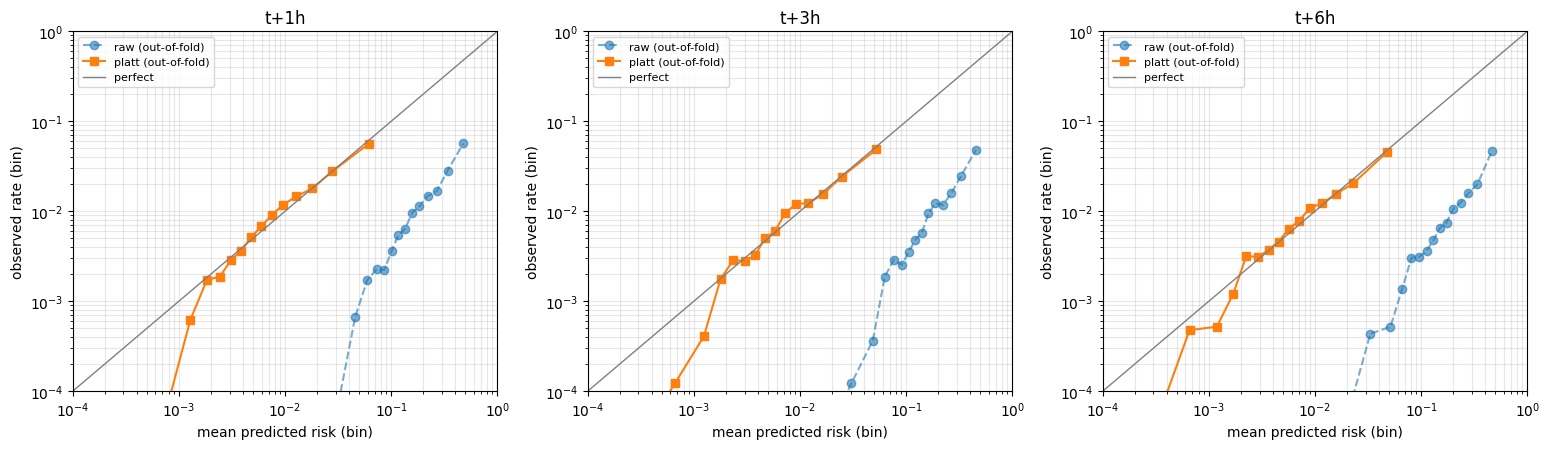

🏃 View run final_train at: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow/#/experiments/1/runs/f766180843d249328da80933c9f96ac6
🧪 View experiment at: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow/#/experiments/1


,stay_id,ICULOS,p_t1,p_t3,p_t6,p_t1_cal,p_t3_cal,p_t6_cal
0,30002498,1,0.369884,0.265119,0.234933,0.032397,0.016317,0.011651
1,30002498,2,0.217338,0.185209,0.181553,0.012472,0.008916,0.007607
2,30002498,3,0.156749,0.153549,0.166134,0.007432,0.006628,0.006606
3,30002498,4,0.155719,0.161320,0.192388,0.007357,0.007159,0.008354
4,30002498,5,0.181989,0.200401,0.255344,0.009374,0.010135,0.013459
5,30002498,6,0.177954,0.197909,0.255901,0.009049,0.009929,0.013510
6,30002498,7,0.168446,0.194215,0.238816,0.008305,0.009629,0.011983
7,30002498,8,0.176104,0.213213,0.230400,0.008902,0.011227,0.011270


calibrator saved: /content/drive/MyDrive/sepsis_softmax_pass3/v3/final_i0pe1e0ema0ah0/calibration/calibrator.json | refit it (do not reuse) whenever the checkpoint changes; re-check on EXT before any clinical-style threshold is set.


In [21]:
# ============================ CELL 12 — PROBABILITY CALIBRATION (post-hoc, fitted on VAL logits; the model itself is unchanged) ============================
# Why the v1 numbers looked "weird" (p ~ 0.65–0.85 in the first ICU hours while only ~1% of hours are positive): focal loss with alpha ~ 0.99
# up-weights positives ~90x and down-weights easy negatives, so the network's sigmoid output is a ranking score, not a probability
# (focal loss is not a strictly proper scoring rule). AUROC only uses the ranking, so it was fine; the probability scale was not.
# Fix: a monotone map from logit to probability, fitted on held-out VAL rows. Platt and the prior shift are strictly monotone, so AUROC is unchanged;
# isotonic is monotone but piecewise-constant (ties), so it can move AUROC by a hair. Calibration is checked out-of-sample by stay-level cross-fitting.
CAL_DIR = os.path.join(FINAL_DIR, "calibration"); os.makedirs(CAL_DIR, exist_ok=True)
_sig = lambda z: 1.0 / (1.0 + np.exp(-np.clip(z, -40, 40)))
_lgt = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))

def fit_cal(method, z, y):
    z = np.asarray(z, np.float64); y = np.asarray(y, np.float64)
    if method == "raw": return {}
    if method == "prior":                                   # one intercept shift: fixes calibration-in-the-large only
        f = lambda b: log_loss(y, np.clip(_sig(z + b), 1e-7, 1 - 1e-7), labels=[0, 1])
        r = optimize.minimize_scalar(f, bounds=(-30, 30), method="bounded"); return {"b": float(r.x)}
    if method == "platt":                                   # logistic recalibration a*z + b (Platt 1999), unpenalised
        def nll(ab):
            a, b = ab; s = a * z + b
            return float(np.mean(np.logaddexp(0, s) - y * s))
        def grad(ab):
            a, b = ab; r_ = _sig(a * z + b) - y; return np.array([np.mean(r_ * z), np.mean(r_)])
        r = optimize.minimize(nll, x0=np.array([1.0, _lgt(np.array([y.mean()]))[0] - float(np.median(z))]), jac=grad, method="L-BFGS-B")
        return {"a": float(r.x[0]), "b": float(r.x[1])}
    if method == "isotonic":
        ir = IsotonicRegression(out_of_bounds="clip", y_min=1e-6, y_max=1 - 1e-6).fit(z, y)
        return {"x": ir.X_thresholds_.tolist(), "y": ir.y_thresholds_.tolist()}
    raise ValueError(method)

def apply_cal_1d(method, p, z):
    z = np.asarray(z, np.float64)
    if method == "raw": return np.clip(_sig(z), 1e-6, 1 - 1e-6)
    if method == "prior": return np.clip(_sig(z + p["b"]), 1e-6, 1 - 1e-6)
    if method == "platt": return np.clip(_sig(p["a"] * z + p["b"]), 1e-6, 1 - 1e-6)
    if method == "isotonic": return np.clip(np.interp(z, p["x"], p["y"]), 1e-6, 1 - 1e-6)

def cal_report(y, p, n_bins):
    y = np.asarray(y, np.float64); p = np.asarray(p, np.float64)
    q = np.quantile(p, np.linspace(0, 1, n_bins + 1)); b = np.clip(np.searchsorted(q, p, side="right") - 1, 0, n_bins - 1)
    cnt = np.bincount(b, minlength=n_bins); mp = np.bincount(b, p, n_bins) / np.maximum(cnt, 1); my = np.bincount(b, y, n_bins) / np.maximum(cnt, 1)
    ece = float(np.sum(cnt * np.abs(mp - my)) / cnt.sum())
    lp = _lgt(p); A = np.c_[np.ones_like(lp), lp]
    def nll(w): s = A @ w; return float(np.mean(np.logaddexp(0, s) - y * s))
    w = optimize.minimize(nll, x0=np.array([0.0, 1.0]), method="L-BFGS-B").x
    return dict(brier=float(brier_score_loss(y, p)), logloss=float(log_loss(y, p, labels=[0, 1])), ece=ece,
                cal_slope=float(w[1]), mean_pred=float(p.mean()), obs_rate=float(y.mean()), max_pred=float(p.max()),
                auroc=float(roc_auc_score(y, p)) if 0 < y.sum() < len(y) else float("nan")), (mp, my, cnt)

# ---- out-of-fold (cross-fitted) evaluation of every method ----
METHODS = ["raw", "prior", "platt", "isotonic"]
_stays = STORE.ids[ROWS_VAL]; _u = np.unique(_stays)
_perm = np.random.default_rng(CFG.SEED + 5).permutation(len(_u)); _fold_of = dict(zip(_u[_perm].tolist(), (np.arange(len(_u)) % CFG.CAL_FOLDS).tolist()))
FOLD = np.array([_fold_of[s] for s in _stays.tolist()])
OOF = {m: [] for m in METHODS}; REL = {}; recs = []
for k, h in enumerate(HORIZONS):
    v = STORE.V[ROWS_VAL, k]; z = LG_VAL[v, k].astype(np.float64); y = STORE.Y[ROWS_VAL, k][v].astype(np.float64); f = FOLD[v]
    for m in METHODS:
        p_oof = np.empty_like(z)
        for fo in range(CFG.CAL_FOLDS):
            tr, te = f != fo, f == fo
            p_oof[te] = apply_cal_1d(m, fit_cal(m, z[tr], y[tr]), z[te])
        rep, rel = cal_report(y, p_oof, CFG.CAL_BINS); REL[(m, h)] = rel
        recs.append(dict(horizon=f"t+{h}", method=m, **rep))
CAL_TABLE = pd.DataFrame(recs)
_show(CAL_TABLE.round(5))

chosen = CFG.CAL_METHOD
if chosen == "auto":
    chosen = CAL_TABLE[CAL_TABLE["method"] != "raw"].groupby("method")["logloss"].mean().idxmin()
print(f"\ncalibration method: {chosen}  (auto = lowest mean out-of-fold log loss over the 3 horizons)")
print("read: brier/logloss/ece lower = better; cal_slope 1 = ideal (<1 over-confident spread, >1 under-confident); mean_pred should match obs_rate.")

# ---- final calibrator on ALL VAL rows (what deployment / the causal stage uses) ----
CALIBRATOR = dict(method=chosen, per_h=[], horizons=HORIZONS, fitted_on="VAL (all stays)", flags=FEATURE_FLAGS, ckpt=CKPT)
for k, h in enumerate(HORIZONS):
    v = STORE.V[ROWS_VAL, k]
    CALIBRATOR["per_h"].append(fit_cal(chosen, LG_VAL[v, k], STORE.Y[ROWS_VAL, k][v]))
CAL_PATH = os.path.join(CAL_DIR, "calibrator.json"); json.dump(CALIBRATOR, open(CAL_PATH, "w"))
CAL_TABLE.to_csv(os.path.join(CAL_DIR, "calibration_table.csv"), index=False)

# ---- reliability diagrams (log-log, since every probability of interest is < 10%) ----
fig, axes = plt.subplots(1, H, figsize=(5.2 * H, 4.6))
for k, h in enumerate(HORIZONS):
    ax = axes[k]
    for m, style in (("raw", dict(marker="o", ls="--", alpha=0.6)), (chosen, dict(marker="s", ls="-"))):
        mp, my, cnt = REL[(m, h)]; keep = cnt > 0
        ax.plot(np.clip(mp[keep], 1e-5, 1), np.clip(my[keep], 1e-5, 1), label=f"{m} (out-of-fold)", **style)
    ax.plot([1e-5, 1], [1e-5, 1], color="grey", lw=1, label="perfect")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-4, 1); ax.set_ylim(1e-4, 1)
    ax.set_title(f"t+{h}h"); ax.set_xlabel("mean predicted risk (bin)"); ax.set_ylabel("observed rate (bin)"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout(); _rel_png = os.path.join(CAL_DIR, "reliability.png"); plt.savefig(_rel_png, dpi=130); plt.show()

with safe_run(run_id=FINAL_RUN_ID):
    m_params({"calibration_method": chosen})
    for r in recs:
        if r["method"] in ("raw", chosen): m_metrics({f"cal_{r['method']}_{r['horizon'].replace('+', '')}_{k_}": r[k_] for k_ in ("brier", "logloss", "ece", "cal_slope", "mean_pred")})
    m_artifact(CAL_PATH, "calibration"); m_artifact(_rel_png, "calibration"); m_artifact(os.path.join(CAL_DIR, "calibration_table.csv"), "calibration")

# ---- the same kind of table as before, now with calibrated risks next to the raw scores ----
try:
    _demo = predict_dataframe(MODEL2, PRE2, load_raw_stays(PARITY_IDS[:1]), calibrator=CALIBRATOR)
    _show(_demo.head(8))
except Exception as e:
    print("[demo skipped]", type(e).__name__, str(e)[:200])
print("calibrator saved:", CAL_PATH, "| refit it (do not reuse) whenever the checkpoint changes; re-check on EXT before any clinical-style threshold is set.")

### 13 · Correlational study (slide 7: P1–P4) — **fixed in v3**
**The v2 error:** the shuffled-label control model was trained with `ckpt_dir=correlation/shuffled_label_model`, a folder that was never created, so `torch.save` failed with *Parent directory … does not exist* after its first epoch and the whole cell stopped. v3 creates the folder (and `save_checkpoint` now creates parent folders itself), and a failing control is reported and skipped instead of killing the study.
P1 clr-transformed attention (pre-softmax logits, so the normaliser cancels) · P2 norm-weighted contribution α·‖v W_O‖ · P3 per-stay OLS → DerSimonian–Laird random-effects pooling (+ stay-bootstrap CI), standardized b1, SESOI + TOST · P4 untrained, shuffled-label, circular-shift, donor and random-projection controls defining the noise floor. Heads are ranked on DISCOVERY and confirmed on SCREEN (disjoint subject halves of VAL).
Note for v3: if the final model uses the auxiliary forecasting head, the shuffled-label control is trained with the same head (same recipe, labels destroyed), so the control band also absorbs anything the forecasting task alone puts into attention.

gate: VAL AUROC 0.8073 (target 0.85) | AUPRC lift over base rate per horizon [6.2, 6.4, 6.2]
severity (SOFA_total) coverage on VAL rows: 100.0%
eligible VAL stays (>= 24 h, severity varies): 5,346 -> DISCOVERY 800 | SCREEN 800 (disjoint subjects)
[shuffled-label] params=24,271,291 items/epoch=13,705 steps/epoch=429 bs=32 lr=2.53e-05 | focal(a=0.878, g=1.0) aux_w=0.05 eng=0 ema=0.0 | select=auroc_mean soup_k=0
[shuffled-label] ep00 loss=0.0635 aux=0.275 val_loss=0.1748 | AUROC 0.5075 AUPRC 0.0108 (t1/t3/t6 0.556/0.489/0.477) | lr 2.26e-05 | 25s
[shuffled-label] ep01 loss=0.0558 aux=0.218 val_loss=0.1687 | AUROC 0.4682 AUPRC 0.0094 (t1/t3/t6 0.438/0.521/0.446) | lr 1.39e-05 | 26s
[shuffled-label] ep02 loss=0.0545 aux=0.208 val_loss=0.1663 | AUROC 0.4834 AUPRC 0.0095 (t1/t3/t6 0.505/0.454/0.491) | lr 4.50e-06 | 27s
[shuffled-label] ep03 loss=0.0542 aux=0.206 val_loss=0.1779 | AUROC 0.4743 AUPRC 0.0092 (t1/t3/t6 0.468/0.479/0.476) | lr 5.05e-07 | 29s
🏃 View run corr_shuffled_label_model at

,layer,head,b1_disc,lo_disc,hi_disc,tau2,I2,boot_lo_disc,boot_hi_disc,n_stays,...,hi_screen,ctrl_untrained:real,ctrl_shuffled_label:real,ctrl_trained:circ_shift,ctrl_trained:donor,ctrl_trained:rand_proj,beyond_band,pass_disc,confirmed_screen,equivalent_to_0
26,4,3,-0.2676,-0.2950,-0.2402,0.1548,0.9948,-0.2964,-0.2371,799.0,...,-0.2466,-0.2464,-0.0935,0.0790,-0.0135,0.1379,False,False,True,False
25,4,2,-0.2388,-0.2613,-0.2162,0.1045,0.9938,-0.2621,-0.2164,799.0,...,-0.2005,0.1626,0.3953,0.0891,0.0431,0.0409,False,False,True,False
3,1,4,-0.2126,-0.2341,-0.1911,0.0945,0.9901,-0.2353,-0.1875,799.0,...,-0.2023,0.1801,0.1624,0.0233,-0.0345,0.0074,False,False,True,False
13,2,6,0.2018,0.1835,0.2201,0.0686,0.9924,0.1839,0.2194,799.0,...,0.1962,0.2036,0.1942,-0.0445,-0.0260,0.1086,False,False,True,False
0,1,1,0.1766,0.1585,0.1948,0.0677,0.9929,0.1568,0.1960,799.0,...,0.2097,-0.2082,0.2361,-0.0628,-0.0436,-0.0796,False,False,True,False
12,2,5,0.1559,0.1355,0.1763,0.0860,0.9948,0.1356,0.1761,799.0,...,0.1901,-0.1891,0.4027,-0.0528,-0.0527,0.0994,False,False,True,False
4,1,5,0.1397,0.1184,0.1610,0.0929,0.9906,0.1146,0.1615,799.0,...,0.1485,-0.1796,0.2759,-0.0132,0.0395,0.1116,False,False,True,False
27,4,4,-0.1351,-0.1642,-0.1061,0.1740,0.9951,-0.1637,-0.1064,799.0,...,-0.1272,0.2085,0.3697,0.0510,-0.0723,-0.0126,False,False,True,False
31,4,8,-0.1284,-0.1583,-0.0985,0.1850,0.9959,-0.1559,-0.1008,799.0,...,-0.1149,-0.1035,0.1815,0.0533,-0.0669,-0.1353,False,False,True,False
28,4,5,-0.1171,-0.1469,-0.0873,0.1835,0.9956,-0.1453,-0.0859,799.0,...,-0.0834,0.0008,0.1476,0.0653,0.0178,-0.0770,False,False,True,False



[normw] control band (P95 of |pooled control b1|) = 0.3354 | decision threshold = max(band, SESOI 0.05) = 0.3354
  heads passing on DISCOVERY: 0/32 | of those confirmed on SCREEN: 0 | equivalent to zero (TOST): 8


,layer,head,b1_disc,lo_disc,hi_disc,tau2,I2,boot_lo_disc,boot_hi_disc,n_stays,...,hi_screen,ctrl_untrained:real,ctrl_shuffled_label:real,ctrl_trained:circ_shift,ctrl_trained:donor,ctrl_trained:rand_proj,beyond_band,pass_disc,confirmed_screen,equivalent_to_0
26,4,3,-0.2628,-0.2902,-0.2353,0.1554,0.9947,-0.2909,-0.2326,799.0,...,-0.2405,-0.2324,-0.0844,0.0758,-0.0165,0.1339,False,False,True,False
25,4,2,-0.2364,-0.2590,-0.2138,0.1055,0.9937,-0.2604,-0.2133,799.0,...,-0.1970,0.1476,0.4089,0.0889,0.0419,0.0399,False,False,True,False
3,1,4,-0.1994,-0.2207,-0.1782,0.0922,0.9901,-0.2221,-0.1742,799.0,...,-0.1902,0.2060,0.1996,0.0206,-0.0426,0.0045,False,False,True,False
13,2,6,0.1990,0.1806,0.2174,0.0695,0.9925,0.1812,0.2170,799.0,...,0.1957,0.1576,0.1812,-0.0432,-0.0273,0.1097,False,False,True,False
0,1,1,0.1765,0.1584,0.1947,0.0677,0.9930,0.1575,0.1959,799.0,...,0.2077,-0.1038,0.2472,-0.0606,-0.0452,-0.0826,False,False,True,False
12,2,5,0.1565,0.1361,0.1769,0.0857,0.9948,0.1358,0.1770,799.0,...,0.1909,-0.2214,0.3959,-0.0539,-0.0532,0.0955,False,False,True,False
4,1,5,0.1483,0.1275,0.1692,0.0888,0.9906,0.1243,0.1690,799.0,...,0.1547,-0.0563,0.2768,-0.0140,0.0320,0.1097,False,False,True,False
31,4,8,-0.1295,-0.1597,-0.0993,0.1881,0.9960,-0.1569,-0.1012,799.0,...,-0.1143,-0.0938,0.1612,0.0533,-0.0690,-0.1379,False,False,True,False
1,1,2,0.1206,0.1020,0.1392,0.0707,0.9921,0.1012,0.1406,799.0,...,0.1362,0.2568,0.1887,-0.0605,-0.0506,-0.0846,False,False,True,False
27,4,4,-0.1197,-0.1487,-0.0906,0.1739,0.9951,-0.1472,-0.0914,799.0,...,-0.1123,0.2086,0.3269,0.0486,-0.0783,-0.0172,False,False,True,False



clr vs norm-weighted pooled b1 across heads: Spearman 0.999 | sign agreement 100.0%
VIF: {'severity': np.float64(1.02), 'log_recency': np.float64(1.23), 'log_pool': np.float64(1.22), 'density': np.float64(1.03), 'deviation_resid': np.float64(1.01)} (> 5 would need a re-specification before the causal stage)

heads carried to the causal stage (layer, head, b1 DISCOVERY -> SCREEN, confirmed):
  none: no head beats the control band on DISCOVERY. Report this; it is a valid null at the screening stage.


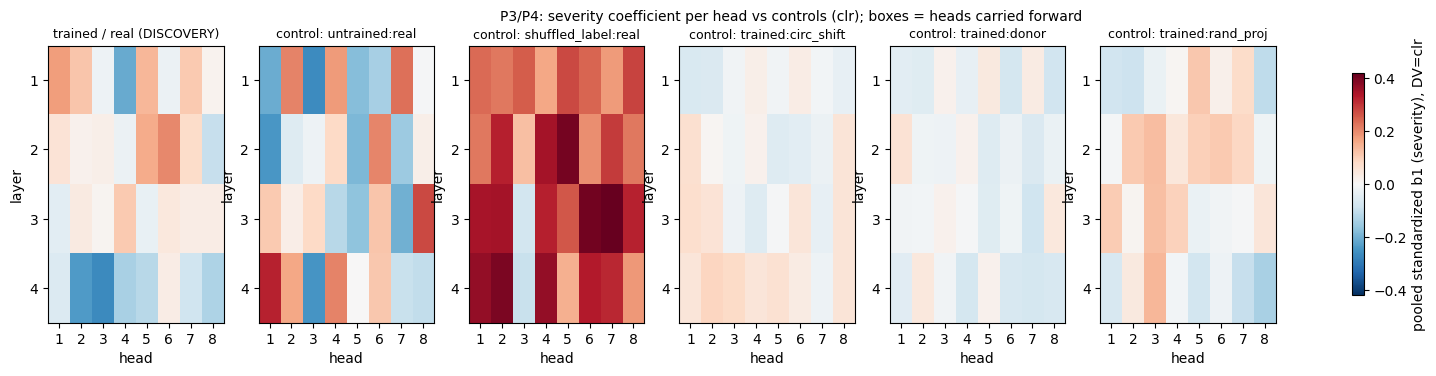

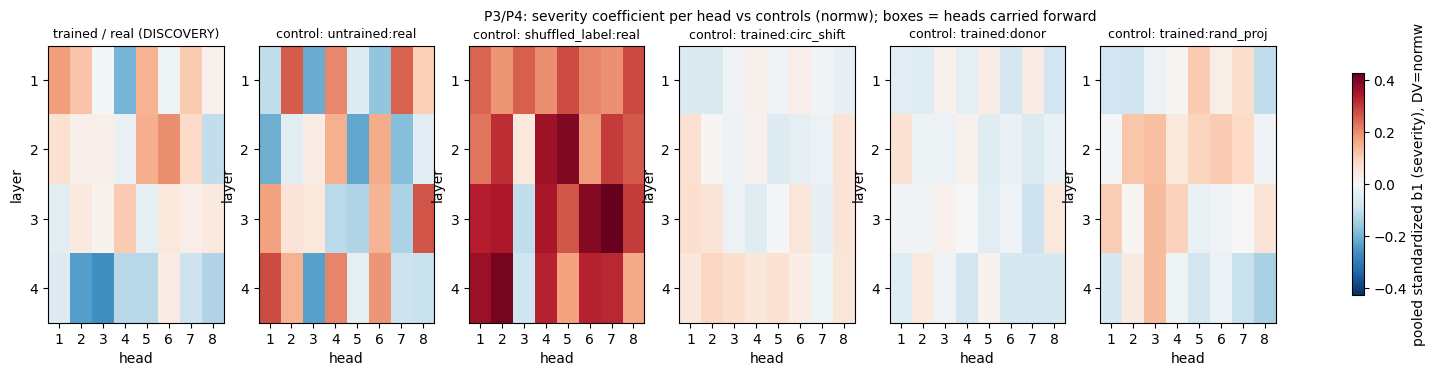

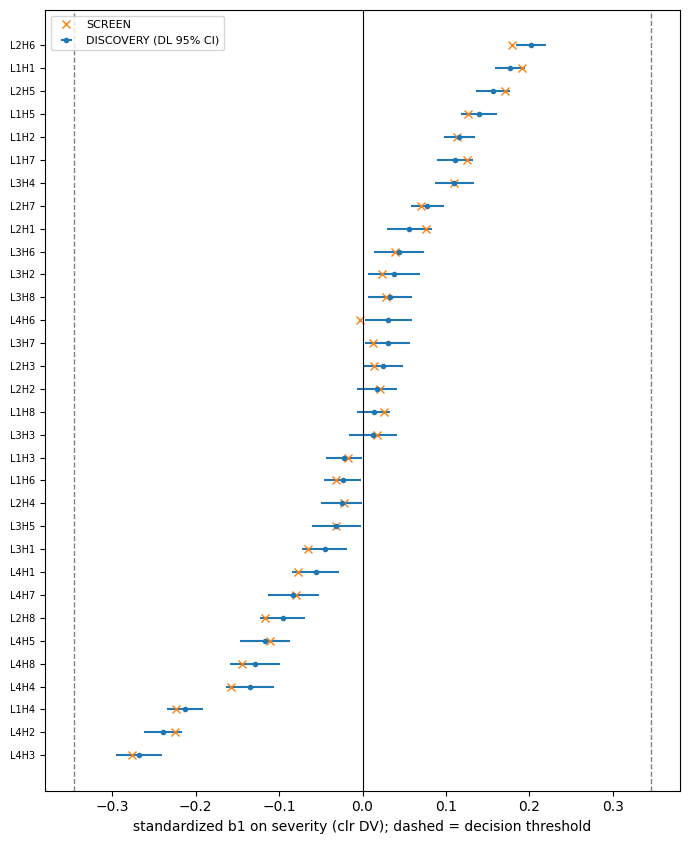

[mlflow] start_run failed (MlflowException: API request to https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow/api/2.0/mlflow/runs/create failed with timeou) [1/3]
saved: /content/drive/MyDrive/sepsis_softmax_pass3/v3/final_i0pe1e0ema0ah0/correlation


61528

In [22]:
# ============================ CELL 13 — CORRELATIONAL STUDY (PDF slide 7: P1 attention DV · P2 norm-weighted · P3 two-stage regression · P4 controls) ============================
# Scope: screening only. It (i) checks the model is non-degenerate, (ii) sets the noise floor with controls, (iii) picks heads worth intervening on.
# It cannot support ABC by itself: any monotone model + softmax renormalisation can produce a positive severity coefficient (PDF §1).
# Data: VAL stays only, split by SUBJECT into DISCOVERY (rank heads) and SCREEN (confirm). LOC/CONF/EXT are never touched here.
# Sign convention (pre-registered): DV = clr(alpha)_tj = z_tj - mean_{i<=t} z_ti  ->  b1 > 0 means MORE attention to MORE severe hours.
# v3 FIX: the v2 cell crashed when it trained the shuffled-label control: its checkpoint folder (correlation/shuffled_label_model) was never
# created, so torch.save() raised "Parent directory ... does not exist" after the first epoch. The folder is now created (and save_checkpoint
# creates parent folders itself). The cell is also hardened: missing severity column -> clear message; too few eligible stays -> clear message;
# a control model that fails is skipped (reported) instead of killing the whole study; capture batch size is configurable.
CORR_DIR = os.path.join(FINAL_DIR, "correlation"); os.makedirs(CORR_DIR, exist_ok=True)
rng_c = np.random.default_rng(CFG.SEED + 13)

# ---------- 0) gate first (P4) ----------
_lift = [FINAL_METRICS[f"auprc_t{h}"] / max(FINAL_METRICS[f"pos_rate_t{h}"], 1e-9) for h in HORIZONS]
print(f"gate: VAL AUROC {FINAL_METRICS['auroc_mean']:.4f} (target {CFG.AUROC_GATE}) | AUPRC lift over base rate per horizon {[round(x, 1) for x in _lift]}")
if not gate_ok:
    msg = "AUROC gate NOT met: per the pre-registered rule the model should be improved before interpretability runs."
    if CFG.CORR_REQUIRE_GATE: raise RuntimeError(msg)
    print("WARNING:", msg, "Running anyway (CFG.CORR_REQUIRE_GATE=False) -> treat every result below as provisional.")

# ---------- 1) analysis-only covariates for VAL rows (severity is NEVER a model input) ----------
_names = pq.read_schema(CFG.DATA_PATH).names
try: SEV_COL = _resolve(CFG.CORR_SEVERITY_COL, _names)
except KeyError: raise KeyError(f"severity column '{CFG.CORR_SEVERITY_COL}' not in the parquet; set CFG.CORR_SEVERITY_COL to one of: {[c for c in _names if 'SOFA' in c.upper()] or _names}")
_val_ids = np.unique(STORE.ids[STORE.starts[VAL_IDX]])
aux = pd.read_parquet(CFG.DATA_PATH, columns=[CFG.ID_COL, CFG.SUBJECT_COL, CFG.HOUR_COL, "HoursToOnset", SEV_COL],
                      filters=[(CFG.ID_COL, "in", [int(i) for i in _val_ids])])
aux = aux[aux["HoursToOnset"].isna() | (aux["HoursToOnset"] >= 0)].copy()
aux[CFG.HOUR_COL] = aux[CFG.HOUR_COL].astype(np.int64)
aux = aux.sort_values([CFG.ID_COL, CFG.HOUR_COL]).drop_duplicates([CFG.ID_COL, CFG.HOUR_COL])
aux["sev"] = aux.groupby(CFG.ID_COL)[SEV_COL].ffill()                                          # causal fill within stay
aux["sev"] = aux["sev"].fillna(aux.groupby(CFG.ID_COL)["sev"].transform("median")).fillna(0.0)
_vrows = np.concatenate([np.arange(STORE.starts[i], STORE.starts[i] + STORE.lens[i]) for i in VAL_IDX])
_key = pd.DataFrame({CFG.ID_COL: STORE.ids[_vrows], CFG.HOUR_COL: STORE.hours[_vrows].astype(np.int64), "row": _vrows})
_mrg = _key.merge(aux[[CFG.ID_COL, CFG.HOUR_COL, "sev"]], on=[CFG.ID_COL, CFG.HOUR_COL], how="left")
SEV = np.full(STORE.n_rows, np.nan, np.float32); SEV[_mrg["row"].to_numpy()] = _mrg["sev"].to_numpy(np.float32)
print(f"severity ({SEV_COL}) coverage on VAL rows: {np.isfinite(SEV[_vrows]).mean():.1%}")
STAY_SUBJ = aux.groupby(CFG.ID_COL)[CFG.SUBJECT_COL].first().to_dict()

# ---------- 2) DISCOVERY / SCREEN split by subject; eligible stays ----------
def win(i):
    l = int(STORE.lens[i]); n = min(l, CFG.MAX_SEQ_LEN); a = int(STORE.starts[i]) + l - n; return a, n
_elig = []
for i in VAL_IDX:
    a, n = win(i); s = SEV[a:a + n]
    if n >= CFG.CORR_MIN_LEN and np.isfinite(s).all() and np.std(s) > 1e-6: _elig.append(int(i))
_elig = np.array(_elig)
_subj = np.array([STAY_SUBJ.get(int(STORE.ids[STORE.starts[i]]), -1) for i in _elig])
_us = rng_c.permutation(np.unique(_subj)); _disc_subj = set(_us[: len(_us) // 2].tolist())
_is_disc = np.array([s in _disc_subj for s in _subj])
SPLITS = {}
for nm, msk in (("DISCOVERY", _is_disc), ("SCREEN", ~_is_disc)):
    pool = _elig[msk]; SPLITS[nm] = np.sort(rng_c.choice(pool, size=min(len(pool), CFG.CORR_N_STAYS), replace=False))
print(f"eligible VAL stays (>= {CFG.CORR_MIN_LEN} h, severity varies): {len(_elig):,} -> DISCOVERY {len(SPLITS['DISCOVERY'])} | SCREEN {len(SPLITS['SCREEN'])} (disjoint subjects)")
if min(len(v) for v in SPLITS.values()) < 3:
    raise RuntimeError(f"too few eligible VAL stays for the two-stage regression (need >= 3 per split, got {[len(v) for v in SPLITS.values()]}); "
                       "lower CFG.CORR_MIN_LEN or check severity coverage above")

# ---------- 3) per-stay hour-level covariates + severity controls (P1 covariates, P4 controls 3–5) ----------
CORE_J = [DECAY_FEATURES.index(c) for c in ENG_CORE]
W_RP = np.random.default_rng(CFG.SEED + 99).standard_normal(len(DECAY_FEATURES))           # one fixed random projection for every stay
def _resid(y, x):
    A = np.c_[np.ones_like(x), x]; return y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
def stay_info(i, donor_pool):
    a, n = win(i); sid = int(STORE.ids[STORE.starts[i]]); r = np.random.default_rng((CFG.SEED * 1_000_003 + sid) % (2 ** 32))
    sev = SEV[a:a + n].astype(np.float64)
    dens = STORE.M[a:a + n].mean(1).astype(np.float64)
    dev = np.abs(STORE.XL[a:a + n][:, CORE_J]).mean(1).astype(np.float64)
    var = {"real": sev, "circ_shift": np.roll(sev, int(r.integers(n // 4, 3 * n // 4 + 1)))}
    cands = [d for d in donor_pool if d != i and win(d)[1] >= n]
    if cands:
        d = int(r.choice(cands)); da, dn = win(d); var["donor"] = SEV[da + dn - n: da + dn].astype(np.float64)
    rp = STORE.XL[a:a + n].astype(np.float64) @ W_RP
    var["rand_proj"] = np.sort(sev)[np.argsort(np.argsort(rp, kind="stable"), kind="stable")]      # rank-matched to this stay's severity marginal
    ts = np.arange(CFG.CORR_MIN_T, n)
    ts = np.sort(r.choice(ts, size=min(len(ts), CFG.CORR_Q_PER_STAY), replace=False))
    tt = np.repeat(ts, ts + 1); jj = np.concatenate([np.arange(t + 1) for t in ts])
    return dict(a=a, n=n, sid=sid, var=var, dens=dens, dev=dev, tt=tt, jj=jj)
INFO = {nm: {int(i): stay_info(int(i), SPLITS[nm]) for i in SPLITS[nm]} for nm in SPLITS}
COV_NAMES = ["severity", "log_recency", "log_pool", "density", "deviation_resid"]

def design(inf, variant):
    s = inf["var"].get(variant)
    if s is None: return None
    tt, jj = inf["tt"], inf["jj"]
    devr = _resid(inf["dev"], s)                     # pre-registered rule: deviation residualised on (the analysed) severity, within stay
    return np.c_[s[jj], np.log(tt - jj + 1.0), np.log(tt + 1.0), inf["dens"][jj], devr[jj]]
# NOTE on time terms: ICULOS_t is NOT added. Inside one stay ICULOS_t = position_t + constant, so it is perfectly collinear with log_pool / the
# position terms in a per-stay regression (PDF P1); the stay-level constant is absorbed by per-stay fitting.

def stay_ols(Xc, Y):
    """Xc (P,p) covariates, Y (P,K) DVs -> standardized b1 (K,) and its OLS SE (K,). Both sides standardized within stay."""
    mu, sd = Xc.mean(0), Xc.std(0)
    if sd[0] < 1e-8: return np.full(Y.shape[1], np.nan), np.full(Y.shape[1], np.nan)
    Xs = np.where(sd > 1e-8, (Xc - mu) / np.where(sd > 1e-8, sd, 1.0), 0.0)
    ysd = Y.std(0); Ys = (Y - Y.mean(0)) / np.where(ysd > 1e-8, ysd, np.nan)
    A = np.c_[np.ones(len(Xs)), Xs]; Gi = np.linalg.pinv(A.T @ A)
    Ysf = np.nan_to_num(Ys); B = Gi @ (A.T @ Ysf); R = Ysf - A @ B
    dof = max(1, len(A) - np.linalg.matrix_rank(A)); se = np.sqrt((R ** 2).sum(0) / dof * Gi[1, 1])
    b1 = np.where(ysd > 1e-8, B[1], np.nan); return b1, np.where(ysd > 1e-8, se, np.nan)

# ---------- 4) attention capture (fp32, dropout off): pre-softmax logits z and per-head ||v_j W_O^(h)|| ----------
@torch.no_grad()
def capture(model, stay_idx, bs=None):
    bs = bs or CFG.CORR_CAPTURE_BATCH
    model.eval(); loader, _ = make_loader(STORE, stay_idx, bs, False)
    a2i = {win(int(i))[0]: int(i) for i in stay_idx}
    mhas = [layer.MultiHeadAttention for layer in model.core.encoder.layers]
    for b in loader:
        b = to_dev(b)
        model(b["X"], b["M"], b["D"], b["XL"], b["S"], b["G"], b["hrs"], b["E"], build_attn_mask(b["PAD"]))
        Z = torch.stack([m.attention_logits.float() for m in mhas], 1)                         # (B,L,nh,T,T)
        VN = []
        for m in mhas:
            d_ = m.W_O.weight.shape[0]; Wr = m.W_O.weight.float().view(d_, m.num_heads, m.head_dim)
            VN.append(torch.einsum("bhtk,dhk->bhtd", m.Value.float(), Wr).norm(dim=-1))          # (B,nh,T)
        VN = torch.stack(VN, 1)                                                               # (B,L,nh,T)
        n_real = (~b["PAD"]).sum(1).tolist(); first = b["ROW"][:, 0].tolist()
        for bi in range(len(n_real)):
            n = n_real[bi]
            yield a2i[int(first[bi])], Z[bi, :, :, :n, :n].cpu().numpy(), VN[bi, :, :, :n].cpu().numpy()
        release_attn_cache(model)

def dvs_for_stay(z, vn, inf):
    L_, nh_, n, _ = z.shape; tt, jj = inf["tt"], inf["jj"]
    tri = np.tril(np.ones((n, n), bool)); cnt = np.arange(1, n + 1, dtype=np.float64)
    zf = np.where(tri, z, 0.0).astype(np.float64); rowmean = zf.sum(-1) / cnt                 # (L,nh,n)
    clr = (zf[:, :, tt, jj] - rowmean[:, :, tt]).reshape(L_ * nh_, -1).T                       # P1: clr(alpha) = z - mean z  (Z cancels)
    lv = np.log(np.maximum(vn.astype(np.float64), 1e-12)); cml = np.cumsum(lv, -1) / cnt
    nw = clr + (lv[:, :, jj] - cml[:, :, tt]).reshape(L_ * nh_, -1).T                          # P2: log(alpha*||vW_O||), row-centred
    return {"clr": clr, "normw": nw}

def run_model(model, split, variants):
    out = {(v, dv): ([], []) for v in variants for dv in ("clr", "normw")}
    for i, z, vn in capture(model, SPLITS[split]):
        inf = INFO[split][i]; D_ = dvs_for_stay(z, vn, inf)
        for v in variants:
            Xc = design(inf, v)
            if Xc is None: continue
            for dv, Y in D_.items():
                b1, se = stay_ols(Xc, Y); out[(v, dv)][0].append(b1); out[(v, dv)][1].append(se)
    return {k: (np.array(b), np.array(s)) for k, (b, s) in out.items() if len(b)}

# ---------- 5) models: trained + controls (P4 controls 1–2) ----------
MODELS = {"trained": MODEL2}
seed_everything(CFG.SEED + 777)
_unt = build_model(CK["hp"], PRE2.x_mean).to(DEVICE).eval(); MODELS["untrained"] = _unt
if CFG.CORR_TRAIN_SHUFFLED:
    shuf_dir = os.path.join(CORR_DIR, "shuffled_label_model"); shuf_ck = os.path.join(shuf_dir, "best.pt")
    os.makedirs(shuf_dir, exist_ok=True)                                                         # <- the v2 crash: this folder did not exist
    if CFG.ALLOW_RESUME and os.path.exists(shuf_ck) and torch.load(shuf_ck, map_location="cpu", weights_only=False).get("cfg", {}).get("RUN_NAME") == CFG.RUN_NAME:
        MODELS["shuffled_label"], _, _ = load_pipeline(shuf_ck); print("[shuffled-label] loaded", shuf_ck)
    else:
        STORE_SHUF = types.SimpleNamespace(**vars(STORE)); Yp = STORE.Y.copy(); _r = np.random.default_rng(CFG.SEED + 3)
        _fitrows = np.flatnonzero(np.repeat(np.isin(np.arange(len(STORE.starts)), FIT_IDX), STORE.lens))
        for k in range(H):
            vi = _fitrows[STORE.V[_fitrows, k]]; Yp[vi, k] = STORE.Y[_r.permutation(vi), k]     # labels permuted across FIT rows, prevalence kept
        STORE_SHUF.Y = Yp; _pr_ = ((Yp == 1) & STORE.V).any(1)
        STORE_SHUF.pos_cs = np.concatenate([[0], np.cumsum(_pr_.astype(np.int64))])
        STORE_SHUF.stay_has_pos = np.add.reduceat(_pr_.astype(np.int64), STORE.starts) > 0
        _sfit = np.sort(_r.choice(FIT_IDX, size=max(1, int(CFG.CORR_SHUF_FIT_FRACTION * len(FIT_IDX))), replace=False))
        try:
            with safe_run("corr_shuffled_label_model", tags={"stage": "correlation_control", "run": CFG.RUN_NAME}):
                # same recipe as the trained model (incl. the auxiliary head if it has one), labels destroyed; no soup (a control, not a contender)
                _res = fit(CK["hp"], STORE_SHUF, _sfit, VAL_IDX, max_epochs=CFG.CORR_SHUF_EPOCHS, patience=CFG.CORR_SHUF_EPOCHS + 1,
                           ckpt_dir=shuf_dir, seed=CFG.SEED + 5, log_prefix="[shuffled-label] ", soup_k=0)
            MODELS["shuffled_label"] = _res["model"].eval(); del _res
        except Exception as e:
            print(f"[shuffled-label] control FAILED ({type(e).__name__}: {str(e)[:200]}) -> continuing without it; the band uses the other controls")
            traceback.print_exc(limit=3)
        del STORE_SHUF, Yp; gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

RUNS = {}
t0 = time.time()
RUNS[("trained", "DISCOVERY")] = run_model(MODELS["trained"], "DISCOVERY", ["real", "circ_shift", "donor", "rand_proj"])
RUNS[("trained", "SCREEN")] = run_model(MODELS["trained"], "SCREEN", ["real"])
for nm in ("untrained", "shuffled_label"):
    if nm in MODELS: RUNS[(nm, "DISCOVERY")] = run_model(MODELS[nm], "DISCOVERY", ["real"])
print(f"capture + per-stay regressions done in {time.time() - t0:.0f}s")

# ---------- 6) stage 2: DerSimonian–Laird random-effects meta-analysis across stays (P3) ----------
def dl_meta(b, se):
    K = b.shape[1]; out = {k_: np.full(K, np.nan) for k_ in ("est", "se", "lo", "hi", "tau2", "I2", "k", "mean", "boot_lo", "boot_hi")}
    for k in range(K):
        ok = np.isfinite(b[:, k]) & np.isfinite(se[:, k]) & (se[:, k] > 0); bb, ss = b[ok, k], se[ok, k]
        if len(bb) < 3: continue
        w = 1 / ss ** 2; fe = np.sum(w * bb) / w.sum(); Q = np.sum(w * (bb - fe) ** 2); dfq = len(bb) - 1
        tau2 = max(0.0, (Q - dfq) / (w.sum() - np.sum(w ** 2) / w.sum())); ws = 1 / (ss ** 2 + tau2)
        est = np.sum(ws * bb) / ws.sum(); sei = np.sqrt(1 / ws.sum())
        out["est"][k], out["se"][k], out["lo"][k], out["hi"][k] = est, sei, est - 1.96 * sei, est + 1.96 * sei
        out["tau2"][k], out["I2"][k], out["k"][k] = tau2, (max(0.0, (Q - dfq) / Q) if Q > 0 else 0.0), len(bb)
        # robustness: plain mean with a stay-bootstrap CI (no assumption that the hour-pairs inside a stay are independent)
        bm = np.random.default_rng(k).integers(0, len(bb), (1000, len(bb)))
        out["mean"][k] = bb.mean(); out["boot_lo"][k], out["boot_hi"][k] = np.percentile(bb[bm].mean(1), [2.5, 97.5])
    return out

L_N = len(MODEL2.core.encoder.layers); NH_N = MODEL2.core.encoder.layers[0].MultiHeadAttention.num_heads
HEAD_LBL = [(l + 1, h + 1) for l in range(L_N) for h in range(NH_N)]
META = {(m, s, v, dv): dl_meta(*res) for (m, s), r in RUNS.items() for (v, dv), res in r.items()}
CONTROL_KEYS = [("untrained", "DISCOVERY", "real"), ("shuffled_label", "DISCOVERY", "real"),
                ("trained", "DISCOVERY", "circ_shift"), ("trained", "DISCOVERY", "donor"), ("trained", "DISCOVERY", "rand_proj")]

def tost_p(est, se, delta):
    return np.maximum(1 - stats.norm.cdf((est + delta) / se), stats.norm.cdf((est - delta) / se))

TABLES = {}
for dv in ("clr", "normw"):
    disc = META[("trained", "DISCOVERY", "real", dv)]; scr = META[("trained", "SCREEN", "real", dv)]
    ctrl = {f"{m}:{v}": META[(m, s, v, dv)]["est"] for (m, s, v) in CONTROL_KEYS if (m, s, v, dv) in META}
    band = float(np.nanpercentile(np.abs(np.concatenate(list(ctrl.values()))), CFG.CORR_BAND_Q)) if ctrl else float("nan")
    thr = max(band, CFG.CORR_SESOI) if np.isfinite(band) else CFG.CORR_SESOI
    t = pd.DataFrame({"layer": [l for l, _ in HEAD_LBL], "head": [h for _, h in HEAD_LBL],
                      "b1_disc": disc["est"], "lo_disc": disc["lo"], "hi_disc": disc["hi"], "tau2": disc["tau2"], "I2": disc["I2"],
                      "boot_lo_disc": disc["boot_lo"], "boot_hi_disc": disc["boot_hi"], "n_stays": disc["k"],
                      "b1_screen": scr["est"], "lo_screen": scr["lo"], "hi_screen": scr["hi"],
                      **{f"ctrl_{k_}": v_ for k_, v_ in ctrl.items()}})
    t["beyond_band"] = np.abs(t["b1_disc"]) > thr
    t["pass_disc"] = t["beyond_band"] & ((t["lo_disc"] > 0) | (t["hi_disc"] < 0)) & ((t["boot_lo_disc"] > 0) | (t["boot_hi_disc"] < 0))
    t["confirmed_screen"] = (np.sign(t["b1_screen"]) == np.sign(t["b1_disc"])) & (np.abs(t["b1_screen"]) > CFG.CORR_SESOI) & ((t["lo_screen"] > 0) | (t["hi_screen"] < 0))
    t["equivalent_to_0"] = tost_p(t["b1_disc"].to_numpy(), disc["se"], CFG.CORR_SESOI) < 0.05
    t.attrs.update(band=band, threshold=thr); TABLES[dv] = t
    print(f"\n[{dv}] control band (P{CFG.CORR_BAND_Q:.0f} of |pooled control b1|) = {band:.4f} | decision threshold = max(band, SESOI {CFG.CORR_SESOI}) = {thr:.4f}")
    print(f"  heads passing on DISCOVERY: {int(t['pass_disc'].sum())}/{len(t)} | of those confirmed on SCREEN: {int((t['pass_disc'] & t['confirmed_screen']).sum())} | "
          f"equivalent to zero (TOST): {int(t['equivalent_to_0'].sum())}")
    _show(t.sort_values("b1_disc", key=np.abs, ascending=False).head(12).round(4))

# agreement between the two DVs (Jain & Wallace warning: weight and contribution can disagree)
_a, _b = TABLES["clr"]["b1_disc"].to_numpy(), TABLES["normw"]["b1_disc"].to_numpy(); _ok = np.isfinite(_a) & np.isfinite(_b)
print(f"\nclr vs norm-weighted pooled b1 across heads: Spearman {stats.spearmanr(_a[_ok], _b[_ok])[0]:.3f} | sign agreement {np.mean(np.sign(_a[_ok]) == np.sign(_b[_ok])):.1%}")

# VIF on the trained/real DISCOVERY design (P1 collinearity check)
_Xs = []
for i in list(INFO["DISCOVERY"])[:200]:
    Xc = design(INFO["DISCOVERY"][i], "real"); sd_ = Xc.std(0); _Xs.append(np.where(sd_ > 1e-8, (Xc - Xc.mean(0)) / np.where(sd_ > 1e-8, sd_, 1), 0))
_Xs = np.concatenate(_Xs); _vif = []
for c in range(_Xs.shape[1]):
    o = np.delete(_Xs, c, 1); A = np.c_[np.ones(len(o)), o]; r_ = _Xs[:, c] - A @ np.linalg.lstsq(A, _Xs[:, c], rcond=None)[0]
    r2 = 1 - r_.var() / max(_Xs[:, c].var(), 1e-12); _vif.append(1 / max(1 - r2, 1e-6))
print("VIF:", dict(zip(COV_NAMES, np.round(_vif, 2))), "(> 5 would need a re-specification before the causal stage)")

# ---------- 7) heads carried forward (rank on DISCOVERY, confirm on SCREEN; primary DV = clr) ----------
T = TABLES["clr"]
_rank = T[T["pass_disc"]].sort_values("b1_disc", key=np.abs, ascending=False).head(CFG.CORR_TOP_K)
SELECTED_HEADS = [dict(layer=int(r.layer), head=int(r.head), b1_disc=float(r.b1_disc), b1_screen=float(r.b1_screen),
                       confirmed=bool(r.confirmed_screen), normw_b1_disc=float(TABLES["normw"].loc[r.Index, "b1_disc"])) for r in _rank.itertuples()]
print("\nheads carried to the causal stage (layer, head, b1 DISCOVERY -> SCREEN, confirmed):")
for s_ in SELECTED_HEADS: print(f"  L{s_['layer']} H{s_['head']}: {s_['b1_disc']:+.3f} -> {s_['b1_screen']:+.3f}  {'CONFIRMED' if s_['confirmed'] else 'not confirmed'}")
if not SELECTED_HEADS: print("  none: no head beats the control band on DISCOVERY. Report this; it is a valid null at the screening stage.")
if any(s_["layer"] == 1 for s_ in SELECTED_HEADS):
    print("  reminder: layer-1 keys depend only on their own hour, so intervention effects on OTHER hours cannot appear before layer 2 (PDF P1).")

# ---------- 8) figures + artifacts ----------
for dv in ("clr", "normw"):
    t = TABLES[dv]; panels = [("trained / real (DISCOVERY)", t["b1_disc"].to_numpy())] + [(c.replace("ctrl_", "control: "), t[c].to_numpy()) for c in t.columns if c.startswith("ctrl_")]
    vmax = np.nanmax([np.nanmax(np.abs(p)) for _, p in panels] + [CFG.CORR_SESOI])
    fig, axes = plt.subplots(1, len(panels), figsize=(3.3 * len(panels), 0.45 * L_N + 1.8), squeeze=False)
    for ax, (ttl, vals) in zip(axes[0], panels):
        im = ax.imshow(vals.reshape(L_N, NH_N), cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
        ax.set_title(ttl, fontsize=9); ax.set_xlabel("head"); ax.set_ylabel("layer")
        ax.set_xticks(range(NH_N)); ax.set_xticklabels(range(1, NH_N + 1)); ax.set_yticks(range(L_N)); ax.set_yticklabels(range(1, L_N + 1))
    for s_ in SELECTED_HEADS: axes[0][0].add_patch(plt.Rectangle((s_["head"] - 1.5, s_["layer"] - 1.5), 1, 1, fill=False, ec="k", lw=2))
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label=f"pooled standardized b1 (severity), DV={dv}")
    fig.suptitle(f"P3/P4: severity coefficient per head vs controls ({dv}); boxes = heads carried forward", fontsize=10)
    _p = os.path.join(CORR_DIR, f"heads_{dv}.png"); plt.savefig(_p, dpi=130, bbox_inches="tight"); plt.show()
    t.to_csv(os.path.join(CORR_DIR, f"head_table_{dv}.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 0.22 * len(T) + 1.5))
o = np.argsort(T["b1_disc"].to_numpy()); yy = np.arange(len(T))
ax.errorbar(T["b1_disc"].to_numpy()[o], yy, xerr=[T["b1_disc"].to_numpy()[o] - T["lo_disc"].to_numpy()[o], T["hi_disc"].to_numpy()[o] - T["b1_disc"].to_numpy()[o]], fmt="o", ms=3, label="DISCOVERY (DL 95% CI)")
ax.plot(T["b1_screen"].to_numpy()[o], yy, "x", label="SCREEN")
for x_ in (-T.attrs["threshold"], T.attrs["threshold"]): ax.axvline(x_, color="grey", ls="--", lw=1)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(yy); ax.set_yticklabels([f"L{T['layer'].iloc[i]}H{T['head'].iloc[i]}" for i in o], fontsize=7)
ax.set_xlabel("standardized b1 on severity (clr DV); dashed = decision threshold"); ax.legend(fontsize=8)
_pf = os.path.join(CORR_DIR, "forest_clr.png"); plt.tight_layout(); plt.savefig(_pf, dpi=130); plt.show()

CORR_SUMMARY = dict(severity_col=SEV_COL, n_disc=len(SPLITS["DISCOVERY"]), n_screen=len(SPLITS["SCREEN"]), sesoi=CFG.CORR_SESOI,
                    band_clr=TABLES["clr"].attrs["band"], band_normw=TABLES["normw"].attrs["band"], vif=dict(zip(COV_NAMES, map(float, _vif))),
                    selected_heads=SELECTED_HEADS, gate_auroc=FINAL_METRICS["auroc_mean"], gate_ok=bool(gate_ok), flags=FEATURE_FLAGS,
                    discovery_stays=[int(STORE.ids[STORE.starts[i]]) for i in SPLITS["DISCOVERY"]], screen_stays=[int(STORE.ids[STORE.starts[i]]) for i in SPLITS["SCREEN"]])
_js = os.path.join(CORR_DIR, "correlational_summary.json"); json.dump(CORR_SUMMARY, open(_js, "w"), indent=1, default=float)
with safe_run("correlational_study", tags={"stage": "correlational", "study": STUDY_FULL, "run": CFG.RUN_NAME}):
    m_params(dict(sesoi=CFG.CORR_SESOI, band_q=CFG.CORR_BAND_Q, n_stays=CFG.CORR_N_STAYS, q_per_stay=CFG.CORR_Q_PER_STAY, severity=SEV_COL, top_k=CFG.CORR_TOP_K))
    m_metrics({"band_clr": TABLES["clr"].attrs["band"], "band_normw": TABLES["normw"].attrs["band"], "n_heads_pass_disc": int(TABLES["clr"]["pass_disc"].sum()),
               "n_heads_confirmed": int((TABLES["clr"]["pass_disc"] & TABLES["clr"]["confirmed_screen"]).sum())})
    for f_ in os.listdir(CORR_DIR):
        if f_.endswith((".csv", ".png", ".json")): m_artifact(os.path.join(CORR_DIR, f_), "correlation")
print("saved:", CORR_DIR)
del _unt; gc.collect()

### 14 · Reference ceiling (optional): LightGBM on the same causal per-hour features
Answers "is 0.85 reachable on these labels at all?" and gives a second ICULOS test. Not used for the attention analysis.

In [23]:
# ============================ CELL 14 — REFERENCE CEILING (optional): gradient-boosted trees on the SAME causal per-hour features ============================
# Why: LightGBM/XGBoost on hand-built per-hour features is the strongest family on PhysioNet-2019-style data. If trees on these exact rows
# and labels also stay well below 0.85, the gap is the task (MIMIC-IV Sepsis-3 onset, 6 h lead, post-onset rows dropped), not the Transformer.
# It also answers the ICULOS question a second, independent way (with vs without ICULOS columns).
# Constraints kept: FIT rows only for training, VAL for early stopping + scoring, natural class distribution (no SMOTE, no row/bagging subsampling,
# no class weights). Reference only -- never used in the attention analysis.
if CFG.RUN_GBDT_REFERENCE:
    import lightgbm as lgb
    def row_matrix(stay_idx, with_iculos):
        rows = np.concatenate([np.arange(STORE.starts[i], STORE.starts[i] + STORE.lens[i]) for i in stay_idx])
        parts = [STORE.XL[rows], STORE.M[rows], np.log1p(np.minimum(STORE.D[rows], 240.0)).astype(np.float32), STORE.E[rows].astype(np.float32),
                 STORE.S[rows], STORE.G[rows].astype(np.float32)[:, None]]
        names = [f"{c}_ffill" for c in DECAY_FEATURES] + [f"{c}_obs" for c in DECAY_FEATURES] + [f"{c}_hrs_since" for c in DECAY_FEATURES] + ENG_NAMES + ["age", "hospadm", "unit1", "unit2", "gender"]
        if with_iculos: parts.append(np.log1p(STORE.hours[rows])[:, None].astype(np.float32)); names.append("log_iculos")
        return rows, np.concatenate(parts, 1), names
    GBDT = {}
    for with_iculos in (False, True):
        tag = "with_ICULOS" if with_iculos else "no_ICULOS"
        r_fit, X_fit, names = row_matrix(FIT_IDX, with_iculos); r_val, X_val, _ = row_matrix(VAL_IDX, with_iculos)
        scores = np.zeros((len(r_val), H), np.float32)
        for k, h in enumerate(HORIZONS):
            mf = STORE.V[r_fit, k]; mv = STORE.V[r_val, k]
            dtr = lgb.Dataset(X_fit[mf], STORE.Y[r_fit[mf], k].astype(np.float32), feature_name=names, free_raw_data=True)
            dva = lgb.Dataset(X_val[mv], STORE.Y[r_val[mv], k].astype(np.float32), reference=dtr)
            params = dict(objective="binary", metric="auc", learning_rate=0.03, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.7,
                          lambda_l2=1.0, bagging_fraction=1.0, max_bin=255, verbose=-1, seed=CFG.SEED,
                          device_type="cpu", num_threads=os.cpu_count())
            bst = lgb.train(params, dtr, num_boost_round=CFG.GBDT_ROUNDS, valid_sets=[dva], callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(500)])
            scores[:, k] = bst.predict(X_val, num_iteration=bst.best_iteration)
            if k == 0:
                imp = pd.Series(bst.feature_importance("gain"), index=names).sort_values(ascending=False)
                print(f"[GBDT {tag}] top features t+1:", ", ".join(f"{n_}" for n_ in imp.index[:12]))
        # score on exactly the rows the Transformer is scored on (most recent 168 h window) -> like-for-like AUROC
        pos = {r: i for i, r in enumerate(r_val.tolist())}; sc_aligned = scores[[pos[r] for r in ROWS_VAL.tolist()]]
        GBDT[tag] = sc_aligned; met = compute_metrics(STORE, ROWS_VAL, sc_aligned)
        _sg = subgroup_metrics(STORE, ROWS_VAL, sc_aligned)
        print(f"[GBDT {tag}] late rows AUROC {_sg['late_rows_auroc_mean']:.4f} | no early-onset stays AUROC {_sg['no_early_onset_auroc_mean']:.4f}")
        print(f"[GBDT {tag}] VAL AUROC t1/t3/t6 {met['auroc_t1']:.4f}/{met['auroc_t3']:.4f}/{met['auroc_t6']:.4f} | mean {met['auroc_mean']:.4f} | AUPRC {met['auprc_mean']:.4f}")
        del X_fit, X_val, r_fit, r_val; gc.collect()
    d_, lo_, hi_ = stay_bootstrap_dauroc(ROWS_VAL, GBDT["no_ICULOS"], GBDT["with_ICULOS"], CFG.ABL_BOOT, seed=CFG.SEED + 2)
    print(f"[GBDT] ICULOS effect: dAUROC {d_:+.4f} (95% CI {lo_:+.4f}..{hi_:+.4f})")
    d2, lo2, hi2 = stay_bootstrap_dauroc(ROWS_VAL, GBDT["with_ICULOS"], LG_VAL, CFG.ABL_BOOT, seed=CFG.SEED + 3)
    print(f"[Transformer primary vs GBDT with_ICULOS] dAUROC {d2:+.4f} (95% CI {lo2:+.4f}..{hi2:+.4f})  (positive = Transformer better)")
    with safe_run("gbdt_reference", tags={"stage": "reference"}):
        for tag, sc in GBDT.items(): m_metrics({f"gbdt_{tag}_{k_}": v_ for k_, v_ in compute_metrics(STORE, ROWS_VAL, sc).items()})
else:
    print("GBDT reference skipped (CFG.RUN_GBDT_REFERENCE=False)")

[GBDT no_ICULOS] top features t+1: FiO2_hrs_since, hospadm, Resp_mean6h, WBC_ffill, age, PTT_ffill, Glucose_ffill, Platelets_ffill, log_bun_cr, Hgb_ffill, Hct_ffill, PaCO2_hrs_since
[GBDT no_ICULOS] late rows AUROC 0.7722 | no early-onset stays AUROC 0.7369
[GBDT no_ICULOS] VAL AUROC t1/t3/t6 0.7873/0.7634/0.7475 | mean 0.7661 | AUPRC 0.0347
[500]	valid_0's auc: 0.779504
[GBDT with_ICULOS] top features t+1: FiO2_hrs_since, hospadm, WBC_ffill, PTT_ffill, age, Resp_mean6h, log_bun_cr, Glucose_ffill, Hct_ffill, Phosphate_ffill, Platelets_ffill, Hgb_ffill
[GBDT with_ICULOS] late rows AUROC 0.7728 | no early-onset stays AUROC 0.7377
[GBDT with_ICULOS] VAL AUROC t1/t3/t6 0.7863/0.7632/0.7498 | mean 0.7664 | AUPRC 0.0345
[GBDT] ICULOS effect: dAUROC +0.0004 (95% CI -0.0027..+0.0034)
[Transformer primary vs GBDT with_ICULOS] dAUROC +0.0408 (95% CI +0.0278..+0.0536)  (positive = Transformer better)
[mlflow] start_run failed (Exception: Run with UUID 2e22f52511e248d79246e17e687276a1 is already a